# **Loan Prediction Based on Customer Behavior**

  - This project is the final project assignment from the Rakamin Data Science bootcamp that I am taking, where we are required to go through the end-to-end process of a data science project analyzing factors influencing the default (failure to pay) of a lending company.

  - After the project is completed and presented to the panelists, who are highly experienced experts in the field of data science and business, I personally carry out further improvements based on their suggestions and feedback for this project.

  - I also translate the original version in Indonesian language to English so that non-Indonesian could understand.

> **Evaluation correction (2026):** The original run applied SMOTE to the whole training set *before* cross-validation, which inflated the reported recall. The evaluation section now keeps those CV cells as a labelled diagnostic and adds a real holdout plus a leak-free CV (SMOTE inside folds). Re-run the notebook to refresh all numbers; any output still shown for a replaced cell is from the original run.


# **STAGE 0 : BUSINESS UNDERSTANDING**

## 📌 Problem Statement

A lending company needs to verify loan applications from its prospective borrowers (customers). The manual verification procedure conducted by the company has resulted in numerous inaccurate assessments, leading to loans being granted to borrowers who ultimately fail to repay (default). This has proven detrimental to the company as it incurs financial losses without any return. Additionally, the manual verification process also consumes a considerable amount of time which is not efficient.

Building on this issue, the company aims to develop an automated system that can predict the creditworthiness of prospective borrowers in the future based on past borrower data to reduce the selection of potential customers with high default risks.

## 📌 Role

As a Data Scientist Team, our role involves conducting analysis to gain business insights and designing models that have an impact on business development.

## 📌 Goals

- Enhanced credit risk evaluation: Improve the assessment of credit risk by implementing machine learning models. (**MAIN**)
- Increased efficiency: Streamline the credit risk assessment process for greater effectiveness and reduced processing time. (**SECONDARY**)

## 📌 Objectives

The ultimate goal of this project is to create a machine learning model that can:

- Predict credit risk with a high recall rate. The objective is to reduce the risk of losses due to inaccurate risk assessments.
- Provide automated credit risk assessment decisions in a short amount of time.

## 📌 Business Metrics

* Default Rate (%) : The percentage of prospective customers who fail to repay a loan (default) divided by the total number of customers. (**MAIN**)
* Approval Time : The time taken to process loan applications. (**SECONDARY**)

# **STAGE 1 : EXPLORATORY DATA ANALYSIS (EDA)**

## Import Libraries and Settings

In [1]:
# Import initial necessary libraries
import warnings
warnings.filterwarnings('ignore')

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import joblib

%matplotlib inline

# Settings of dataframe display
pd.options.display.max_columns = 100
pd.options.display.max_colwidth = None

# Set random seed for all numpy random generation methods
np.random.seed(42)

# Version requirements
print('numpy version : ', np.__version__)
print('pandas version : ', pd.__version__)
print('seaborn version : ', sns.__version__)
print('scikit-learn version:', sklearn.__version__)
print('joblib version:', joblib.__version__)


numpy version :  2.4.3
pandas version :  2.3.3
seaborn version :  0.13.2
scikit-learn version: 1.8.0
joblib version: 1.5.3


### Load Dataset (Local Jupyter Notebook)

In [2]:
# Load the dataset from the repository's data/ folder
data_path = os.path.join(os.getcwd(), 'data', 'Training Data.csv')
df = pd.read_csv(data_path)

print(f'Loaded {df.shape[0]:,} rows and {df.shape[1]} columns')

Loaded 252,000 rows and 13 columns


## Data Understanding & Initial Transformation

In [3]:
# Retrieve 10 sample lines from the available data
df.sample(10)

# Checking shape of dataframe
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns {df.shape[1]}')

Number of rows: 252000
Number of columns 13


In [4]:
# Basic data information now comes from the shared utils package
from utils import check_data_information

columns_to_check = df.columns
check_data_information(df, columns_to_check)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,Id,int64,0,0.0,0,0.00,0,0.0,0,0,0,252000,1.0000,"1, 2, 3, 4, 5"
1,Income,int64,0,0.0,0,0.00,0,0.0,0,0,0,41920,0.1663,"1303834, 7574516, 3991815, 6256451, 5768871"
2,Age,int64,0,0.0,0,0.00,0,0.0,0,0,0,59,0.0002,"23, 40, 66, 41, 47"
3,Experience,int64,0,0.0,11043,4.38,0,0.0,0,0,0,21,0.0001,"3, 10, 4, 2, 11"
4,Married/Single,object,0,0.0,0,0.00,0,0.0,0,0,0,2,0.0000,"single, married"
5,House_Ownership,object,0,0.0,0,0.00,0,0.0,0,0,0,3,0.0000,"rented, norent_noown, owned"
6,Car_Ownership,object,0,0.0,0,0.00,0,0.0,0,0,0,2,0.0000,"no, yes"
7,Profession,object,0,0.0,0,0.00,0,0.0,0,0,0,51,0.0002,"Mechanical_engineer, Software_Developer, Technical_writer, Civil_servant, Librarian"
8,CITY,object,0,0.0,0,0.00,0,0.0,0,0,0,317,0.0013,"Rewa, Parbhani, Alappuzha, Bhubaneswar, Tiruchirappalli[10]"
9,STATE,object,0,0.0,0,0.00,0,0.0,0,0,0,29,0.0001,"Madhya_Pradesh, Maharashtra, Kerala, Odisha, Tamil_Nadu"


**Update**:

- In this case we found that there are no missing values atau duplicate values in this dataset because we are using the entire column to check for missing values and duplicates which is distinguished from the Id column. But if we check by excluding the Id column, we will find that this dataset actually have a lot of missing values and duplicates, which we will show below.

- This kind of error could potentially raise from using the wrong join method when merging multiple datasets and not validating the data first.

In [5]:
# Further checking for duplicates
exclude_columns = ['Id']
df[df.duplicated(subset=df.columns.difference(exclude_columns))]

,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
5366,5367,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
5367,5368,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0
5368,5369,6256451,41,2,single,rented,yes,Software_Developer,Bhubaneswar,Odisha,2,12,1
5370,5371,6915937,64,0,single,rented,no,Civil_servant,Jalgaon,Maharashtra,0,12,0
5371,5372,3954973,58,14,married,rented,no,Librarian,Tiruppur,Tamil_Nadu,8,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
215992,215993,9482746,68,10,single,rented,no,Physician,Indore,Madhya_Pradesh,6,11,1
215993,215994,4590372,42,16,single,rented,no,Hotel_Manager,Shahjahanpur,Uttar_Pradesh,7,11,0
215994,215995,4727841,52,8,single,rented,no,Technology_specialist,Tenali,Andhra_Pradesh,8,12,0
215995,215996,5000063,38,17,single,rented,no,Technology_specialist,Yamunanagar,Haryana,5,11,1


We can see that there are actually a lot of duplicated values in this dataset. Let's say for example we take the first row from that data duplicate data:

In [6]:
# Further checking on duplicated values
df[(df["Income"] == 7574516) & (df["Age"] == 40)]

,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
5366,5367,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
10744,10745,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
16165,16166,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
21521,21522,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
32307,32308,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
37701,37702,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
43121,43122,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
48507,48508,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
53924,53925,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0


We will handle this issue by removing the duplicates. Having this many duplicates will affect the accuracy of our model and the quality of our analysis, so we need to remove them.

In [7]:
# Removing found duplicates
df = df.drop_duplicates(subset=df.columns.difference(exclude_columns)).reset_index(drop=True)
df.shape

(43190, 13)

**Feature Information**

| **Feature Name** | **Description** | **Data Type** | **Specific Data Type** |
|----------------- |----------------|--------------|----------------------|
| `Id`             | Unique identifier of the user | Categorical | Nominal |
| `Income`         | Annual income of the user | Numerical | Continuous |
| `Age`            | Age of the user | Numerical | Continuous |
| `Experience`     | Total professional experience in years | Numerical | Continuous |
| `Married/Single` | Marital status of the user | Categorical | Nominal |
| `House_Ownership` | Status of housing ownership | Categorical | Nominal |
| `Car_Ownership`   | Vehicle ownership status | Categorical | Nominal |
| `Profession`      | User's professional occupation | Categorical | Nominal |
| `CITY`            | City of residence | Categorical | Nominal |
| `STATE`           | State of residence | Categorical | Nominal |
| `CURRENT_JOB_YRS` | Years of experience in current job | Numerical | Discrete |
| `CURRENT_HOUSE_YRS` | Years in current residence | Numerical | Discrete |
| `Risk_Flag`       | Loan default status | Categorical | Nominal |

In [8]:
# Grouping columns based on data types (for column iteration later in EDA and others)
nums_cols = ['Income', 'Age', 'Experience', 'Current_Job_Years', 'Current_House_Years']
cats_cols = ['Marital_Status', 'House_Ownership', 'Car_Ownership', 'Profession', 'City', 'State', 'Risk_Flag']

cats_cols_exclude_target = [col for col in cats_cols if col != 'Risk_Flag']

## Initial Feature Transformation

In [9]:
# Rename some columns
df.rename(columns={'CURRENT_JOB_YRS' : 'Current_Job_Years',
                   'CURRENT_HOUSE_YRS' : 'Current_House_Years',
                   'CITY' : 'City',
                   'STATE' : 'State',
                   'Married/Single' : 'Marital_Status'}, inplace=True)

# Drop Id column (because they are initially the same as the index)
df.drop(columns='Id', inplace=True)

# Function to switch the target between 0/1 and its display labels.
def change_target_dtype(data, target_col='Risk_Flag', target_type='numerical'):
    """
    Convert the target between 0/1 and 'No Default'/'Default'.

    The conversion is idempotent, so re-running a cell does not turn already
    converted values into NaN.
    """
    if target_type == 'categorical':
        mapping = {0: 'No Default', 1: 'Default'}
        valid = {'No Default', 'Default'}
    elif target_type == 'numerical':
        mapping = {'No Default': 0, 'Default': 1}
        valid = {0, 1}
    else:
        raise ValueError("target_type must be either 'numerical' or 'categorical'")

    converted = data[target_col].replace(mapping)
    unexpected = set(converted.dropna().unique()) - valid
    if unexpected:
        raise ValueError(
            f"Unexpected {target_col} values: {sorted(map(str, unexpected))}"
        )
    if converted.isna().any():
        raise ValueError(
            f"{target_col} contains missing values; reload the dataset and "
            "run the notebook from the top."
        )
    data[target_col] = converted

change_target_dtype(data=df, target_type='categorical')


In [10]:
# Checking unique values for each categorical columns (for more detail value checking)
for col in cats_cols:
    print()
    print(f"{col}: {df[col].unique()}")


Marital_Status: ['single' 'married']

House_Ownership: ['rented' 'norent_noown' 'owned']

Car_Ownership: ['no' 'yes']

Profession: ['Mechanical_engineer' 'Software_Developer' 'Technical_writer'
 'Civil_servant' 'Librarian' 'Economist' 'Flight_attendant' 'Architect'
 'Designer' 'Physician' 'Financial_Analyst' 'Air_traffic_controller'
 'Politician' 'Police_officer' 'Artist' 'Surveyor' 'Design_Engineer'
 'Chemical_engineer' 'Hotel_Manager' 'Dentist' 'Comedian'
 'Biomedical_Engineer' 'Graphic_Designer' 'Computer_hardware_engineer'
 'Petroleum_Engineer' 'Secretary' 'Computer_operator'
 'Chartered_Accountant' 'Technician' 'Microbiologist' 'Fashion_Designer'
 'Aviator' 'Psychologist' 'Magistrate' 'Lawyer' 'Firefighter' 'Engineer'
 'Official' 'Analyst' 'Geologist' 'Drafter' 'Statistician' 'Web_designer'
 'Consultant' 'Chef' 'Army_officer' 'Surgeon' 'Scientist' 'Civil_engineer'
 'Industrial_Engineer' 'Technology_specialist']

City: ['Rewa' 'Parbhani' 'Alappuzha' 'Bhubaneswar' 'Tiruchirappalli[

The values in profession, state and city have some data anomalies problem where they contains character of square brackets ([ ]), underscore (_), and comma (,). We will need to identify and then clean these values.

In [11]:
# Identify characters in columns_to_clean
columns_to_clean = ['Profession', 'State', 'City']

for col in columns_to_clean:
    print(f"Analyzing column: {col}\n")

    # Check for [] characters
    unique_count_brackets = df[df[col].str.contains('[', regex=False)][col].nunique()
    print(f'Number of unique {col} with []: {unique_count_brackets}')
    print(df[df[col].str.contains('[', regex=False)][col].value_counts(), '\n')

    # Check for _ characters
    unique_count_underscore = df[df[col].str.contains('_', regex=False)][col].nunique()
    print(f'Number of unique {col} with _: {unique_count_underscore}')
    print(df[df[col].str.contains('_', regex=False)][col].value_counts(), '\n')

    print('-' * 50)  # Separator for readability

Analyzing column: Profession

Number of unique Profession with []: 0
Series([], Name: count, dtype: int64) 

Number of unique Profession with _: 23
Profession
Air_traffic_controller        901
Computer_operator             885
Computer_hardware_engineer    885
Police_officer                881
Hotel_Manager                 881
Industrial_Engineer           875
Software_Developer            872
Graphic_Designer              869
Biomedical_Engineer           867
Mechanical_engineer           863
Web_designer                  863
Civil_servant                 861
Civil_engineer                860
Technical_writer              853
Design_Engineer               847
Financial_Analyst             843
Chartered_Accountant          828
Chemical_engineer             824
Flight_attendant              820
Technology_specialist         816
Army_officer                  801
Petroleum_Engineer            791
Fashion_Designer              747
Name: count, dtype: int64 

-------------------------------

In [12]:
# Removing those characters from the 'Profession', 'City', and 'State' column
for col in columns_to_clean:
  df[col] = df[col].str.replace(r'\[\d+\]', '', regex=True)
  df[col] = df[col].str.replace('_', ' ')
  df[col] = df[col].str.replace(',', ' ')

# Rename the format of the values in those columns to title
for col in columns_to_clean:
  df[col] = df[col].str.lower()

The `[n]` suffixes in `Profession`, `State`, and `City` are source-data artefacts. The regex `r'\[\d+\]'` removes them, `_` and `,` become spaces, and values are lower-cased so the same category is not split by formatting.


In [13]:
# Descriptive statistics now come from the shared utils package
from utils import describe_numerical_combined

# Display the overall statistics for numerical columns
describe_numerical_combined(df, nums_cols)

,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,Income,43190.0,4.999184e+06,2.883155e+06,10310.0,2508307.25,4984654.5,7494142.25,9999938.0,9989628.0,4985835.0,57.672514,0.007885,-1.198446
1,Age,43190.0,4.991741e+01,1.705670e+01,21.0,35.00,50.0,65.00,79.0,58.0,30.0,34.169845,0.005897,-1.199431
2,Experience,43190.0,9.975041e+00,6.034418e+00,0.0,5.00,10.0,15.00,20.0,20.0,10.0,60.495176,0.005845,-1.195311
3,Current_Job_Years,43190.0,6.298981e+00,3.663603e+00,0.0,3.00,6.0,9.00,14.0,14.0,6.0,58.161837,0.261364,-0.786562
4,Current_House_Years,43190.0,1.200627e+01,1.412652e+00,10.0,11.00,12.0,13.00,14.0,4.0,2.0,11.765944,-0.006615,-1.297897


Gentle reminder :

- `skewness`: Measures the asymmetry of the probability distribution
- `kurtosis`: Measures the "tailedness" of the probability distribution

The skewness and kurtosis values can help you understand:
- If skewness > 0: Right-skewed distribution
- If skewness < 0: Left-skewed distribution
- If kurtosis > 3: Heavy-tailed distribution (more outliers)
- If kurtosis < 3: Light-tailed distribution (fewer outliers)


In [14]:
# Categorical statistics now come from the shared utils package
from utils import describe_categorical_combined

# Display the overall statistics for categorical columns
describe_categorical_combined(df, cats_cols)

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,Marital_Status,43190,2,single,38830,married,4360,89.91,10.09,2
1,House_Ownership,43190,3,rented,39679,norent_noown,1267,91.87,2.93,3
2,Car_Ownership,43190,2,no,30422,yes,12768,70.44,29.56,2
3,Profession,43190,51,air traffic controller,901,fashion designer,747,2.09,1.73,51
4,City,43190,316,aurangabad,253,rohtak,102,0.59,0.24,316
5,State,43190,28,uttar pradesh,4969,manipur,127,11.50,0.29,28
6,Risk_Flag,43190,2,No Default,34747,Default,8443,80.45,19.55,2


## Descriptive Statistics Findings

- A. All data types are correct, and there are no missing values in this dataset but there are a lot of duplicated values after we check by excluding the Id column.

- B. The column names are generally correct; only a few categorical columns have been renamed for clarity and to standardize the writing format with other columns. Additionally, initial cleaning has been performed on some categorical values.

- C. The statistical summary values for numerical and categorical columns appear normal. However, it is noteworthy that the target variable (Risk_Flag) exhibits a significant class imbalance, which will be addressed further in preprocessing steps (feature sampling).

- > Note : This also gave us an insight into our goal of the project, which is that we need to reduce the number of current default rates (19.55 %).

## Univariate Analysis

### Numerical Columns

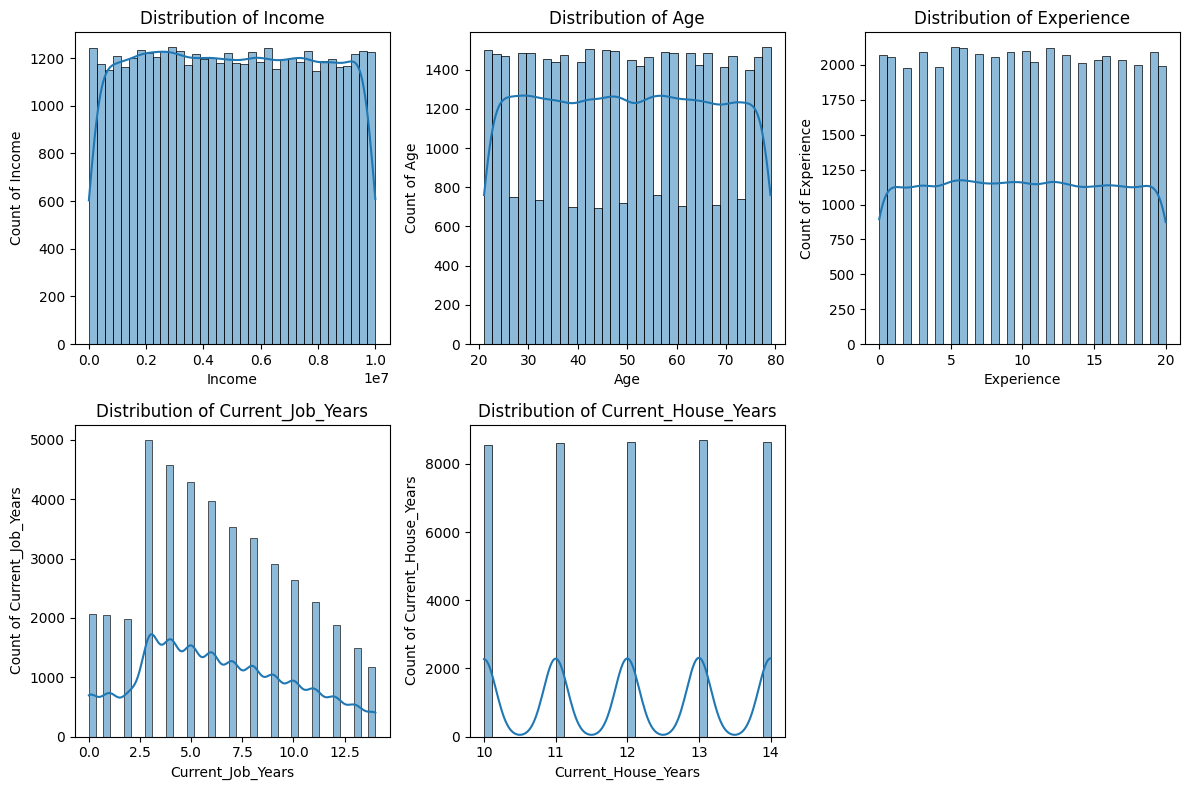

In [15]:
# Distribution plots from the shared utils package
from utils import plot_dynamic_hisplots_kdeplots

plot_dynamic_hisplots_kdeplots(df=df, col_series=nums_cols, ncols=3, figsize=(12, 8))

In [16]:
# Distribution typing from the shared utils package
from utils import identify_distribution_types

columns_to_check = nums_cols
uniform_columns = ['Income', 'Age', 'Experience']
multimodal_columns = ['Current_House_Years']

identify_distribution_types(
    df,
    col_series=columns_to_check,
    uniform_cols=uniform_columns,
    multimodal_cols=multimodal_columns,
)

,Column Name,Mean,Median,Mode,Skewness,Kurtosis,Skewness Type,Kurtosis Type
0,Income,4999184.481,4984654.5,5238806,0.008,-1.198,Uniform Distribution,Platykurtic (Light-tailed)
1,Age,49.917,50.0,79,0.006,-1.199,Uniform Distribution,Platykurtic (Light-tailed)
2,Experience,9.975,10.0,5,0.006,-1.195,Uniform Distribution,Platykurtic (Light-tailed)
3,Current_Job_Years,6.299,6.0,3,0.261,-0.787,Slightly Positively Skewed,Platykurtic (Light-tailed)
4,Current_House_Years,12.006,12.0,13,-0.007,-1.298,Multi-modal Distribution,Platykurtic (Light-tailed)


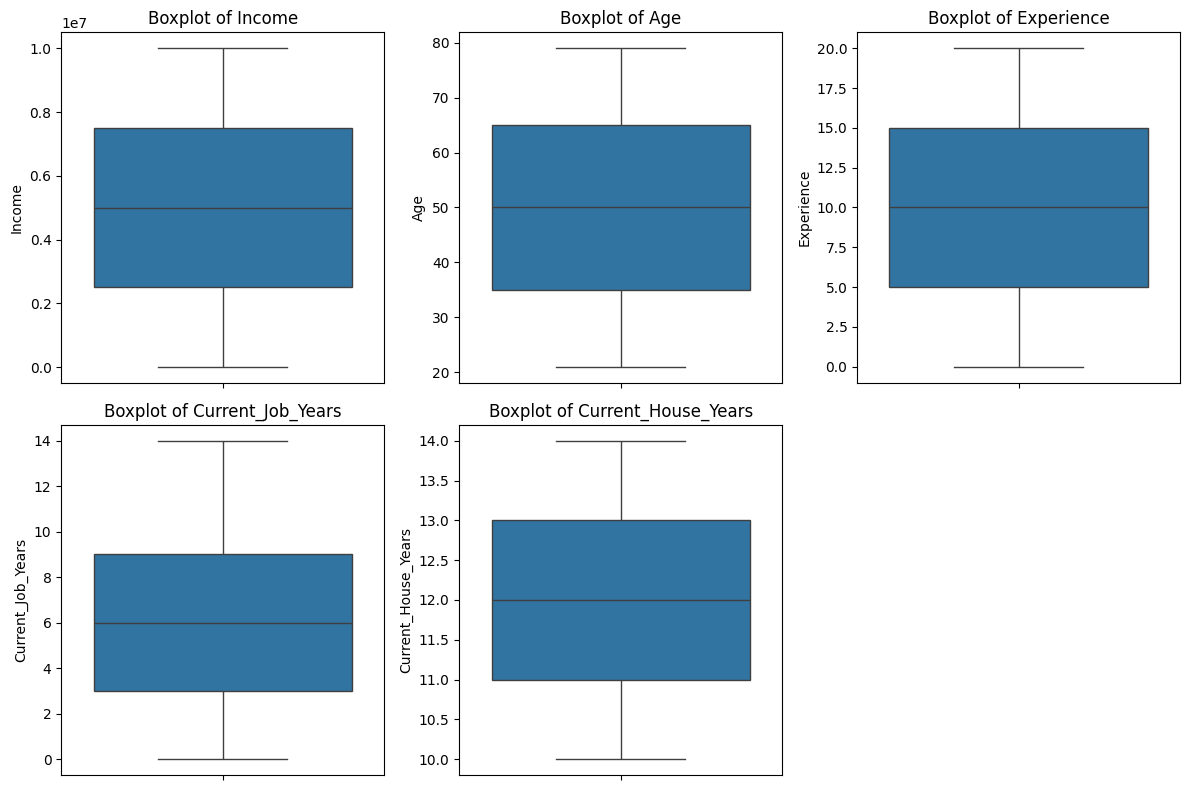

In [17]:
# Boxplot / violin helpers from the shared utils package
from utils import plot_dynamic_boxplots_violinplots

plot_dynamic_boxplots_violinplots(
    df, col_series=nums_cols, ncols=3, figsize=(12, 8), orientation='v'
)

In [18]:
# Outlier detection from the shared utils package
from utils import filter_outliers

outlier_summary = filter_outliers(
    df,
    columns=nums_cols,
    method='zscore',
    threshold=3,
    detect_only=True,
)
outlier_summary

Amount of Rows: 43190
Amount of Outlier Rows (Across All Columns): 0
Amount of Non-Outlier Rows (Across All Columns): 43190
Percentage of Outliers: 0.0%



,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,Income,False,-3.650282e+06,1.364865e+07,0,43190,0.0
1,Age,False,-1.252694e+00,1.010875e+02,0,43190,0.0
2,Experience,False,-8.128215e+00,2.807830e+01,0,43190,0.0
3,Current_Job_Years,False,-4.691828e+00,1.728979e+01,0,43190,0.0
4,Current_House_Years,False,7.768320e+00,1.624423e+01,0,43190,0.0


- We should just check only using IQR since the distribution are mostly not normal, but i did it just to make sure.

- From those result, we know that **our dataset don't have any outliers and we won't be doing any outliers handling here**.

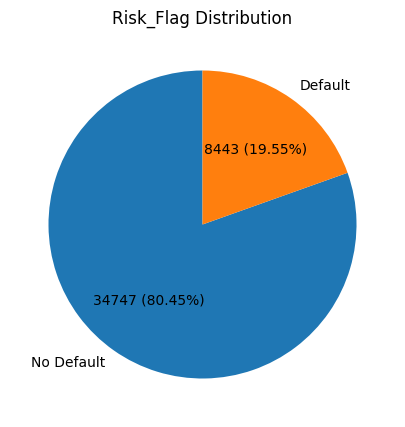

In [19]:
# Risk_Flag Distribution (Combined Pie Chart)
fig, ax = plt.subplots(figsize=(8, 5))
labels = ['No Default', 'Default']
sizes = df['Risk_Flag'].value_counts()

ax.pie(sizes, labels=labels, autopct=lambda p: '{:.0f} ({:.2f}%)'.format(p * sum(sizes) / 100, p), startangle=90)
ax.set_title('Risk_Flag Distribution')
plt.show()

### Categorical Columns

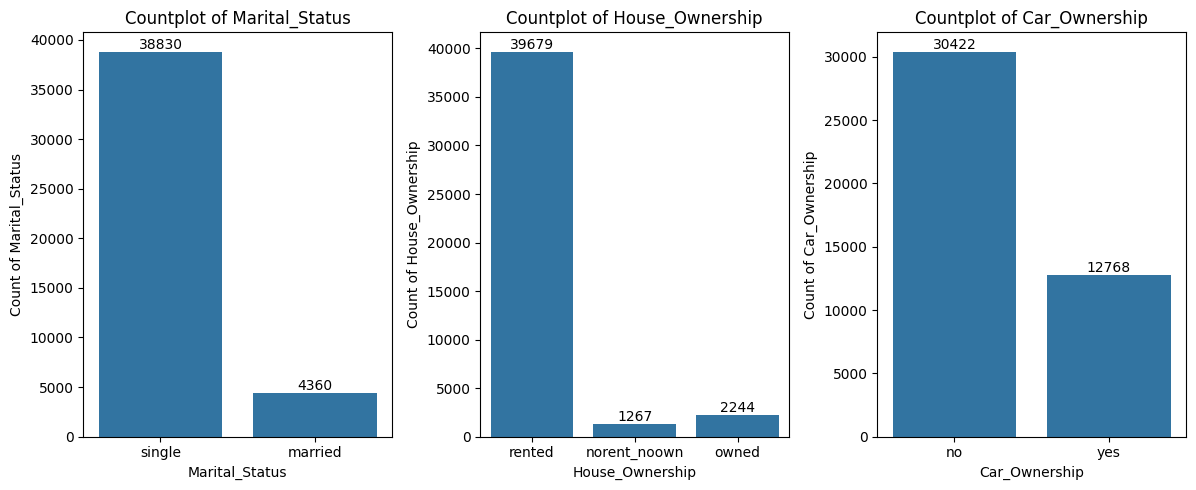

In [20]:
# Countplots from the shared utils package
from utils import plot_dynamic_countplot

cats_few = ['Marital_Status', 'House_Ownership', 'Car_Ownership']
plot_dynamic_countplot(df=df, col_series=cats_few, ncols=5, figsize=(20, 5))

Profession, State, and City are too many to be plotted altogether since they have many unique values, so we will only look at the top 10.

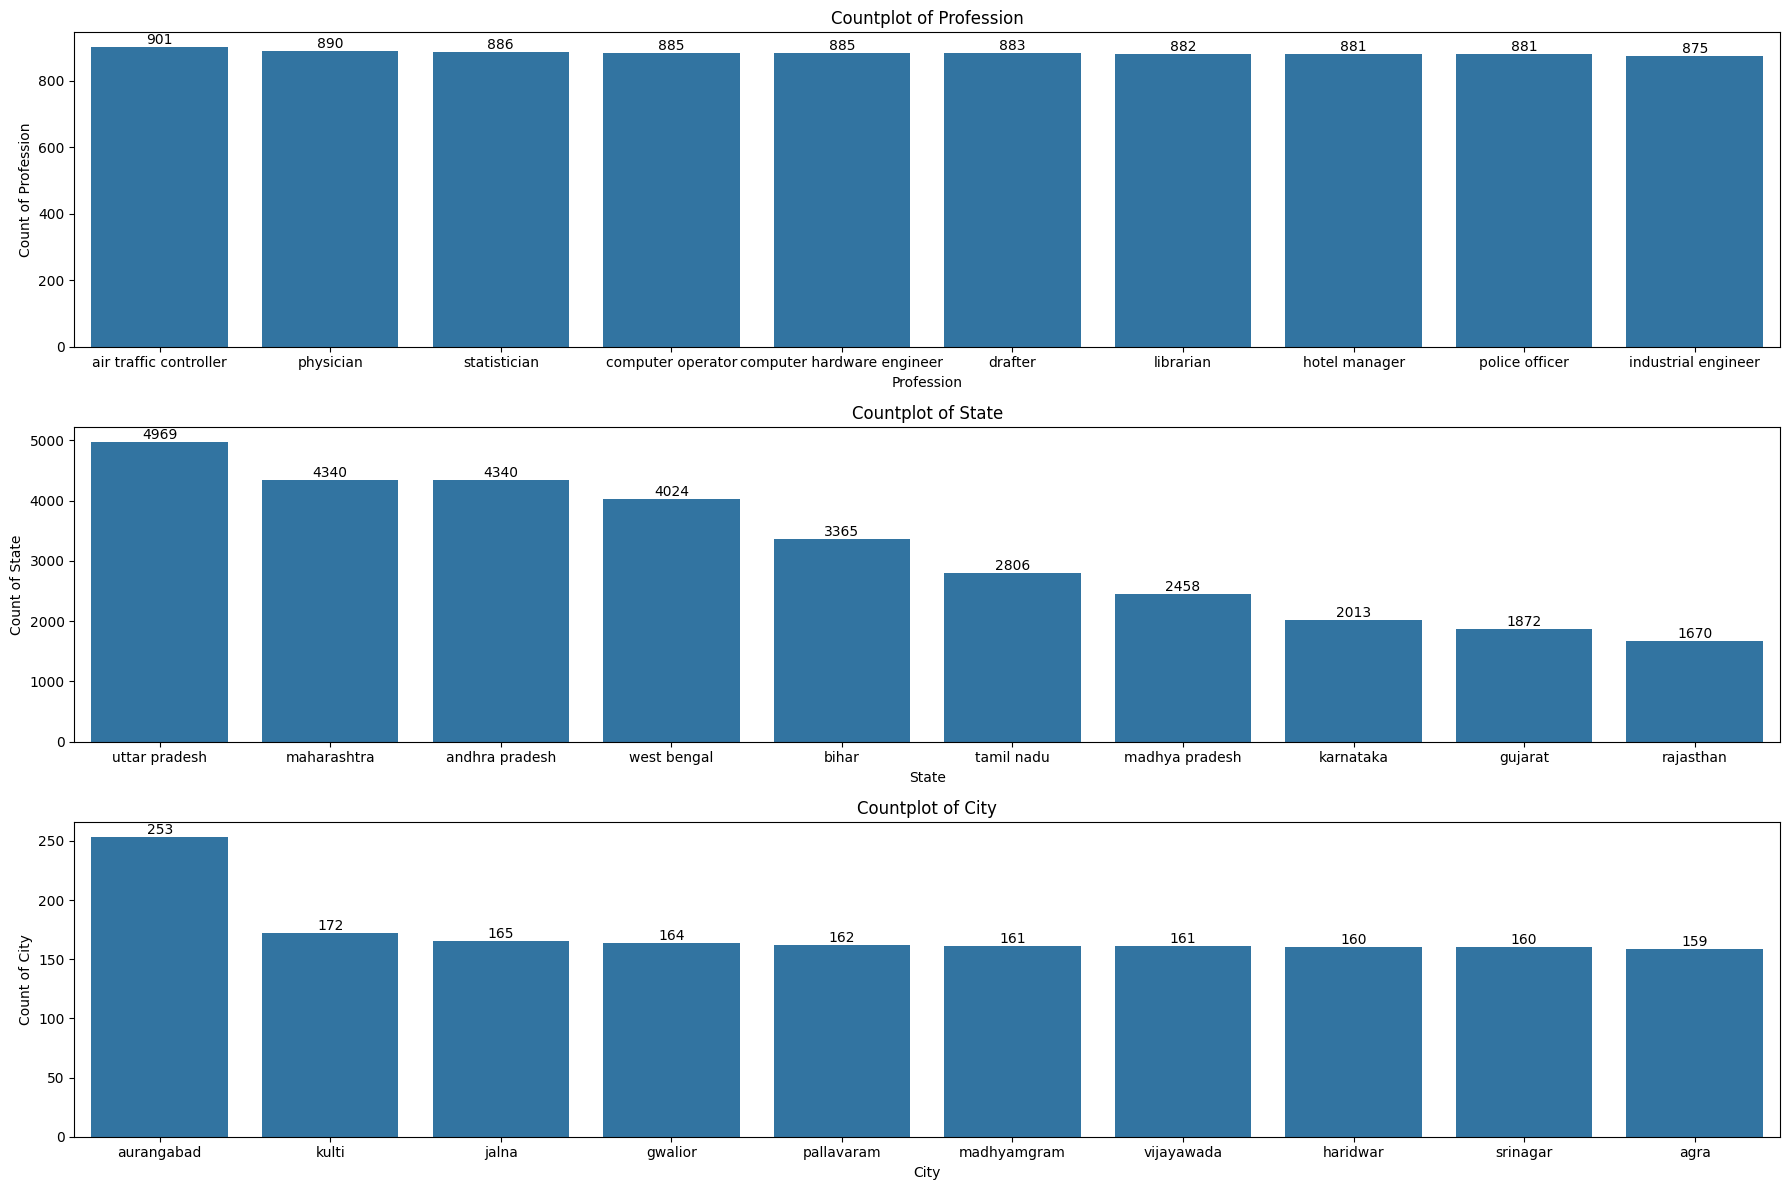

In [21]:
# Countplot function implementation (for few unique values columns)
cats_many = ['Profession', 'State', 'City']

# Show top 10 categories for each column
plot_dynamic_countplot(
    df=df,
    col_series=cats_many,
    ncols=1,
    figsize=(18, 12),
    order=[df[cat].value_counts().iloc[:10].index.tolist() for cat in cats_many]
)

## Univariate Analysis Findings

- For the analysis of numerical columns, several findings were observed:

    1. The distribution of the target variable (Risk_Flag) is bimodal, with a significant dominance of the value 0 (No default or non-failure to pay).

    2. Features like Income, Age, and Experience exhibit a uniform distribution, while Current_House_Years and Current_Job_Years have multi-modal distributions as indicated by histplot with kde. No outliers were detected for the overall numerical features based on boxplots.

    3. Some features, such as Income and Age, may require scaling due to their large value ranges compared to other numerical features.

- For the analysis of categorical columns, several observations were made:

    1. Categories in the Profession, City, and State features have too many unique values, making it challenging to plot the entire distribution.

    2. Some features have dominating values, including: (feature name : value name)
        - Car_Ownership : no
        - House_Ownership : rented
        - Married/Single : single

- Some follow-up steps during data pre-processing include:

    1. Handling categorical data from features like Profession, City, and State with a large number of unique values. This can be achieved by grouping or categorizing them to reduce the number of distinct values before encoding.

    2. Considering resampling due to class imbalance in the target variable, where Risk_Flag Default represents only 19.55% of the total data. This imbalance falls into the category of moderate (1-20%), and resampling may be necessary.

## Bivariate/Multivariate Analysis

<Figure size 1500x1500 with 0 Axes>

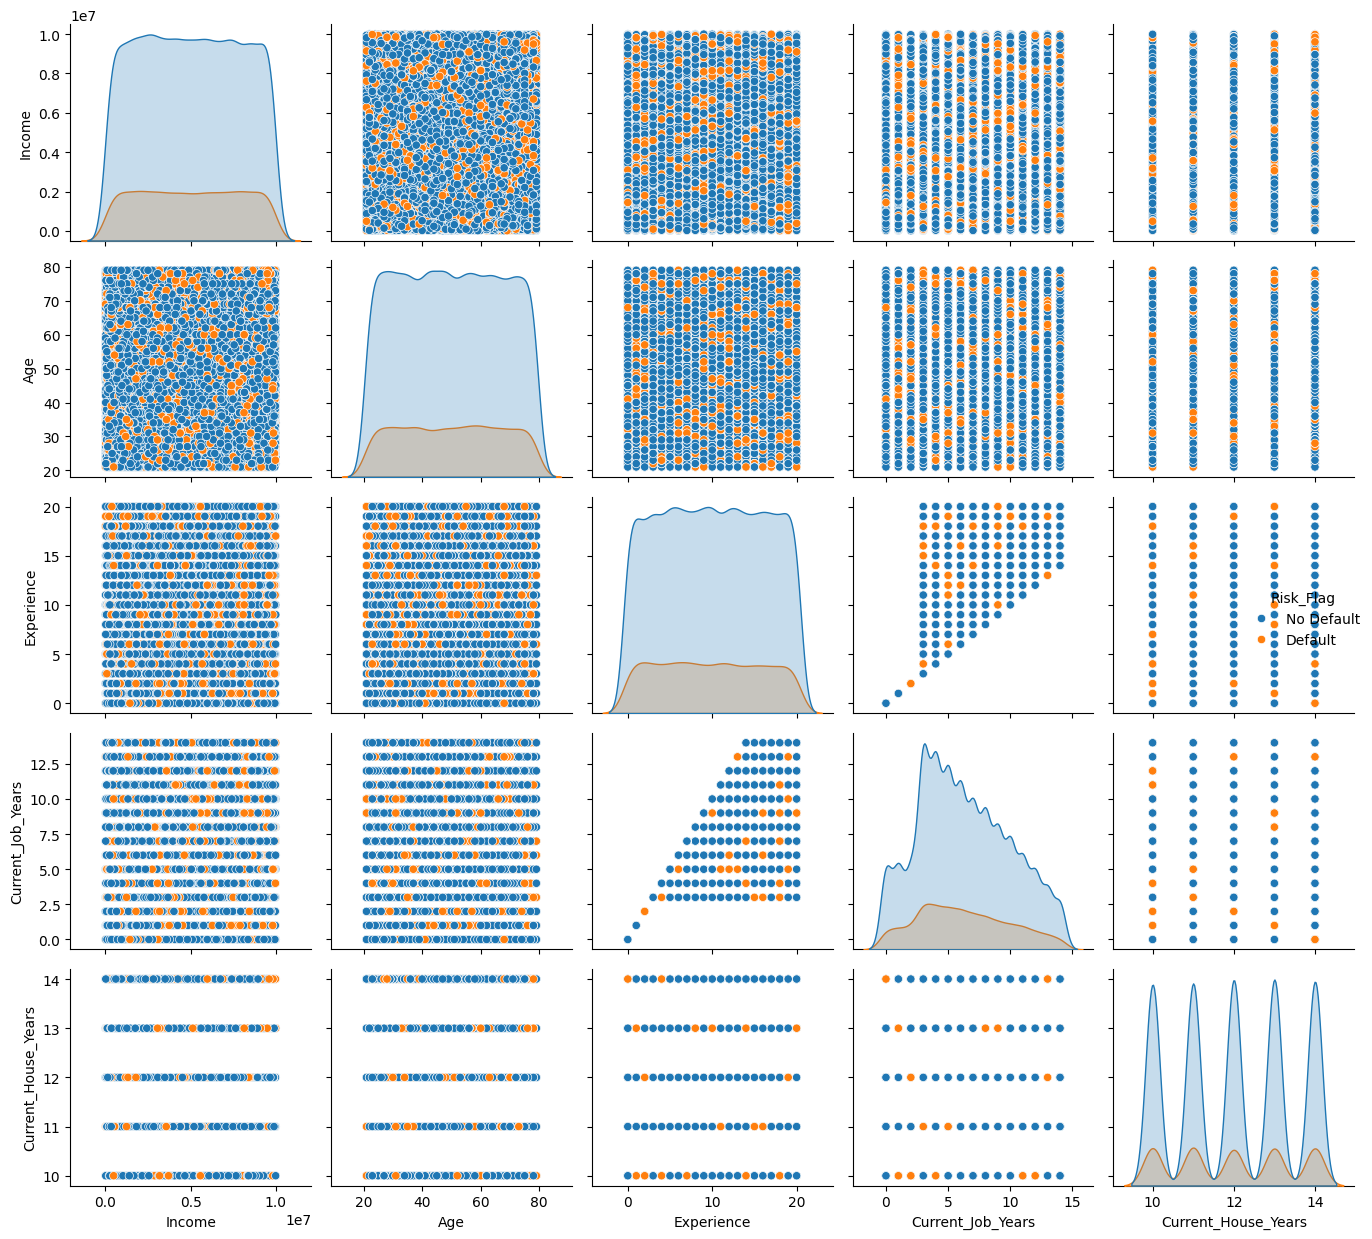

In [22]:
# Pairplot of numerical features
plt.figure(figsize=(15, 15))
sns.pairplot(data=df, diag_kind='kde', hue='Risk_Flag')
plt.tight_layout()
plt.show()

In [23]:
# Change the target datatype to numerical again for correlation analysis
change_target_dtype(data=df, target_type='numerical')

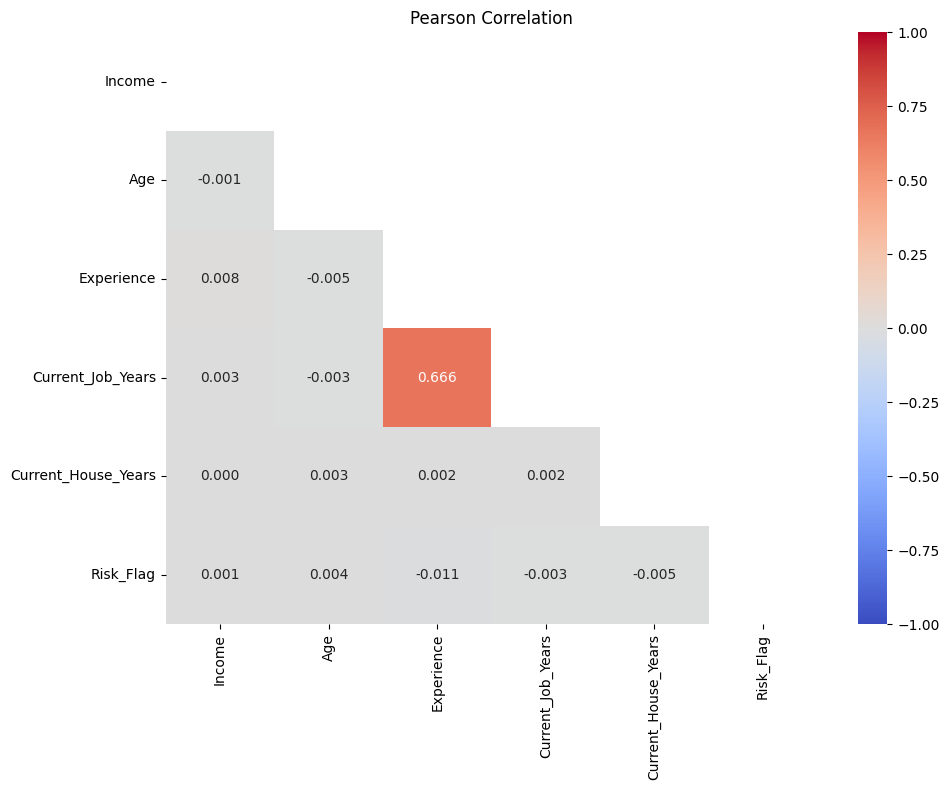

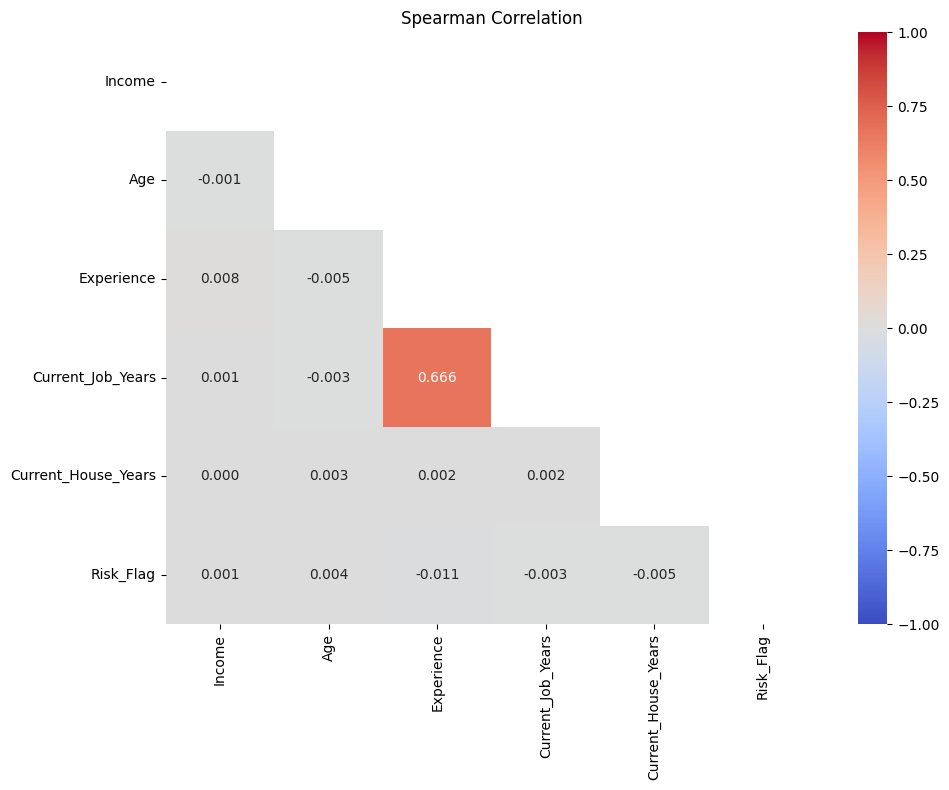

In [24]:
# Correlation heatmaps from the shared utils package
from utils import plot_correlation_heatmap

corr_columns = nums_cols + ['Risk_Flag']
plot_correlation_heatmap(df, corr_columns, corr_method='pearson', figsize=(10, 8))
plot_correlation_heatmap(df, corr_columns, corr_method='spearman', figsize=(10, 8))

Observing the relationship between non-linear feature-feature and feature-target pairs in the previous pairplot (scatterplot matrix), the use of the Pearson method may not be suitable. Therefore, when examining correlations using `df.corr()`, it is more appropriate to rely on the results of the Spearman method, which can capture non-linear relationships.

In [25]:
# Feature-feature and feature-target correlation in one utils call
from utils import calculate_correlation_tabular

corr_feature, corr_final = calculate_correlation_tabular(
    df, target_col='Risk_Flag', method='spearman', corr_type='both'
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,Current_Job_Years,Experience,0.666470,Positive
1,Experience,Income,0.008139,Positive
2,Age,Experience,0.004861,Negative
3,Age,Current_Job_Years,0.003360,Negative
4,Age,Current_House_Years,0.003207,Positive
5,Current_House_Years,Current_Job_Years,0.002001,Positive
6,Current_House_Years,Experience,0.001909,Positive
7,Current_Job_Years,Income,0.001320,Positive
8,Age,Income,0.000949,Negative
9,Current_House_Years,Income,0.000378,Positive



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,Experience,0.010709,Negative
1,Current_House_Years,0.004781,Negative
2,Age,0.003846,Positive
3,Current_Job_Years,0.003427,Negative
4,Income,0.000510,Positive


In [26]:
# Change the target datatype to categorical again for correlation analysis
change_target_dtype(data=df, target_type='categorical')


Chi-Square Analysis Results:
--------------------------------------------------------------------------------


,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
4,City,324.394735,0.345633,0.086665,Negligible,False,yamunanagar,Positive
3,Profession,41.374788,0.802354,0.030951,Negligible,False,psychologist,Positive
5,State,33.952804,0.167424,0.028038,Negligible,False,bihar,Negative
2,Car_Ownership,5.418814,0.019921,0.011201,Negligible,True,yes,Positive
1,House_Ownership,0.868142,0.647866,0.004483,Negligible,False,norent_noown,Positive
0,Marital_Status,0.062055,0.803277,0.001199,Negligible,False,married,Positive


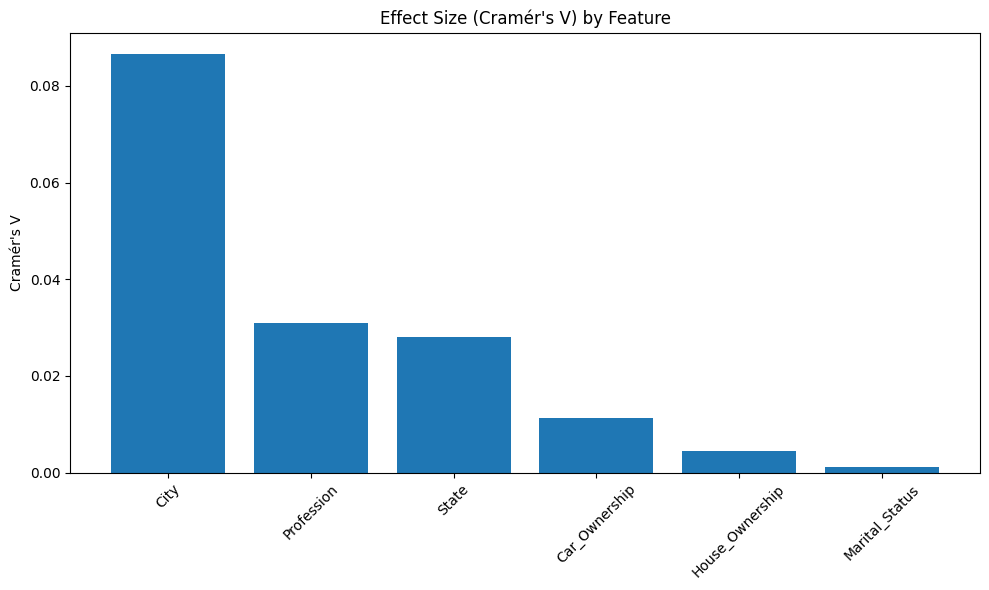

In [27]:
# Categorical association analysis now comes from the shared utils package
from utils import analyze_categorical_relationships

cats_check_correlation = cats_cols_exclude_target
results = analyze_categorical_relationships(df, cats_check_correlation, 'Risk_Flag')

### Why categorical features use Chi-Square and Cramér's V

`.corr()` assumes continuous, ordered values, so it is misleading for nominal categories. `analyze_categorical_relationships` tests independence with the Chi-Square test and reports Cramér's V (0 = no association, 1 = perfect association).


## Bivariate/Multivariate Analysis Findings

- For the time being, from this EDA process (before performing feature encoding), the relationships among all numerical features and the target are considered to have low correlation (<0.02). The most relevant features are Experience (-0.01), Current_House_Years (-0.004), and Age (0.003).

- Experience and Current_Job_Years features have a relatively high positive correlation (0.666). This implies that the larger the experience, the longer the current job years, indicating that these two features are quite redundant. Therefore, one of them needs to be dropped; in this case, the feature to be dropped is Current_Job_Years as it has a lower correlation with the target compared to the Experience feature. Meanwhile, the relationships among other features have relatively low correlations, <= 0.01.

- In categorical correlation, the features are not that significant to the target variable.

## Business Insight (Multivariate Continuation)

### Default by Numerical Columns

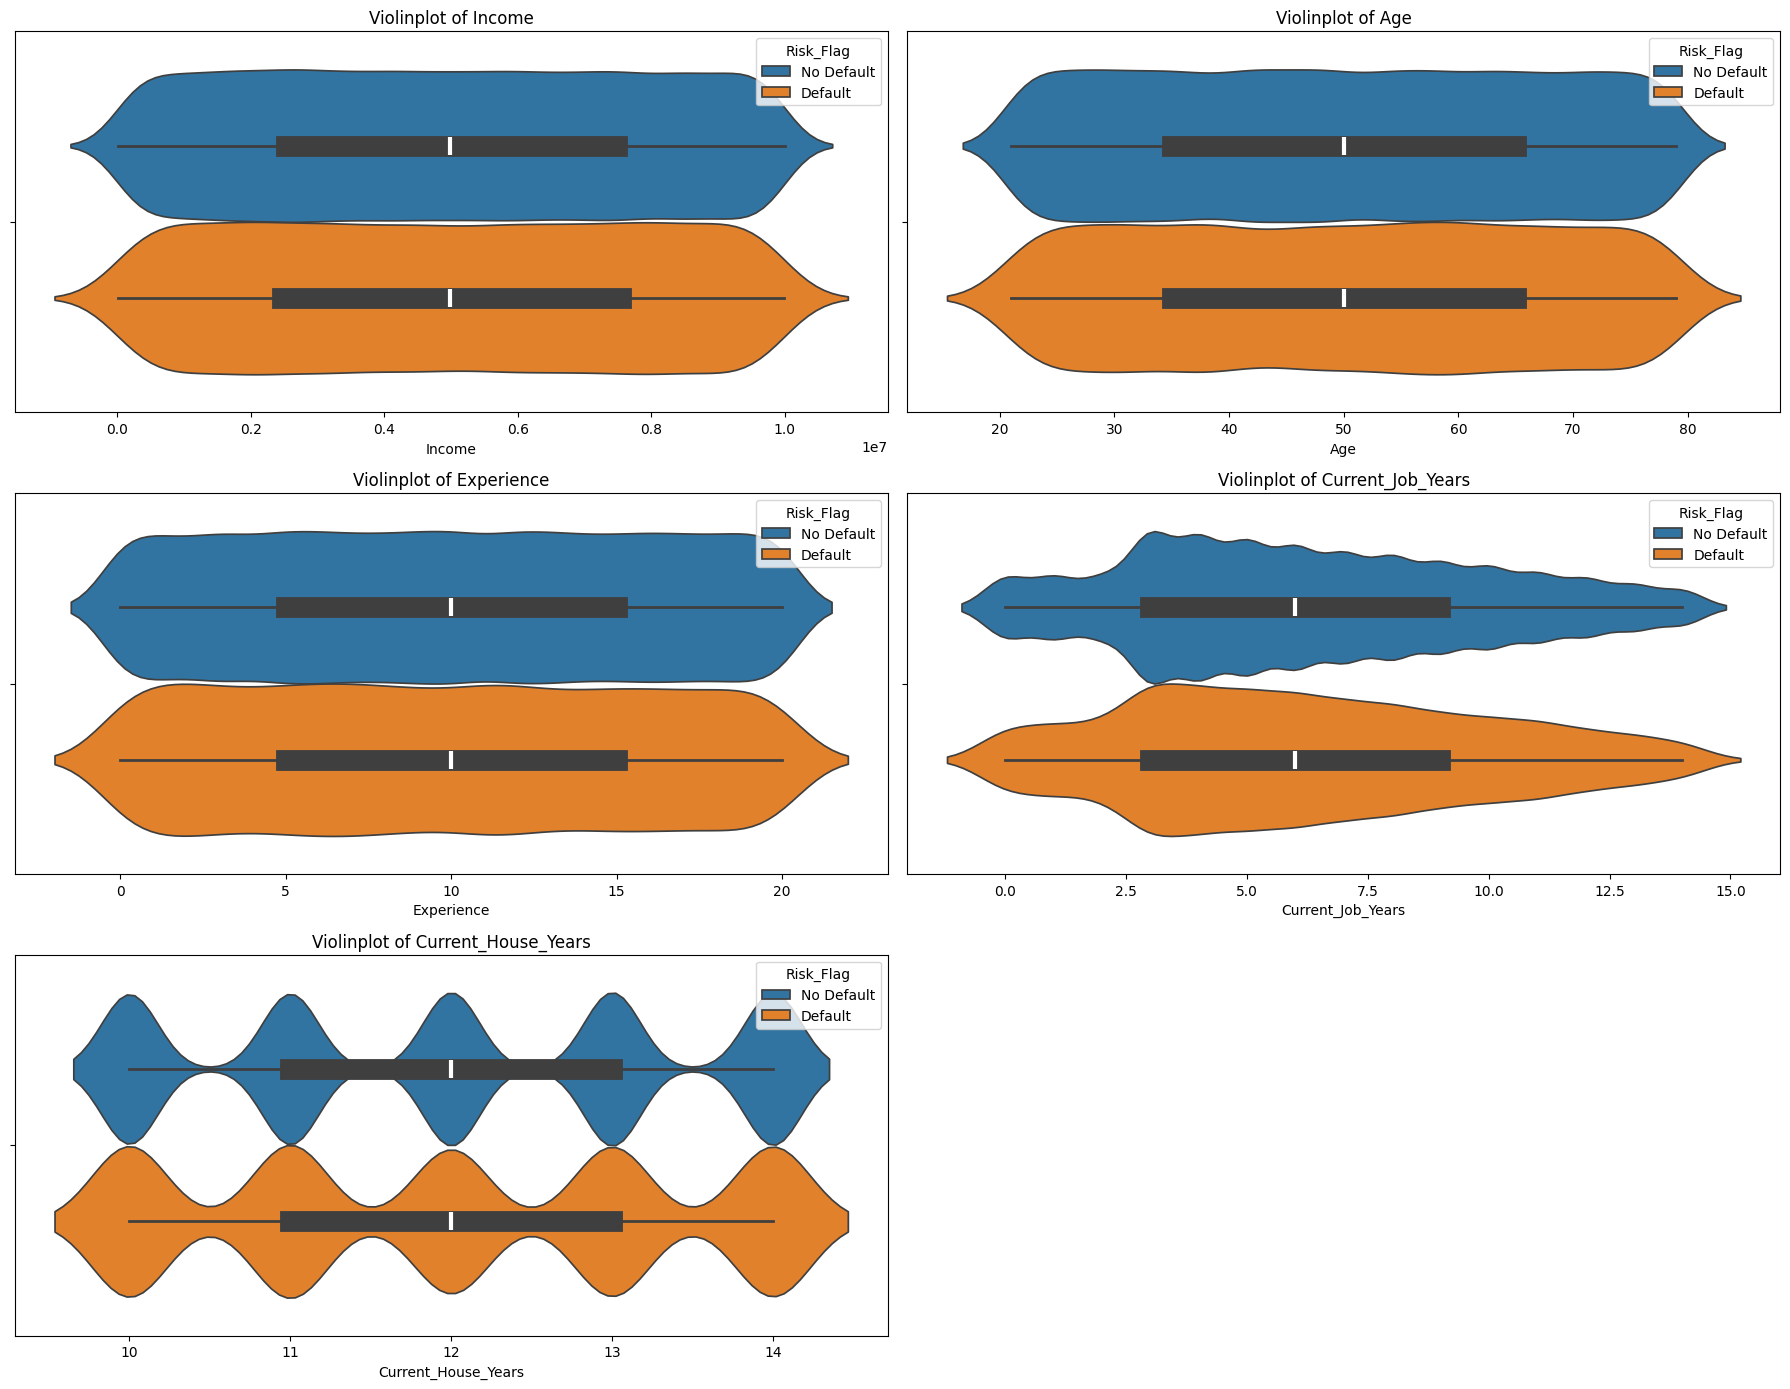

,Feature,overall_count,class_Default_count,class_No Default_count,overall_mean,class_Default_mean,class_No Default_mean,overall_std,class_Default_std,class_No Default_std,overall_min,class_Default_min,class_No Default_min,overall_25%,class_Default_25%,class_No Default_25%,overall_50%,class_Default_50%,class_No Default_50%,overall_75%,class_Default_75%,class_No Default_75%,overall_max,class_Default_max,class_No Default_max,overall_range,class_Default_range,class_No Default_range,overall_IQR,class_Default_IQR,class_No Default_IQR,overall_CV,class_Default_CV,class_No Default_CV,overall_skewness,class_Default_skewness,class_No Default_skewness,overall_kurtosis,class_Default_kurtosis,class_No Default_kurtosis
0,Income,43190.0,8443.0,34747.0,4.999184e+06,5.002267e+06,4.998435e+06,2.883155e+06,2.900077e+06,2.879070e+06,10310.0,10675.0,10310.0,2508307.25,2465364.0,2523337.5,4984654.5,4986280.0,4981403.0,7494142.25,7546985.0,7483510.5,9999938.0,9994501.0,9999938.0,9989628.0,9983826.0,9989628.0,4985835.0,5081621.0,4960173.0,57.672514,57.975243,57.599428,0.007885,0.000964,0.009592,-1.198446,-1.216665,-1.193956
1,Age,43190.0,8443.0,34747.0,4.991741e+01,5.004986e+01,4.988523e+01,1.705670e+01,1.704838e+01,1.705881e+01,21.0,21.0,21.0,35.00,35.0,35.0,50.0,50.0,50.0,65.00,65.0,65.0,79.0,79.0,79.0,58.0,58.0,58.0,30.0,30.0,30.0,34.169845,34.062789,34.196122,0.005897,-0.004707,0.008476,-1.199431,-1.201438,-1.198890
2,Experience,43190.0,8443.0,34747.0,9.975041e+00,9.844013e+00,1.000688e+01,6.034418e+00,6.045116e+00,6.031473e+00,0.0,0.0,0.0,5.00,5.0,5.0,10.0,10.0,10.0,15.00,15.0,15.0,20.0,20.0,20.0,20.0,20.0,20.0,10.0,10.0,10.0,60.495176,61.409058,60.273277,0.005845,0.033030,-0.000731,-1.195311,-1.201161,-1.193510
3,Current_Job_Years,43190.0,8443.0,34747.0,6.298981e+00,6.273126e+00,6.305264e+00,3.663603e+00,3.672738e+00,3.661406e+00,0.0,0.0,0.0,3.00,3.0,3.0,6.0,6.0,6.0,9.00,9.0,9.0,14.0,14.0,14.0,14.0,14.0,14.0,6.0,6.0,6.0,58.161837,58.547176,58.069030,0.261364,0.258586,0.262081,-0.786562,-0.796151,-0.784251
4,Current_House_Years,43190.0,8443.0,34747.0,1.200627e+01,1.199254e+01,1.200961e+01,1.412652e+00,1.419419e+00,1.411003e+00,10.0,10.0,10.0,11.00,11.0,11.0,12.0,12.0,12.0,13.00,13.0,13.0,14.0,14.0,14.0,4.0,4.0,4.0,2.0,2.0,2.0,11.765944,11.835854,11.748943,-0.006615,0.010677,-0.010807,-1.297897,-1.313472,-1.293939


In [28]:
# Violinplot with hue target
plot_dynamic_boxplots_violinplots(df, col_series=nums_cols,
                                  plot_type='violinplot', ncols=2, figsize=(14, 18),
                                  orientation='h',
                                  hue='Risk_Flag')

# Get better understanding of the data through descriptive statistics with hue target
describe_numerical_combined(df, nums_cols, hue='Risk_Flag')

### Default by Marital_Status, House Ownership, and Car Ownership

#### Plotting by the amount

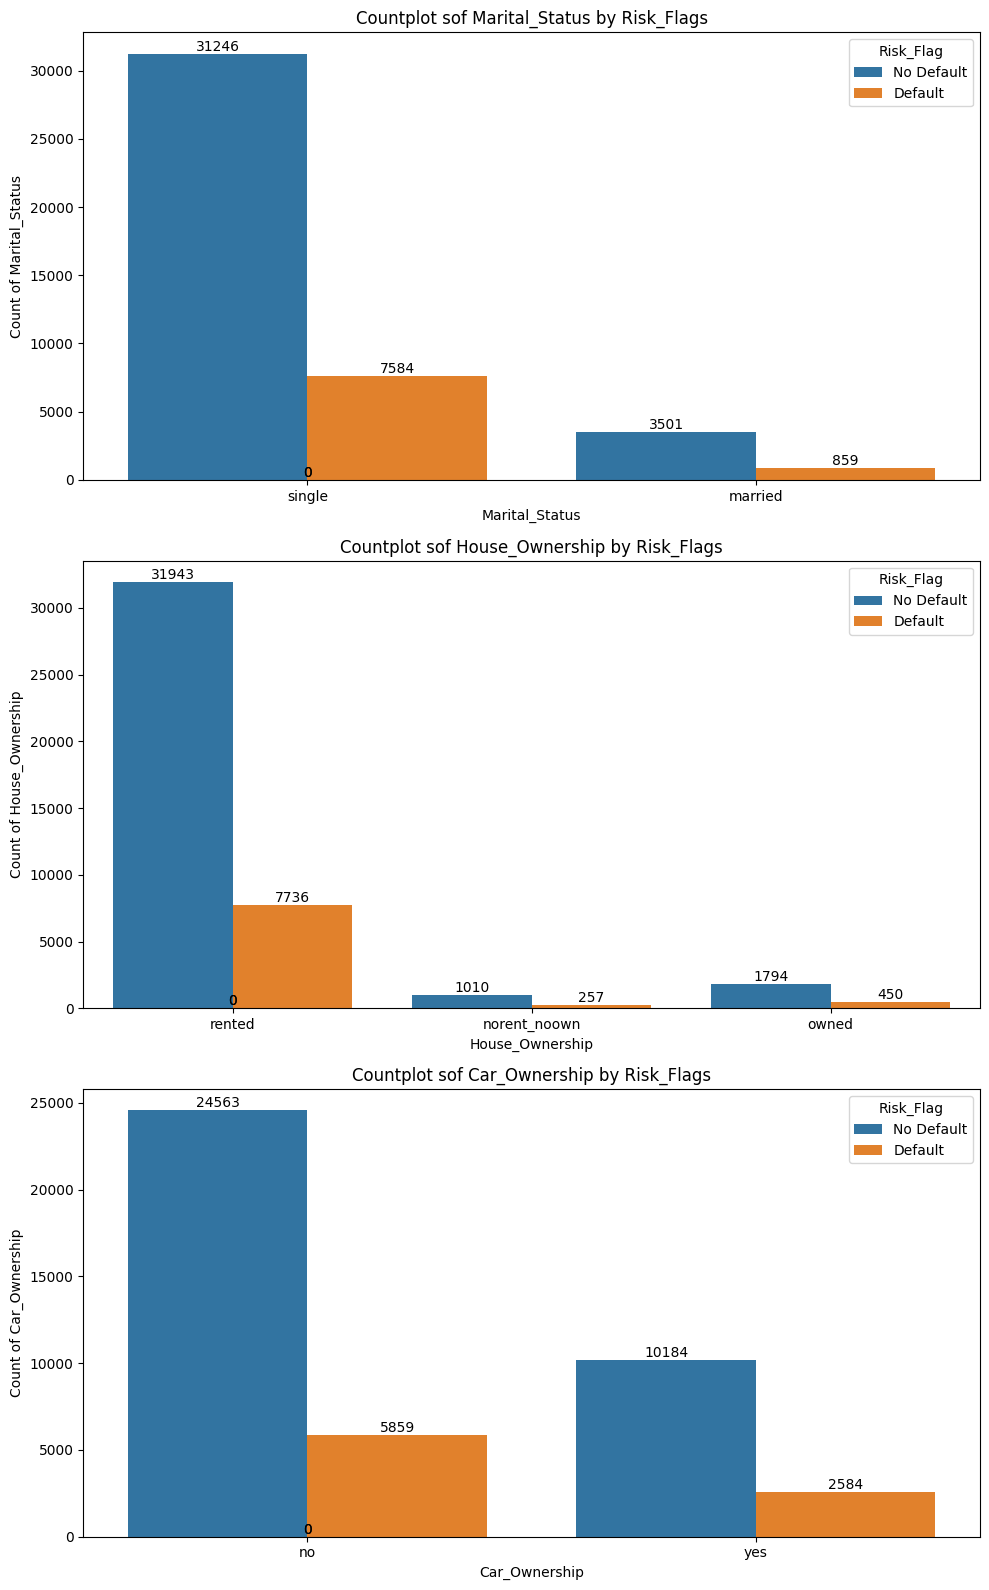

In [29]:
# Countplot Categorical (Few unique values)
plot_dynamic_countplot(
    df=df,
    col_series=cats_few,
    ncols=1,
    figsize=(10, 16),
    hue="Risk_Flag"
)

#### Plotting by Ratio

In [30]:
# Proportion of each category split by Risk_Flag
def plot_risk_distribution_pies(df, categorical_col, figsize=(12, 6),
                                colors=['lightblue', 'orange'],
                                label_size=12, title_size=14):
    """Plot the Risk_Flag split inside each category of a column."""
    proportions = df.groupby([categorical_col, 'Risk_Flag']).size().unstack(fill_value=0)
    proportions = proportions.apply(lambda x: x / x.sum(), axis=1)

    n_categories = len(proportions)
    if n_categories > 2:
        figsize = (15, 6)

    fig, ax = plt.subplots(1, n_categories, figsize=figsize)
    if n_categories == 1:
        ax = [ax]

    for i, (category, row) in enumerate(proportions.iterrows()):
        ax[i].pie(row, labels=['No Default', 'Default'], autopct='%1.2f%%',
                  colors=colors, startangle=90,
                  textprops={'fontsize': label_size})
        ax[i].set_title(category, fontsize=title_size)

    plt.tight_layout()
    plt.show()

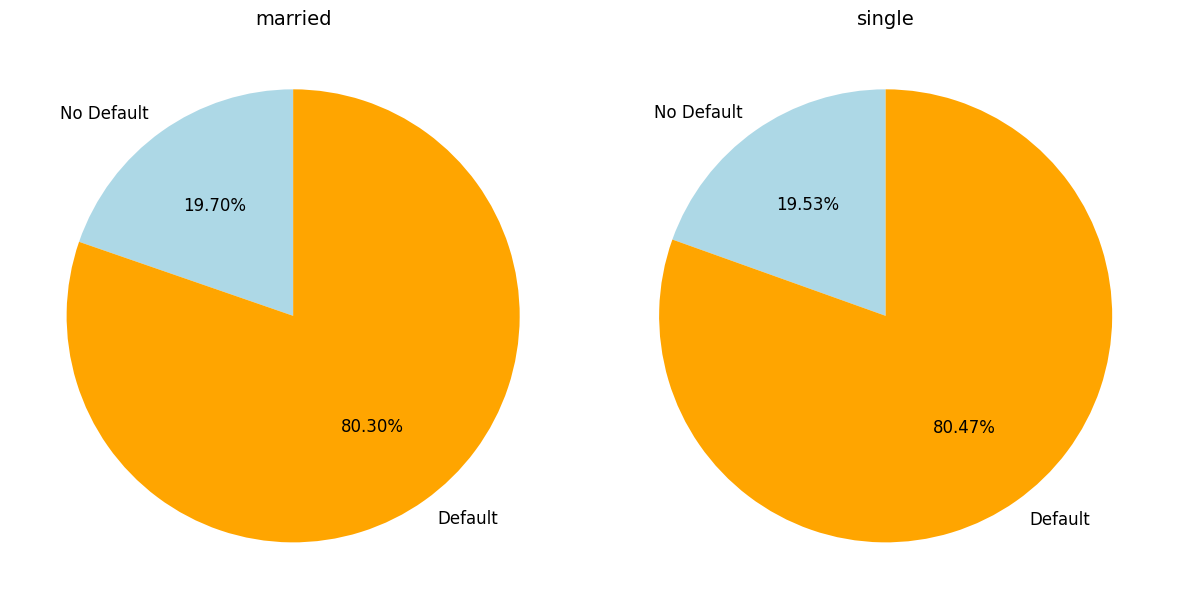

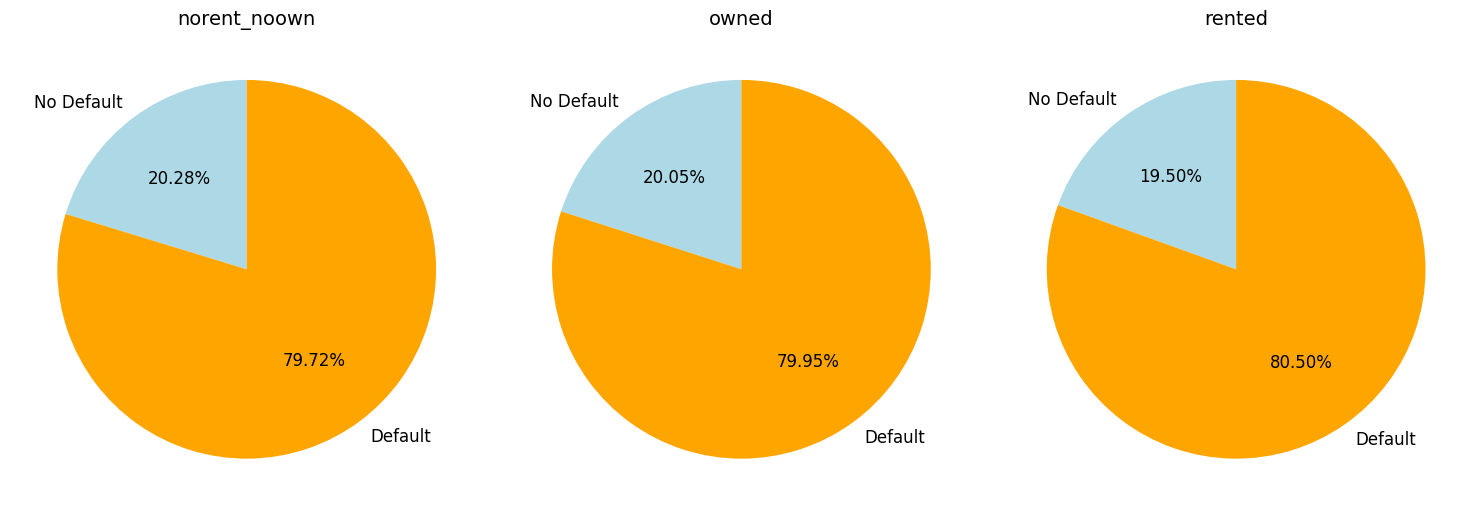

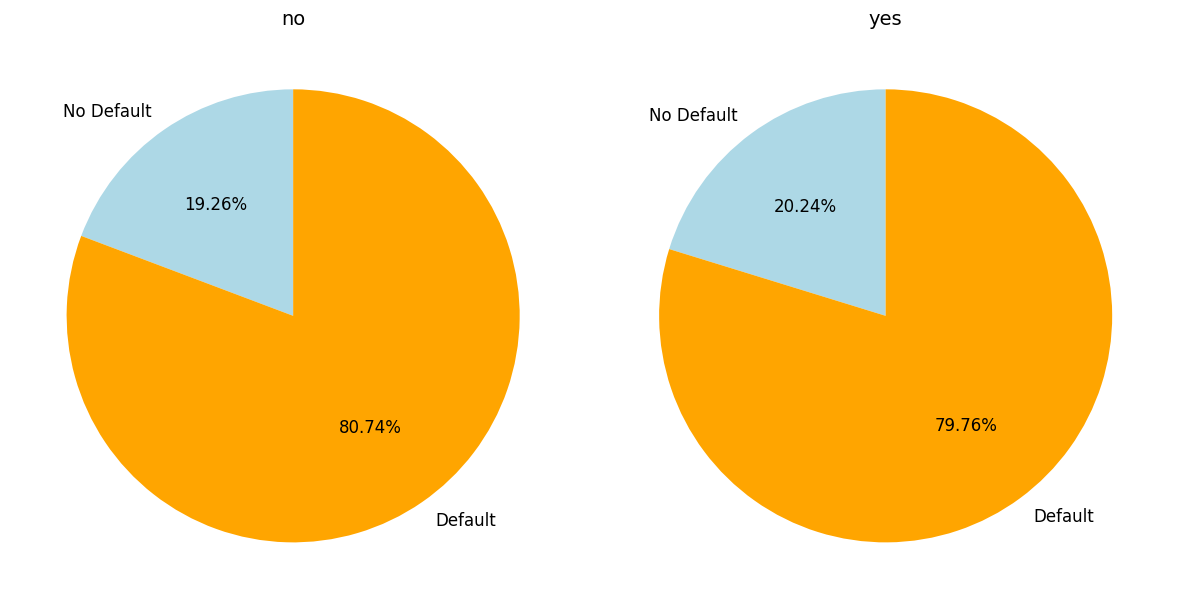

In [31]:
# Test with every category
plot_risk_distribution_pies(df, 'Marital_Status')
plot_risk_distribution_pies(df, 'House_Ownership')
plot_risk_distribution_pies(df, 'Car_Ownership')

#### **Business Insight:**

From the information on categorical features, customers applying for loans are predominantly from the single category, only have rented homes, and do not own a car. When compared for each category:

1. **Based on Marital Status (Married/Single):**
   - Customers who are single are slightly more inclined to have the potential for default compared to married customers. This insight suggests that marital status may play a role in assessing the risk of loan default.

2. **Based on Home Ownership Status (Rented/Own/No House):**
   - Customers who have rented homes (rented) tend to have a higher potential for default compared to customers with private homes or no home ownership. This may indicates that the status of home ownership is a significant factor in assessing the risk of loan default.

3. **Based on Car Ownership Status (Yes/No):**
   - Customers who do not own a car are slightly more inclined to have the potential for default compared to those who own a car. This suggests that car ownership status may influence a customer's ability to repay the loan.

It is important to emphasize that these findings may be biased due to the imbalance in the available data across categories. Further analysis and a deeper understanding of these factors are required to make more accurate decisions in credit risk assessment.

#### Brief Business Recommendation

1. **Marital Status:**
   - **Targeted Risk Mitigation for Single Applicants:**
     - Implement a more rigorous risk assessment process for loan applications from single individuals, taking into account additional financial indicators and conducting thorough background checks. This can help in identifying potential default risks early on and adjusting loan terms accordingly.

   - **Customized Loan Products:**
     - Develop loan products tailored to the needs and financial situations of single individuals. This could include personalized interest rates, repayment schedules, or other terms that better align with the financial capabilities of single applicants, potentially reducing the default risk.

2. **Home Ownership Status:**
   - **Adjusted Loan Terms for Renters:**
     - For customers with rented homes, consider offering loan products with terms that accommodate their financial situation, such as flexible repayment schedules or lower interest rates. This can help mitigate the higher default potential associated with rented home ownership.

   - **Financial Education Programs:**
     - Implement financial education programs specifically targeting customers who rent homes. These programs can empower renters with better financial management skills, reducing the likelihood of default and improving their overall financial stability.

3. **Car Ownership Status:**
   - **Risk-Adjusted Interest Rates:**
     - Introduce risk-adjusted interest rates based on car ownership status. Customers without a car may face higher interest rates due to the perceived higher default risk. Offering competitive rates to car owners may incentivize them to choose your loan products.

   - **Collaboration with Dealerships:**
     - Explore partnerships with car dealerships to provide exclusive loan offers or discounts to customers purchasing cars. This collaboration can attract customers with car ownership aspirations and potentially lower the default risk associated with non-car owners.

### Default by Profession

In [32]:
# Plot the top and bottom N categories of a categorical feature
def plot_categorical_top_bottom_value(df, category_col, target='Risk_Flag',
                                      pos_class='Default', neg_class='No Default',
                                      method='count', n_groups=5, figsize=(24, 12)):
    """Plot the categories with the highest and lowest default volume/rate."""
    grouped_data = df.groupby([category_col, target]).size().unstack(fill_value=0)

    if method == 'count':
        top_groups = grouped_data[pos_class].sort_values(ascending=False).head(n_groups).index
        bottom_groups = grouped_data[pos_class].sort_values().head(n_groups).index
        top_data = grouped_data.reindex(top_groups)
        bottom_data = grouped_data.reindex(bottom_groups)
        title_prefix = f'Number of {pos_class}'
    elif method == 'rate':
        grouped_data['Positive_Rate'] = grouped_data[pos_class] / (grouped_data[pos_class] + grouped_data[neg_class])
        top_groups = grouped_data['Positive_Rate'].sort_values(ascending=False).head(n_groups).index
        bottom_groups = grouped_data['Positive_Rate'].sort_values().head(n_groups).index
        top_data = grouped_data.drop('Positive_Rate', axis=1).reindex(top_groups)
        bottom_data = grouped_data.drop('Positive_Rate', axis=1).reindex(bottom_groups)
        title_prefix = f'{pos_class} Rate'
    else:
        raise ValueError("Method must be either 'count' or 'rate'")

    fig, ax = plt.subplots(2, 1, figsize=figsize)
    top_data.plot(kind='bar', stacked=True, ax=ax[0])
    ax[0].set_title(f'Top {n_groups} {category_col}s by {title_prefix}')
    ax[0].set_ylabel('Count')
    ax[0].legend(title=target)

    bottom_data.plot(kind='bar', stacked=True, ax=ax[1])
    ax[1].set_title(f'Bottom {n_groups} {category_col}s by {title_prefix}')
    ax[1].set_ylabel('Count')
    ax[1].legend(title=target)

    for subplot in ax:
        for container in subplot.containers:
            subplot.bar_label(container, label_type='center')

    plt.setp(ax[0].get_xticklabels(), rotation=45, ha='right')
    plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

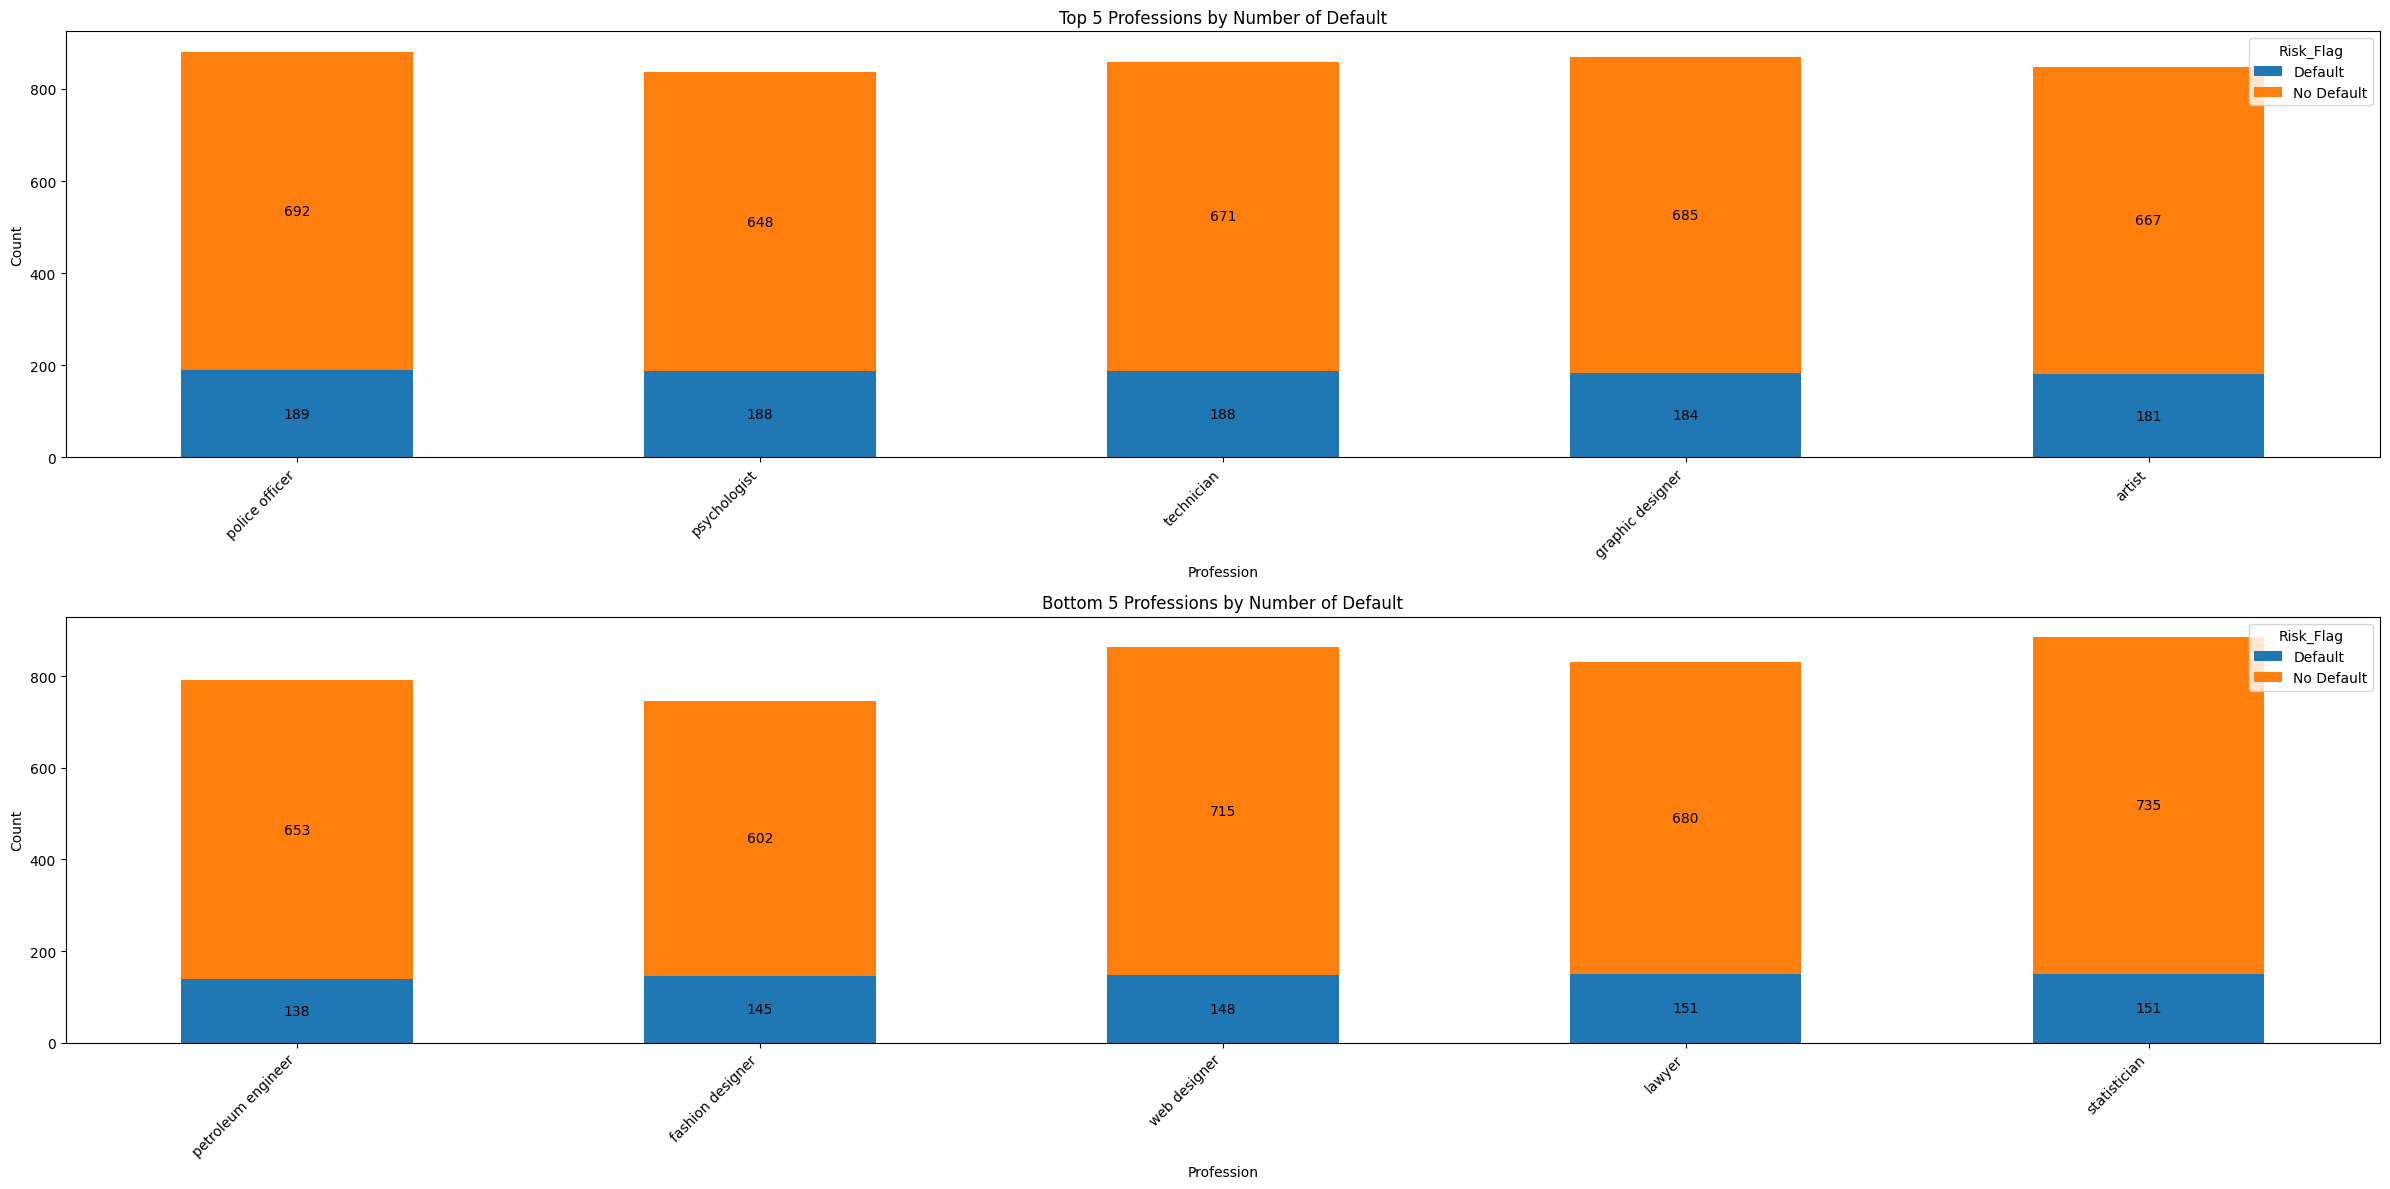

In [33]:
# Function implementation for profession
plot_categorical_top_bottom_value(df, 'Profession', target='Risk_Flag',
                                  pos_class='Default', neg_class='No Default')

#### Business Insight :

> Police Officer, Technician, Psychologist, Graphic Designer, and Artist are professions with the highest default rates, while Statistician, Lawyer, Web Designer, Fashiopn Designer, and Petroleum Engineer are professions with the lowest default rates.

#### Business Recommendation :

> - Develop specialized risk assessment services tailored for individuals in high-default professions. Utilize advanced data analytics, including behavioral and financial indicators, to provide a more accurate prediction of creditworthiness for applicants in these professions.

> - Collaborate with industry associations and employers to gather additional insights into the financial stability and responsibility of individuals in high-risk professions. This collaboration can enhance the accuracy of risk assessments and lead to more informed lending decisions.

> - Launch targeted financial education programs specifically designed for individuals in professions with high default rates. These programs can help borrowers manage their finances more effectively, reducing the likelihood of defaults.

### Default by State

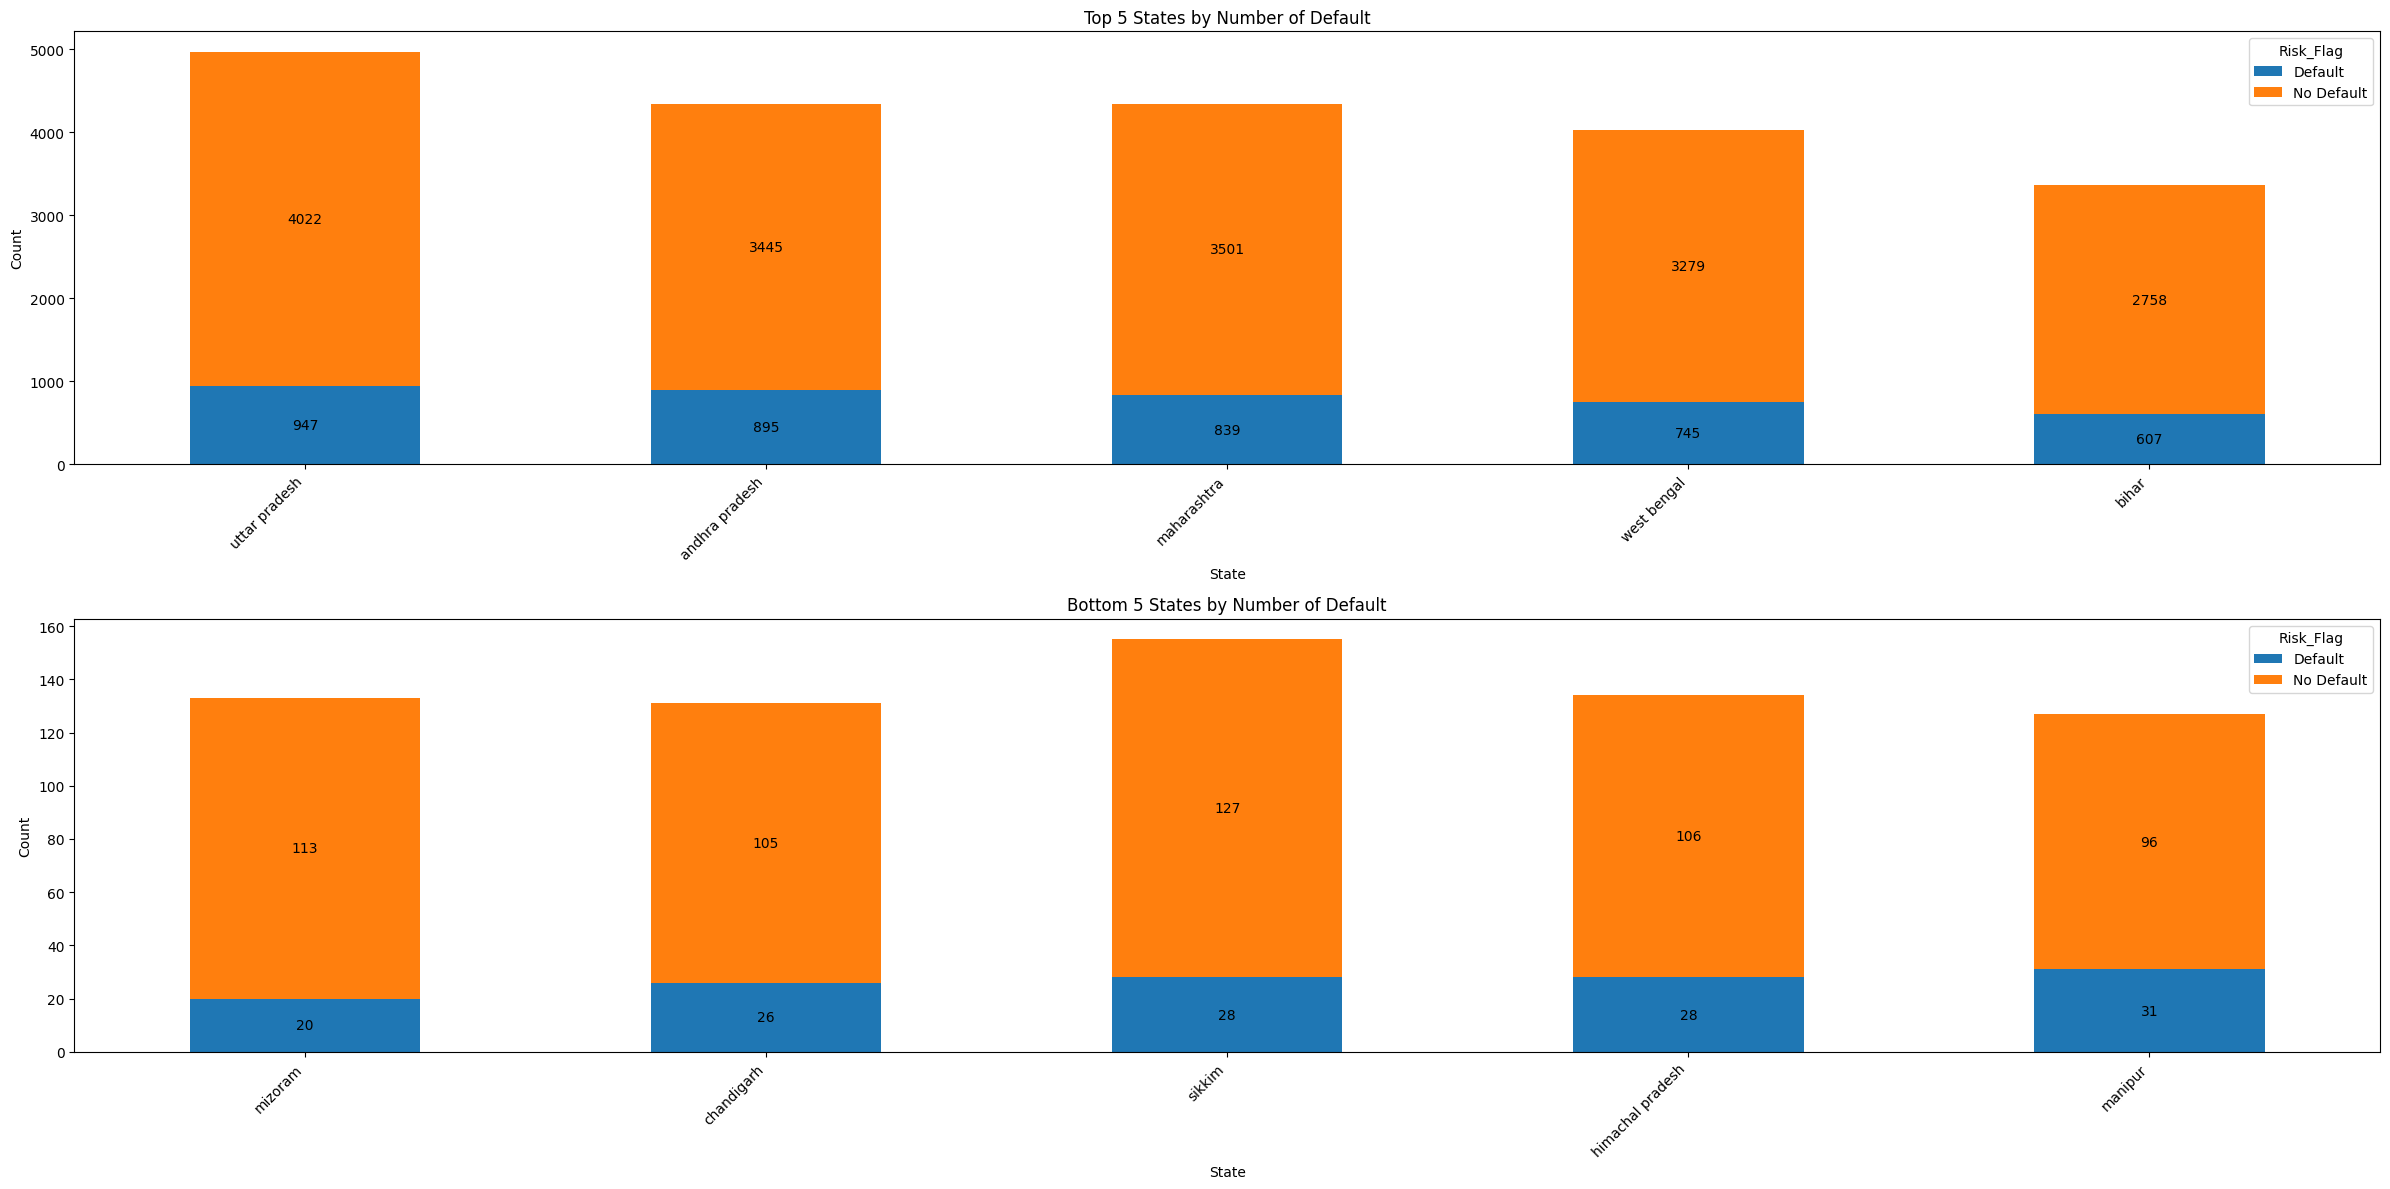

In [34]:
# Function implementation for state
plot_categorical_top_bottom_value(df, 'State', target='Risk_Flag', pos_class='Default', neg_class='No Default')

#### Business Insight :

> Uttar Pradesh, Andhra Pradesh, Maharashtra, West Bengal, and Bihar are the top 5 states with the highest number of customers with defaults, while Manipur, Sikkim, Himachal Pradesh, Chandigarh, and Mizoram are states with the lowest number of customer defaults. This case is a little bit different from profession case, here we can see that the difference in the amount between the top and bottom are quite high.

#### Business Recommendation :

> - Tailor marketing strategies based on the default rates in different states. Allocate marketing budgets and efforts more heavily towards states with lower default rates (e.g., Mizoram, Chandigarh), while implementing targeted campaigns or risk mitigation measures in states with higher default rates (e.g., Uttar Pradesh, Andhra Pradesh).

> -  Develop or refine credit risk models specific to each state. Incorporate state-specific economic indicators, socio-economic factors, and regional trends to create more accurate risk assessments for customers in each location.

> - Introduce loan products or terms that are customized to the economic conditions and financial behaviors prevalent in each state. This can help align the business's offerings with the specific needs and capacities of customers in different regions.

### Default by City

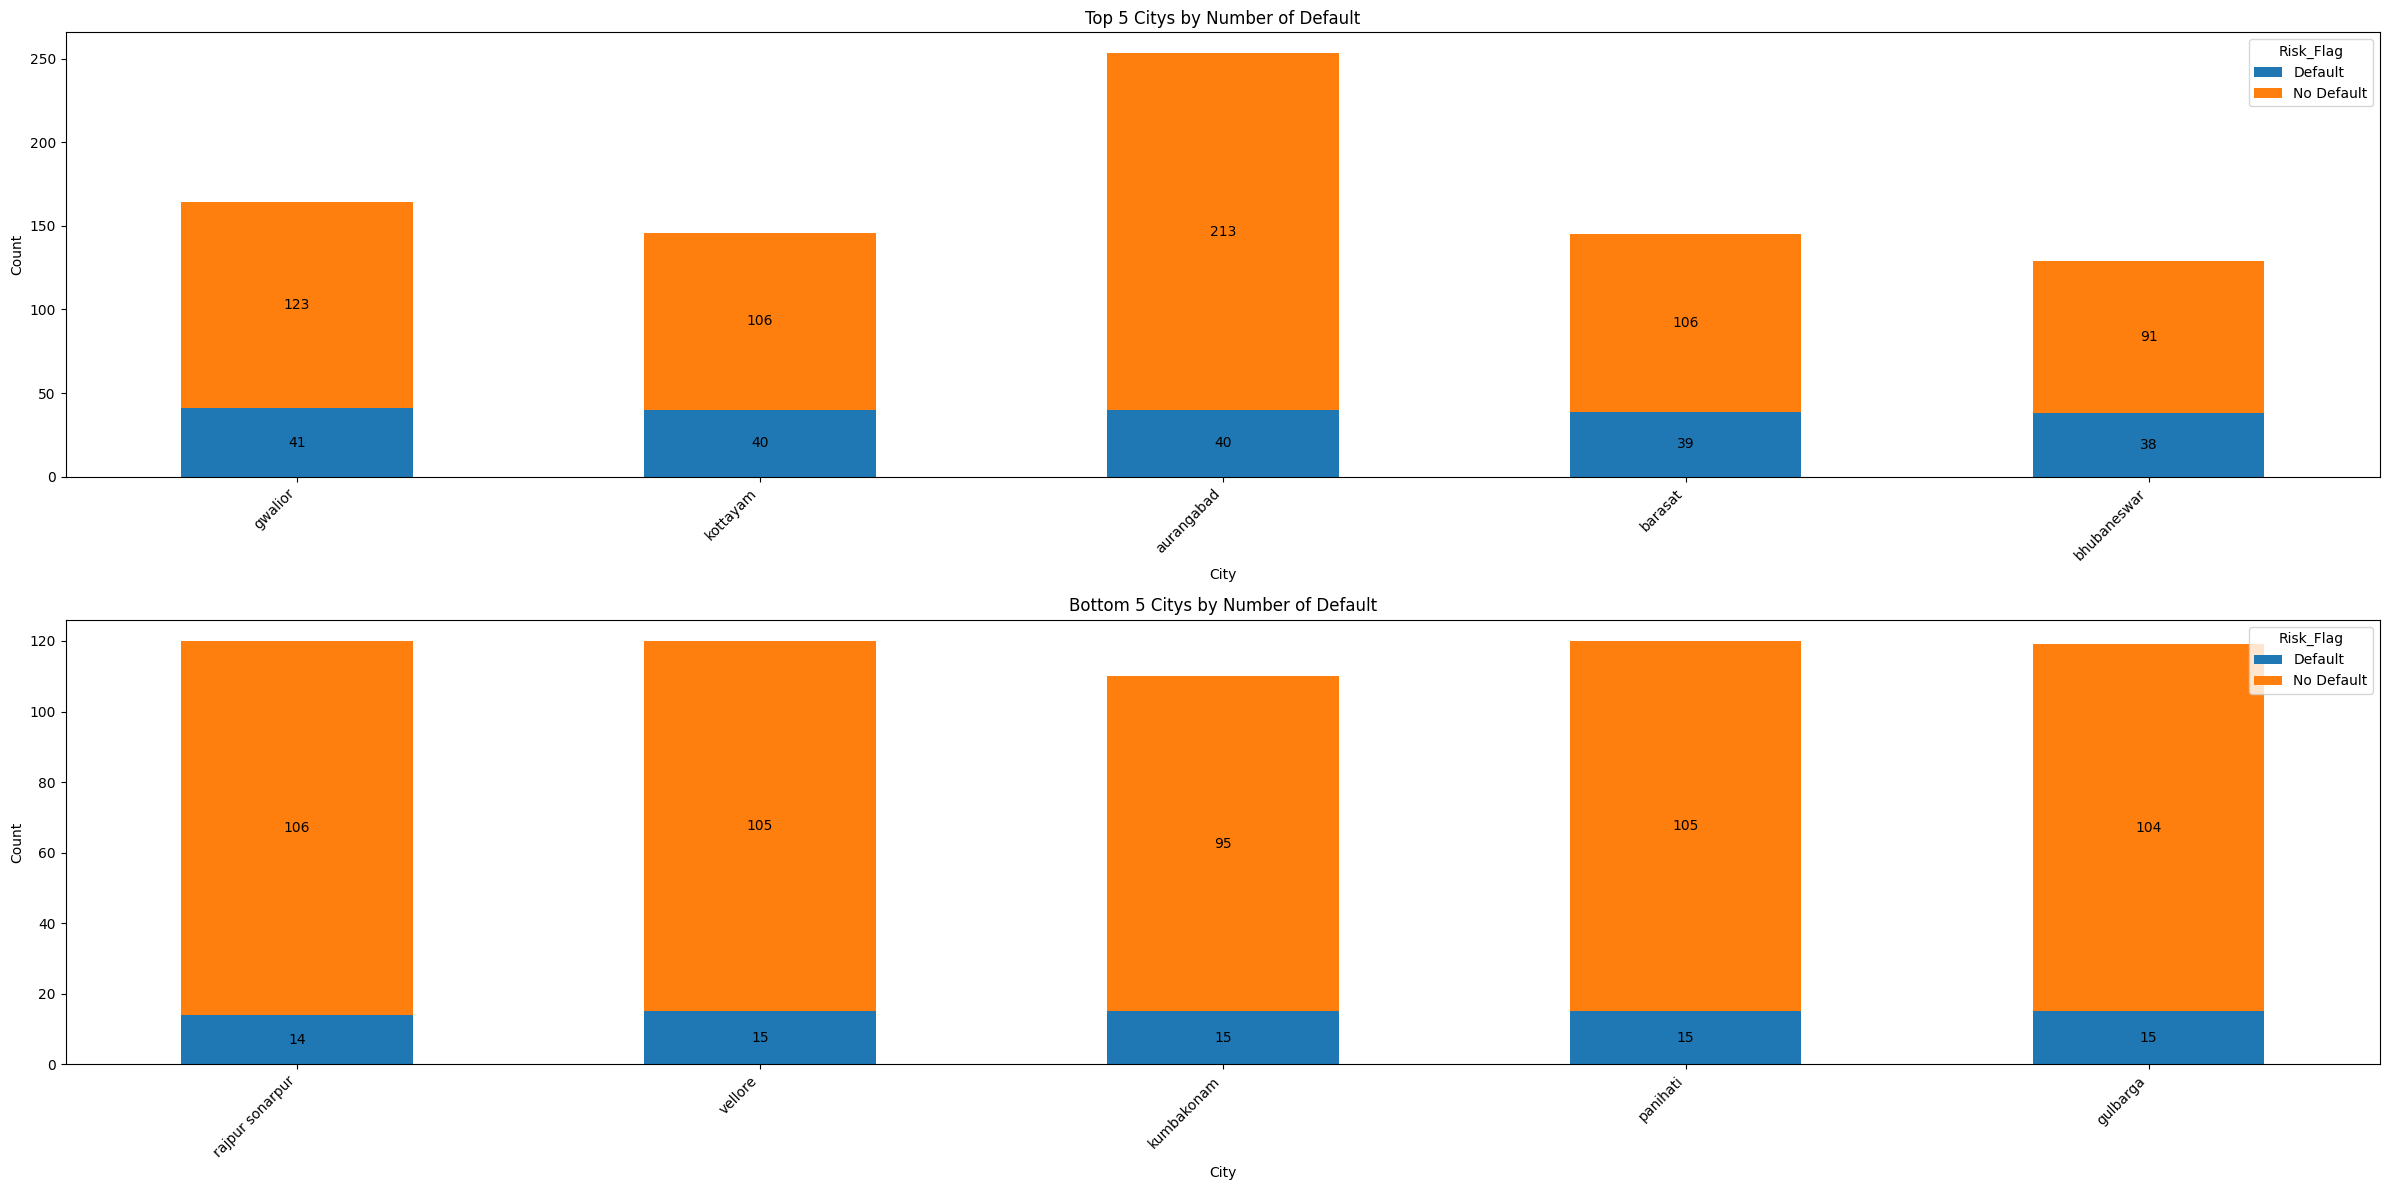

In [35]:
# Function implementation for state
plot_categorical_top_bottom_value(df, 'City', target='Risk_Flag', pos_class='Default', neg_class='No Default')

#### Business Insight :

> Gwalior, Aurangabad, Kottayam, Barasat, and Bhubaneswar are the top 5 cities with the highest number of customers with defaults, while Gulbarga, Panihati, Vellore, Kumbakonam, and Rajpur Sonapur are cities with the lowest number of customer defaults.

#### Business Recommendation :

> - Establish credit counseling centers in cities with high default rates to provide personalized financial advice and assistance to individuals facing repayment challenges.

> - Collaborate with local businesses and community organizations to promote these counseling services, creating a network that supports financial well-being at the grassroots level.

> - Implement advanced fraud prevention technologies, such as machine learning algorithms and biometric authentication, in cities with high default rates to enhance the security of financial transactions.

# **STAGE 2 : DATA PRE-PROCESSING**

The following important findings were discovered in the previous section:

1. The dataset does not contain missing values, duplicated values, or outliers.

2. For cleaning purposes, further checks may be needed, especially on categorical features with a considerable number of unique values, such as Profession, City, and State. If missing or duplicated values emerge after cleaning, they will be addressed through either dropping or filling with the modes.

3. Scaling is necessary for numerical features with large scales, such as Income and/or age (also with other engineered features later).

## Initial Cleaning and Encoding

In [36]:
# Make a copy of original dataframe for preprocessing and encoding process
df_encoding = df.copy()
df_encoding.head()

,Income,Age,Experience,Marital_Status,House_Ownership,Car_Ownership,Profession,City,State,Current_Job_Years,Current_House_Years,Risk_Flag
0,1303834,23,3,single,rented,no,mechanical engineer,rewa,madhya pradesh,3,13,No Default
1,7574516,40,10,single,rented,no,software developer,parbhani,maharashtra,9,13,No Default
2,3991815,66,4,married,rented,no,technical writer,alappuzha,kerala,4,10,No Default
3,6256451,41,2,single,rented,yes,software developer,bhubaneswar,odisha,2,12,Default
4,5768871,47,11,single,rented,no,civil servant,tiruchirappalli,tamil nadu,3,14,Default


### Cleaning and Encoding for Profession

In [37]:
# Checking every unique values in Profession
df_encoding['Profession'].unique()

array(['mechanical engineer', 'software developer', 'technical writer',
       'civil servant', 'librarian', 'economist', 'flight attendant',
       'architect', 'designer', 'physician', 'financial analyst',
       'air traffic controller', 'politician', 'police officer', 'artist',
       'surveyor', 'design engineer', 'chemical engineer',
       'hotel manager', 'dentist', 'comedian', 'biomedical engineer',
       'graphic designer', 'computer hardware engineer',
       'petroleum engineer', 'secretary', 'computer operator',
       'chartered accountant', 'technician', 'microbiologist',
       'fashion designer', 'aviator', 'psychologist', 'magistrate',
       'lawyer', 'firefighter', 'engineer', 'official', 'analyst',
       'geologist', 'drafter', 'statistician', 'web designer',
       'consultant', 'chef', 'army officer', 'surgeon', 'scientist',
       'civil engineer', 'industrial engineer', 'technology specialist'],
      dtype=object)

- Each value in `Profession` is a clean occupation name. The 51 occupations are grouped into ten families (engineering, technology, finance, healthcare, and so on) during feature engineering, then one-hot encoded.


### Cleaning and Encoding for State

In [38]:
# Checking every unique values in State
df_encoding['State'].unique()

array(['madhya pradesh', 'maharashtra', 'kerala', 'odisha', 'tamil nadu',
       'gujarat', 'rajasthan', 'telangana', 'bihar', 'andhra pradesh',
       'west bengal', 'haryana', 'puducherry', 'karnataka',
       'uttar pradesh', 'himachal pradesh', 'punjab', 'tripura',
       'uttarakhand', 'jharkhand', 'mizoram', 'assam',
       'jammu and kashmir', 'delhi', 'chhattisgarh', 'chandigarh',
       'manipur', 'sikkim'], dtype=object)

- `State` contains 28 clean state names. They are grouped into the four regional zones used by the model (north, south, east, west), then one-hot encoded.


### Cleaning and Encoding for City

In [39]:
# Checking every unique values in City
df_encoding['City'].unique()

array(['rewa', 'parbhani', 'alappuzha', 'bhubaneswar', 'tiruchirappalli',
       'jalgaon', 'tiruppur', 'jamnagar', 'kota', 'karimnagar', 'hajipur',
       'adoni', 'erode', 'kollam', 'madurai', 'anantapuram', 'kamarhati',
       'bhusawal', 'sirsa', 'amaravati', 'secunderabad', 'ahmedabad',
       'ajmer', 'ongole', 'miryalaguda', 'ambattur', 'indore',
       'pondicherry', 'shimoga', 'chennai', 'gulbarga', 'khammam',
       'saharanpur', 'gopalpur', 'amravati', 'udupi', 'howrah',
       'aurangabad', 'hospet', 'shimla', 'khandwa', 'bidhannagar',
       'bellary', 'danapur', 'purnia', 'bijapur', 'patiala', 'malda',
       'sagar', 'durgapur', 'junagadh', 'singrauli', 'agartala',
       'thanjavur', 'hindupur', 'naihati', 'north dumdum', 'panchkula',
       'anantapur', 'serampore', 'bathinda', 'nadiad', 'kanpur',
       'haridwar', 'berhampur', 'jamshedpur', 'hyderabad', 'bidar',
       'kottayam', 'solapur', 'suryapet', 'aizawl', 'asansol', 'deoghar',
       'eluru', 'ulhasnagar', 'a

- There is a case where City new delhi seems to be the same as City delhi city, we will check that.

In [40]:
df_encoding.loc[df_encoding['City'].str.contains('delhi')]['City'].unique()

array(['delhi city', 'new delhi'], dtype=object)

In [41]:
# Checking for similar cases where city name contains 'city' word
city_check = df_encoding.loc[df_encoding['City'].str.lower().str.contains('city')]['City'].unique()
display(city_check)

# Printing the amount of data for this case
print(len(df.loc[df_encoding['City'] == 'chandigarh city']))
print(len(df.loc[df_encoding['City'] == 'delhi city']))

array(['delhi city', 'chandigarh city'], dtype=object)

131
109


In [42]:
df_encoding[df_encoding['City'] == 'chandigarh city'].shape[0] + df_encoding[df_encoding['City'] == 'delhi city'].shape[0]

240

The case of cities that have the word 'city' is only owned by chandigarh city and delhi city (seen from the sum of rows). The cities involved are only in delhi city which is similar to new delhi because they both have the same state.

> **Training note:** this replacement happens after `df_encoding = df.copy()`, so the model's training frame still contains `delhi city` and maps it to the rural group. The Streamlit pipeline mirrors that behaviour. Changing it would require retraining the saved model.


In [43]:
# Replace Delhi_city city to New_Delhi
df['City'] = df['City'].replace('delhi city', 'new delhi')

## Feature Engineering

The final model uses profession, state, and city groups, a generation bucket, and the experience-to-age ratio. These are built below with the same mappings the Streamlit app imports from `loan_prediction.schema`.


### Profession_Group

In [44]:
# Profession feature before encoding
print(f"Number of unique profession: {df_encoding['Profession'].nunique()}")
print(df_encoding['Profession'].unique())

Number of unique profession: 51
['mechanical engineer' 'software developer' 'technical writer'
 'civil servant' 'librarian' 'economist' 'flight attendant' 'architect'
 'designer' 'physician' 'financial analyst' 'air traffic controller'
 'politician' 'police officer' 'artist' 'surveyor' 'design engineer'
 'chemical engineer' 'hotel manager' 'dentist' 'comedian'
 'biomedical engineer' 'graphic designer' 'computer hardware engineer'
 'petroleum engineer' 'secretary' 'computer operator'
 'chartered accountant' 'technician' 'microbiologist' 'fashion designer'
 'aviator' 'psychologist' 'magistrate' 'lawyer' 'firefighter' 'engineer'
 'official' 'analyst' 'geologist' 'drafter' 'statistician' 'web designer'
 'consultant' 'chef' 'army officer' 'surgeon' 'scientist' 'civil engineer'
 'industrial engineer' 'technology specialist']


In [45]:
# Profession Grouping (shared with the Streamlit app)
from loan_prediction.schema import PROFESSION_GROUPS

profession_groups = PROFESSION_GROUPS

df_encoding['Profession_Group'] = (
    df_encoding['Profession']
    .map({
        prof: group
        for group, prof_list in PROFESSION_GROUPS.items()
        for prof in prof_list
    })
    .fillna('miscellaneous')
)

In [46]:
## Re-check whether we got missing profession that is not grouped
# Extract all unique professions from the dataframe
all_professions = set(df_encoding['Profession'])

# Extract all professions listed in the profession_groups dictionary
grouped_professions = set(prof for prof_list in profession_groups.values() for prof in prof_list)

# Find the professions that are missing in the grouping process
missing_professions = all_professions - grouped_professions

# Check if there are missing professions and print a message if so
if missing_professions:
    print("Professions missed in the grouping process:")
    for profession in missing_professions:
        print(profession)
else:
    print("All professions are properly grouped.")

All professions are properly grouped.


### Generation

In [47]:
# Generation is derived with the same helper the app uses
from loan_prediction.pipeline import assign_generation

df_encoding['Generation'] = df_encoding['Age'].apply(assign_generation)

Reference : https://www.beresfordresearch.com/age-range-by-generation/

### State_Group

In [48]:
# State grouping (shared with the Streamlit app)
from loan_prediction.schema import DEFAULT_STATE_ZONE, STATE_ZONE_MAP

df_encoding['State_Group'] = (
    df_encoding['State'].map(STATE_ZONE_MAP).fillna(DEFAULT_STATE_ZONE)
)

In [49]:
df_encoding['State_Group'].value_counts()

State_Group
south_zone    11796
east_zone     11388
west_zone     11020
north_zone     8986
Name: count, dtype: int64

### City_Group

In [50]:
# City grouping (shared with the Streamlit app)
from loan_prediction.schema import CITY_GROUP_MAP, DEFAULT_CITY_GROUP

df_encoding['City_Group'] = (
    df_encoding['City'].map(CITY_GROUP_MAP).fillna(DEFAULT_CITY_GROUP)
)


In [51]:
df_encoding['City_Group'].value_counts()

City_Group
rural       31565
suburban     6227
urban        4719
metro         679
Name: count, dtype: int64

### Experience_Age_Ratio

In [52]:
# Ratio Experience by Age
df_encoding['Experience_Age_Ratio'] = df_encoding['Experience'] / df_encoding['Age']

### Encoding with the shared utils pipeline

One `feature_encoding` call now handles the binary, ordinal, and one-hot steps. The group columns are renamed to `Prof`, `State`, and `City` first so the encoded names match the deployed model.


In [53]:
# Encode categorical features with the shared utils pipeline
from loan_prediction.schema import GENERATION_CATEGORIES
from utils import feature_encoding

# Keep only the columns the model uses, and name the groups after their
# encoded prefixes (Prof_*, State_*, City_*).
df_encoding = df_encoding.drop(
    columns=['Profession', 'State', 'City', 'Marital_Status', 'House_Ownership']
)
df_encoding = df_encoding.rename(columns={
    'Profession_Group': 'Prof',
    'State_Group': 'State',
    'City_Group': 'City',
})

df_encoding, encoders = feature_encoding(
    df_encoding,
    ordinal_columns=['Generation'],
    ordinal_categories={'Generation': GENERATION_CATEGORIES},
    nominal_columns=['Prof', 'State', 'City'],
    binary_columns=['Car_Ownership'],
    drop_first=True,
)

# feature_encoding returns float dummies; cast them back to integers so the
# exported model frame keeps the same dtypes as before.
encoded_columns = ['Generation', 'Car_Ownership'] + [
    column for column in df_encoding.columns
    if column.startswith(('Prof_', 'State_', 'City_'))
]
df_encoding[encoded_columns] = df_encoding[encoded_columns].astype('int64')

df_encoding.head()


,Generation,Prof_business management,Prof_design,Prof_engineering,Prof_finance,Prof_government public service,Prof_healthcare,Prof_miscellaneous,Prof_science research,Prof_technology,State_north_zone,State_south_zone,State_west_zone,City_rural,City_suburban,City_urban,Income,Age,Experience,Car_Ownership,Current_Job_Years,Current_House_Years,Risk_Flag,Experience_Age_Ratio
0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,1303834,23,3,0,3,13,No Default,0.130435
1,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,7574516,40,10,0,9,13,No Default,0.250000
2,3,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,3991815,66,4,0,4,10,No Default,0.060606
3,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,6256451,41,2,1,2,12,Default,0.048780
4,2,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,5768871,47,11,0,3,14,Default,0.234043


In [54]:
# Check result after the whole process of feature engineering
print(f"original column lenght : {len(df.columns)}")
print(f"after engineering column lenght : {len(df_encoding.columns)}")

df_encoding.head()

original column lenght : 12
after engineering column lenght : 24


,Generation,Prof_business management,Prof_design,Prof_engineering,Prof_finance,Prof_government public service,Prof_healthcare,Prof_miscellaneous,Prof_science research,Prof_technology,State_north_zone,State_south_zone,State_west_zone,City_rural,City_suburban,City_urban,Income,Age,Experience,Car_Ownership,Current_Job_Years,Current_House_Years,Risk_Flag,Experience_Age_Ratio
0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,1303834,23,3,0,3,13,No Default,0.130435
1,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,7574516,40,10,0,9,13,No Default,0.250000
2,3,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,3991815,66,4,0,4,10,No Default,0.060606
3,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,6256451,41,2,1,2,12,Default,0.048780
4,2,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,5768871,47,11,0,3,14,Default,0.234043


## Feature Selection

In [55]:
# Re-arrange the columns (Risk_Flag in last)
df_1 = df_encoding.drop(columns='Risk_Flag')
df_2 = df_encoding['Risk_Flag']
df_encoding = pd.concat([df_1, df_2], axis='columns')

df_feature_selection = df_encoding.copy()

### Checking correlation heatmap (spearman method)

**Which correlation method?** Pearson measures linear relationships and assumes normality. Spearman ranks the values and captures monotonic relationships without that assumption. Kendall is similar but handles tied ranks differently. The features here are skewed and non-linear, so Spearman is used for feature selection.


In [56]:
change_target_dtype(df_feature_selection, target_type='numerical')

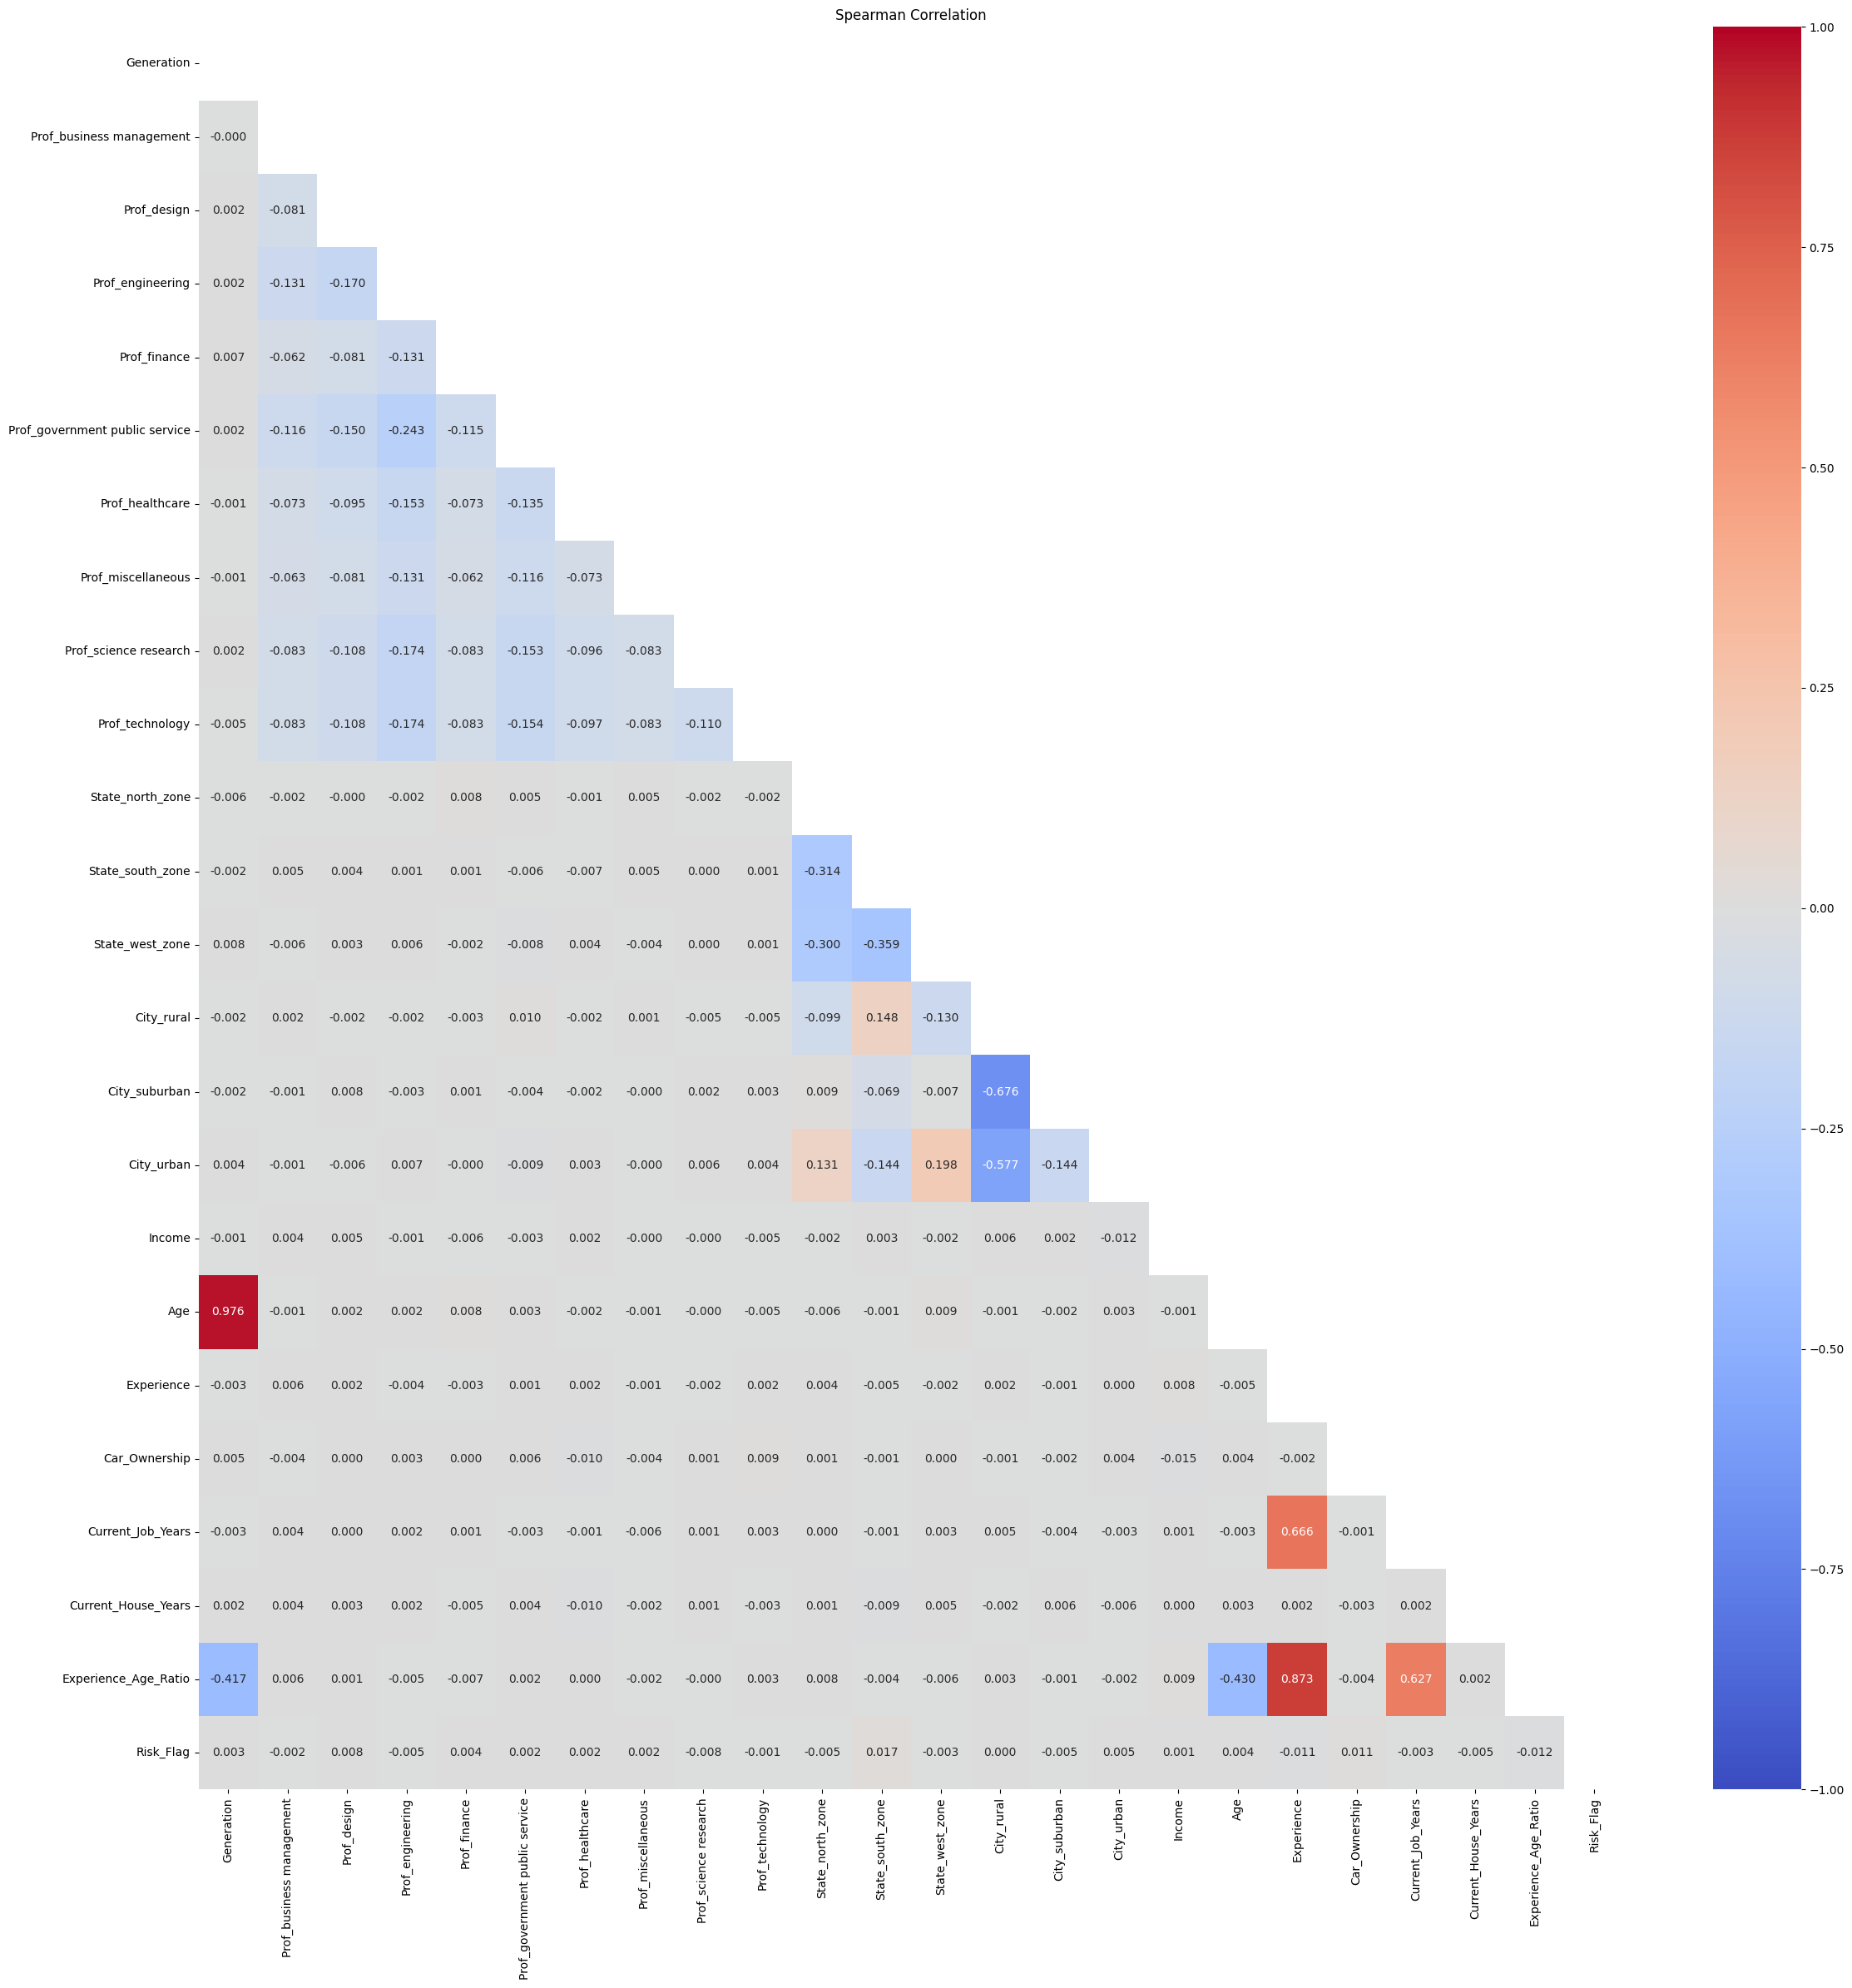

In [57]:
# Spearman correlation heatmap from the shared utils package
from utils import plot_correlation_heatmap

plot_correlation_heatmap(
    df_feature_selection,
    col_series=df_feature_selection.columns,
    corr_method='spearman',
    figsize=(24, 24),
)


In [58]:
# Correlation tables from the shared utils package
from utils import calculate_correlation_tabular

corr_feature, corr_final = calculate_correlation_tabular(
    df_feature_selection, target_col='Risk_Flag', method='spearman', corr_type='both'
)


Correlation Between Features:


,A,B,Corr Value,Corr Type
0,Age,Generation,0.976024,Positive
1,Experience,Experience_Age_Ratio,0.872598,Positive
2,City_rural,City_suburban,0.676336,Negative
3,Current_Job_Years,Experience,0.666470,Positive
4,Current_Job_Years,Experience_Age_Ratio,0.626845,Positive
5,City_rural,City_urban,0.577118,Negative
6,Age,Experience_Age_Ratio,0.429554,Negative
7,Experience_Age_Ratio,Generation,0.416870,Negative
8,State_south_zone,State_west_zone,0.358764,Negative
9,State_north_zone,State_south_zone,0.314187,Negative



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,State_south_zone,0.016780,Positive
1,Experience_Age_Ratio,0.012238,Negative
2,Car_Ownership,0.011265,Positive
3,Experience,0.010709,Negative
4,Prof_science research,0.007770,Negative
5,Prof_design,0.007752,Positive
6,City_suburban,0.005366,Negative
7,State_north_zone,0.005268,Negative
8,City_urban,0.005148,Positive
9,Current_House_Years,0.004781,Negative


### Checking multicolinearity using Variance Inflation Factor (VIF)

VIF measures how much a feature's variance is inflated by its linear relationship with the other features: `VIF = 1 / (1 - R²)`. VIF > 10 indicates high multicollinearity and > 5 moderate. It is most relevant for coefficient-based models; tree-based models tolerate correlated predictors better.


In [59]:
# VIF analysis now comes from the shared utils package
from utils import calculate_vif

# VIF calculation function usage
vif_results = calculate_vif(df_encoding, 'Risk_Flag')
display(vif_results)

,Feature,VIF,Interpretation
0,Age,20.702971,High multicollinearity
1,Generation,17.625769,High multicollinearity
2,City_rural,12.793325,High multicollinearity
3,City_suburban,8.730236,Moderate multicollinearity
4,Experience_Age_Ratio,7.640559,Moderate multicollinearity
5,City_urban,7.174062,Moderate multicollinearity
6,Experience,6.517802,Moderate multicollinearity
7,Prof_engineering,3.633583,Low multicollinearity
8,Prof_government public service,3.271253,Low multicollinearity
9,Prof_technology,2.409431,Low multicollinearity


### Checking feature importance using SelectKBest (Mutual information, Chi2, and ANOVA F-test)

**SelectKBest scores used here:** `mutual_info_classif` captures linear and non-linear dependence, `chi2` tests independence between non-negative features and the target, and `f_classif` (ANOVA) tests differences in feature means across classes. Agreement across the three is stronger evidence than any single score.


In [60]:
# Work on a copy with a categorical target for the SelectKBest helpers
df_feature_target_relation = df_feature_selection.copy()
change_target_dtype(df_feature_target_relation, target_type='categorical')


In [61]:
# Feature-importance scoring from the shared utils package
from utils import calculate_feature_importance

x_features_test = df_feature_target_relation.drop(columns=['Risk_Flag'])
y_target_test = df_feature_target_relation['Risk_Flag']

mi_scores_df = calculate_feature_importance(
    x_features_test, y_target_test, task='classification', method='mutual_info'
)
chi2_scores_df = calculate_feature_importance(
    x_features_test, y_target_test, task='classification', method='chi2'
)
anova_scores_df = calculate_feature_importance(
    x_features_test, y_target_test, task='classification', method='anova'
)

print('Mutual Information:')
display(mi_scores_df.iloc[:15].reset_index(drop=True))
print('Chi2 Test:')
display(chi2_scores_df.iloc[:15].reset_index(drop=True))
print('ANOVA F-test:')
display(anova_scores_df.iloc[:15].reset_index(drop=True))

print('Spearman Correlation:')
display(corr_final.iloc[:15].reset_index(drop=True))


Mutual Information:


,Feature,Score,P_Values
0,City_rural,0.005077,None
1,State_south_zone,0.004270,None
2,Car_Ownership,0.003964,None
3,Current_House_Years,0.002409,None
4,City_urban,0.001529,None
5,Generation,0.001185,None
6,Prof_engineering,0.001160,None
7,City_suburban,0.001073,None
8,State_north_zone,0.000879,None
9,Experience,0.000716,None


Chi2 Test:


,Feature,Score,P_Values
0,Income,19950.395405,0.000000
1,Experience,18.062357,0.000021
2,State_south_zone,8.839589,0.002948
3,Car_Ownership,3.860605,0.049432
4,Age,3.688332,0.054794
5,Prof_science research,2.349470,0.125326
6,Prof_design,2.347361,0.125495
7,Current_Job_Years,1.113784,0.291261
8,City_suburban,1.064360,0.302223
9,City_urban,1.019428,0.312655


ANOVA F-test:


,Feature,Score,P_Values
0,State_south_zone,12.163843,0.000488
1,Car_Ownership,5.481328,0.019225
2,Experience_Age_Ratio,5.248461,0.021971
3,Experience,4.948322,0.026121
4,Prof_science research,2.607272,0.106382
5,Prof_design,2.595462,0.107178
6,City_suburban,1.243647,0.264776
7,State_north_zone,1.198753,0.273577
8,City_urban,1.144452,0.284720
9,Current_House_Years,0.992290,0.319189


Spearman Correlation:


,Feature,Corr Value,Corr Type
0,State_south_zone,0.016780,Positive
1,Experience_Age_Ratio,0.012238,Negative
2,Car_Ownership,0.011265,Positive
3,Experience,0.010709,Negative
4,Prof_science research,0.007770,Negative
5,Prof_design,0.007752,Positive
6,City_suburban,0.005366,Negative
7,State_north_zone,0.005268,Negative
8,City_urban,0.005148,Positive
9,Current_House_Years,0.004781,Negative


- It can be seen that the results obtained using several test utilizing SelectKBest are quite different from the results of feature-target correlation calculation using `df.corr()`, especially with the mutual_info_classif method which is more robust in capturing non-linear feature-target relationships.

- In this method, it was found that the most relevant feature to the Risk_Flag is related to Experience  or age. When we test it with Chi2 however, the feature that have most assosiation with target is Income, which actually sounds reasonable.

In [62]:
# Select only relevant features for each cases before moving to modelling process
df_model = df_feature_selection.copy()

# Important features only based on correlation and K-best parameter (correlation > 0.7 will be dropped)
selected_features = ['Income', 'Car_Ownership', 'Current_House_Years', 'Generation',
                     'Prof_business management', 'Prof_design', 'Prof_engineering',
                     'Prof_finance', 'Prof_government public service', 'Prof_healthcare',
                     'Prof_miscellaneous', 'Prof_science research', 'Prof_technology',
                     'State_north_zone', 'State_south_zone', 'State_west_zone',
                     'City_rural', 'City_suburban', 'City_urban',
                     'Experience_Age_Ratio', 'Risk_Flag']

df_model = df_model[selected_features]

- In this section, features will be selected based on their influence on the target variable as observed in the correlation values (df.corr()) and relevance (SelectKBest) to the target above. This may vary depending on the modeling phase and experimentation with which features to include.

- Some features will be dropped due to high correlation with other features as seen in the df.corr() results (because they are redundant, only one will be retained).

- The one-hot encoded features will all be included even if there is only one feature from the original, so in this case we will use all of the one-hot encoded from profession, state, and city.

In [63]:
# Export the model-ready frame. The Streamlit app fits its preprocessing
# from this file, so re-running the notebook keeps app and notebook aligned.
df_model.to_csv('data/df_model_rewrite.csv', index=False)
print(f'Exported {df_model.shape[0]:,} rows x {df_model.shape[1]} columns')


Exported 43,190 rows x 21 columns


## Split Train and Test Data

In [64]:
# Splitting data into train-test
X = df_model.drop(columns=['Risk_Flag'])
y = df_model[['Risk_Flag']]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Reset indices so later steps align by position
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}, y_test: {y_test.shape}')


X_train: (32392, 20), X_test: (10798, 20)
y_train: (32392, 1), y_test: (10798, 1)


**Stratified split.** A plain random split can shift the already-imbalanced class ratio. `stratify=y` keeps the default rate the same in train and test; the cell below confirms it.


In [65]:
# Checking imbalance before and after train-test split
value_counts_original = y.value_counts()
percentage_values_original = (value_counts_original / len(y)) * 100
print(f"Imbalance before train test split :")
print(percentage_values_original)
print()

# Checking imbalance after train-test split
value_counts_split = y_train.value_counts()
percentage_values_split = (value_counts_split / len(y_train)) * 100
print(f"Imbalance after train test split :")
print(percentage_values_split)

Imbalance before train test split :
Risk_Flag
0            80.451493
1            19.548507
Name: count, dtype: float64

Imbalance after train test split :
Risk_Flag
0            80.451963
1            19.548037
Name: count, dtype: float64


As we can see that using the stratify parameter, we can keep the imbalance proportion the same between original data and splitted train-test data.

## Feature Scaling

Train Data Distribution Before Scaling: 


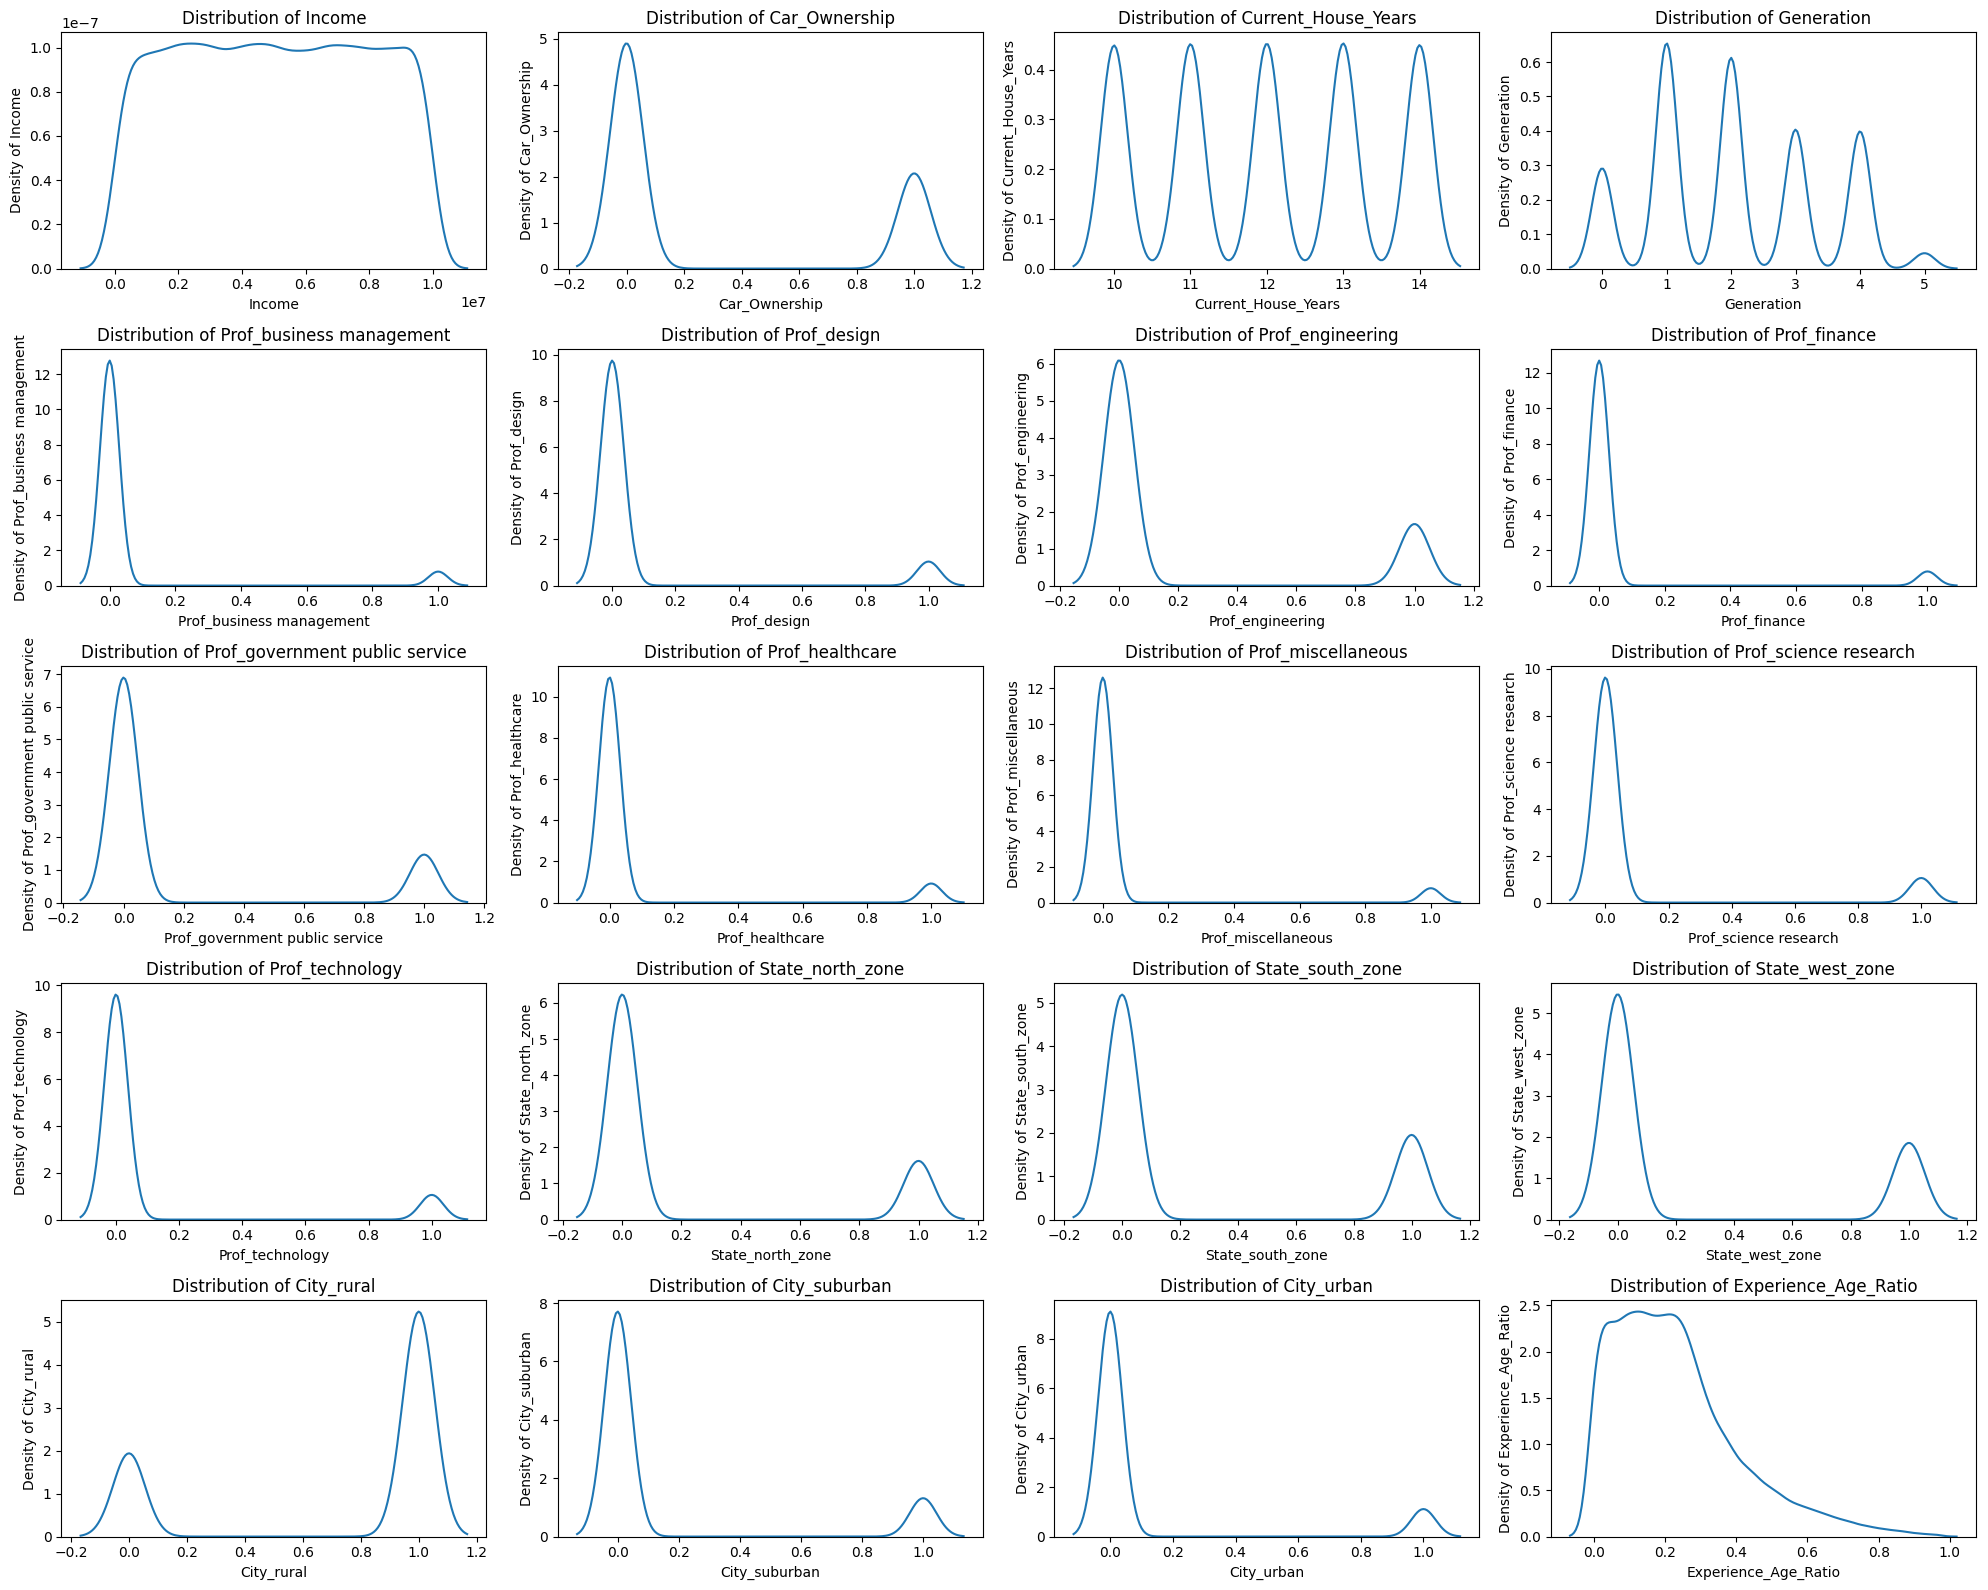

Test Data Distribution Before Scaling: 


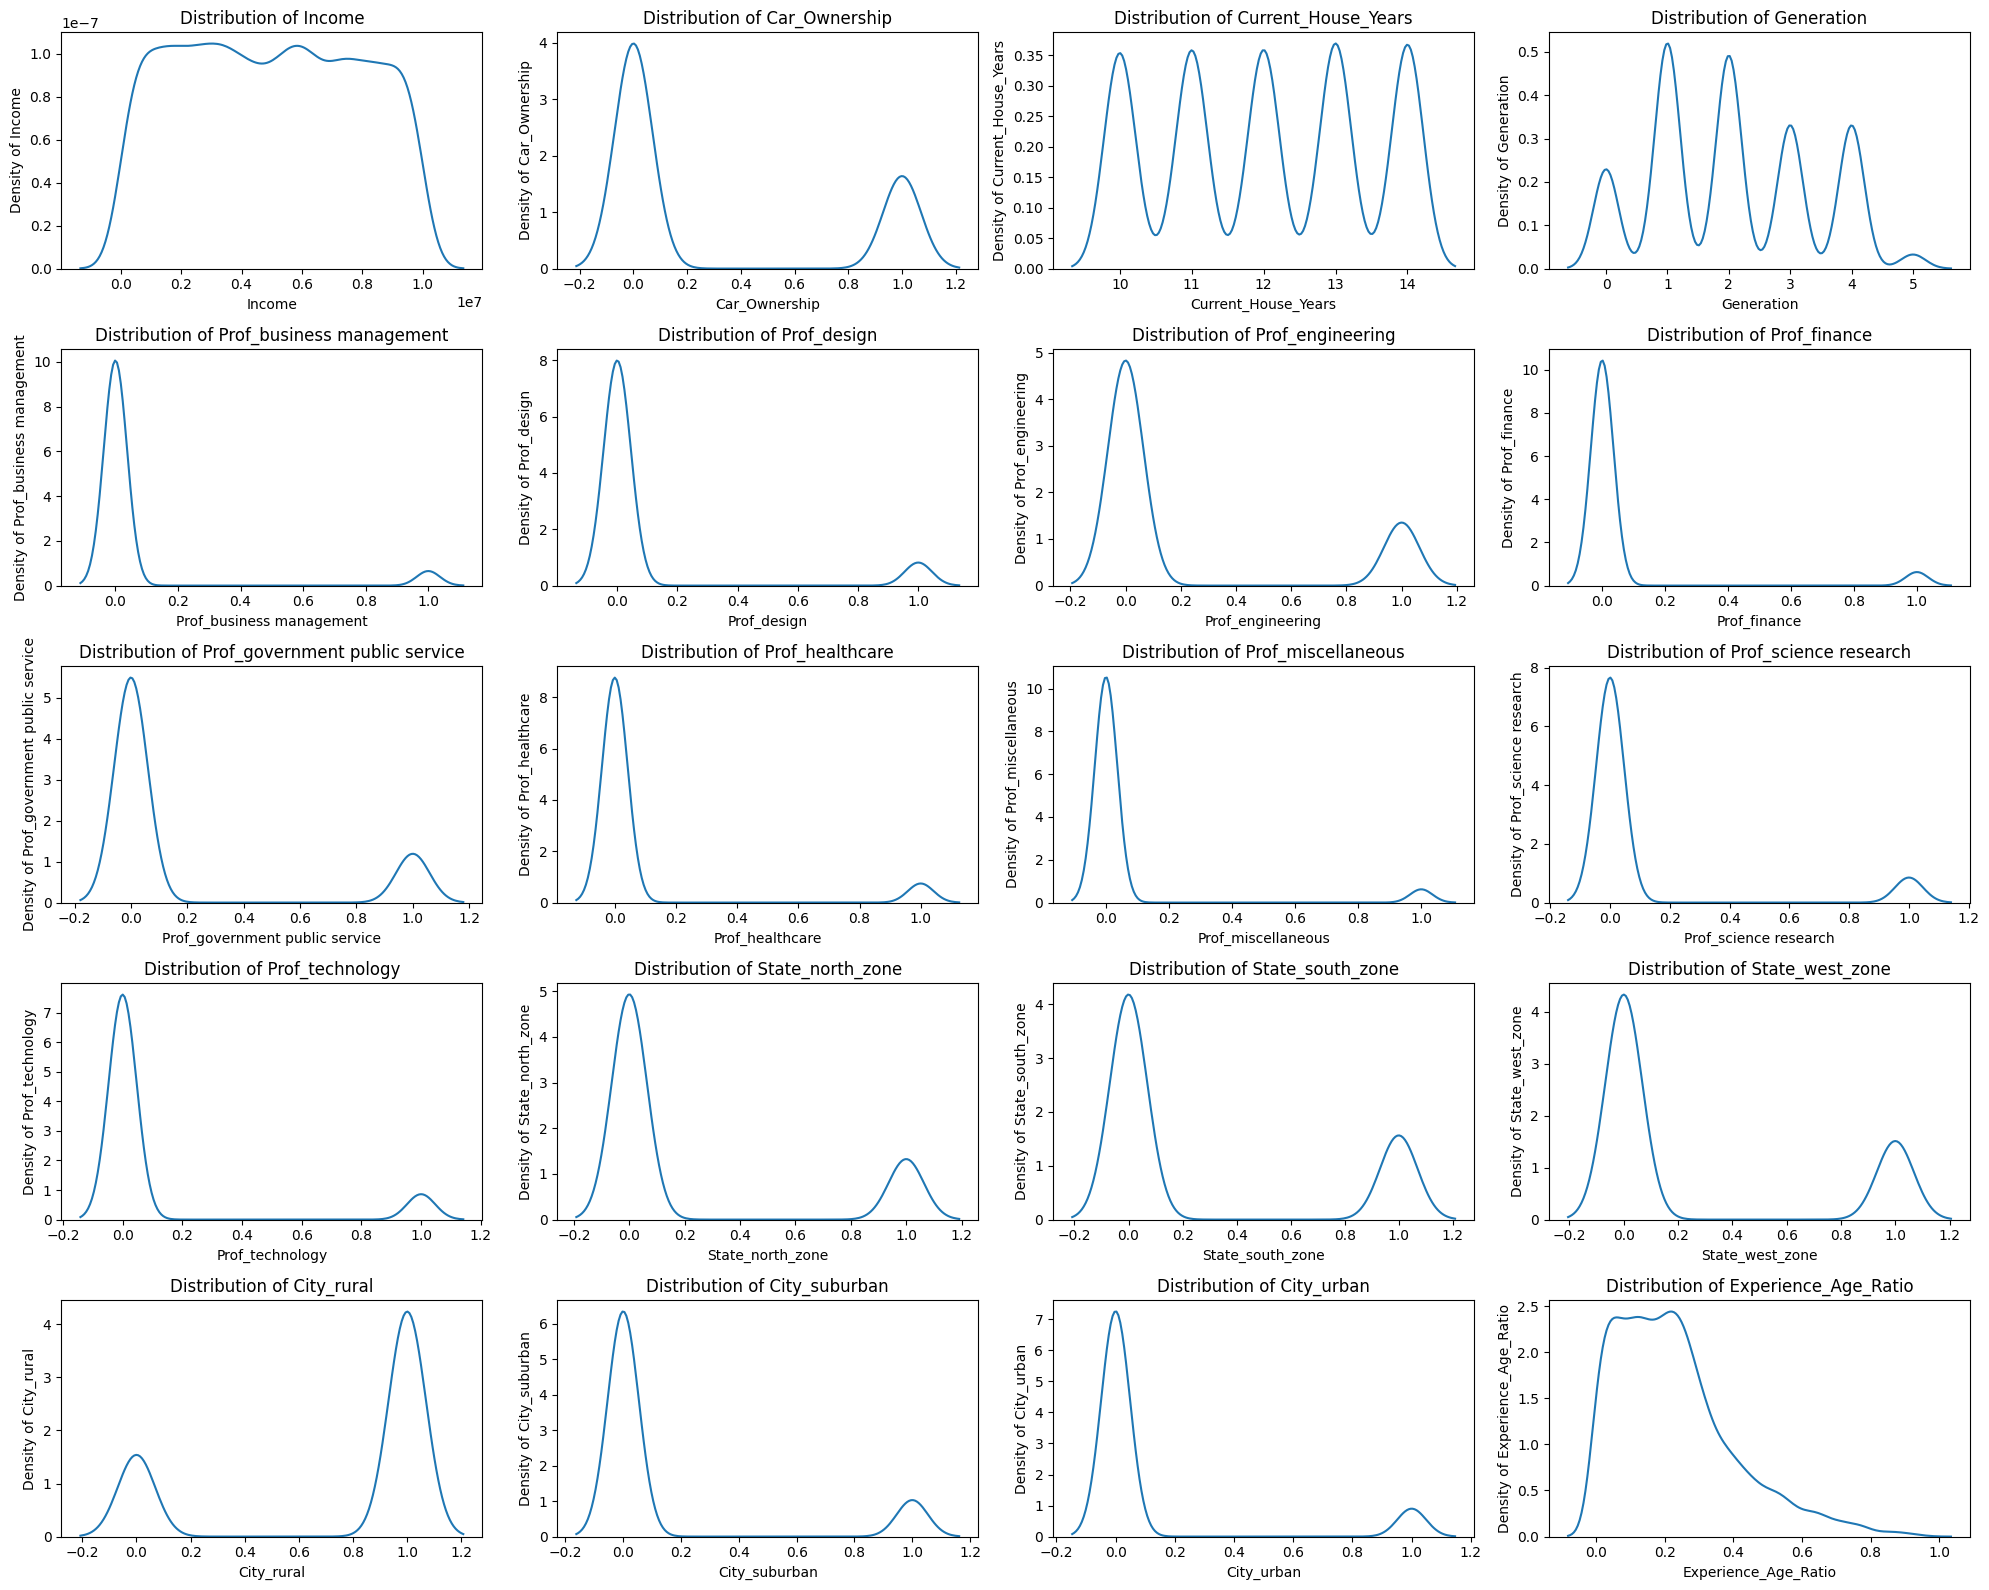

In [66]:
# Checking distribution before scaling
print("Train Data Distribution Before Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X_train, col_series=X_train.columns, plot_type='kdeplot', ncols=4, figsize=(20, 16))

print("Test Data Distribution Before Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X_test, col_series=X_test.columns, plot_type='kdeplot', ncols=4, figsize=(20, 16))

In [67]:
# Scaling from the shared utils package. The deployed model uses MinMax on
# Income and log1p + StandardScaler on Experience_Age_Ratio.
from utils import feature_scaling

scaling_config = {
    'minmax': {'columns': ['Income']},
    'standard': {'columns': ['Experience_Age_Ratio'], 'apply_log': True},
}

X_train, scalers = feature_scaling(X_train, scaling_config=scaling_config)
X_test, _ = feature_scaling(X_test, scaling_config=scaling_config, scaler=scalers)

# Saved for reference; the Streamlit app refits the same configuration.
os.makedirs('models', exist_ok=True)
joblib.dump(scalers, 'models/feature_scalers.joblib')

['models/feature_scalers.joblib']

Train Data Distribution After Scaling: 


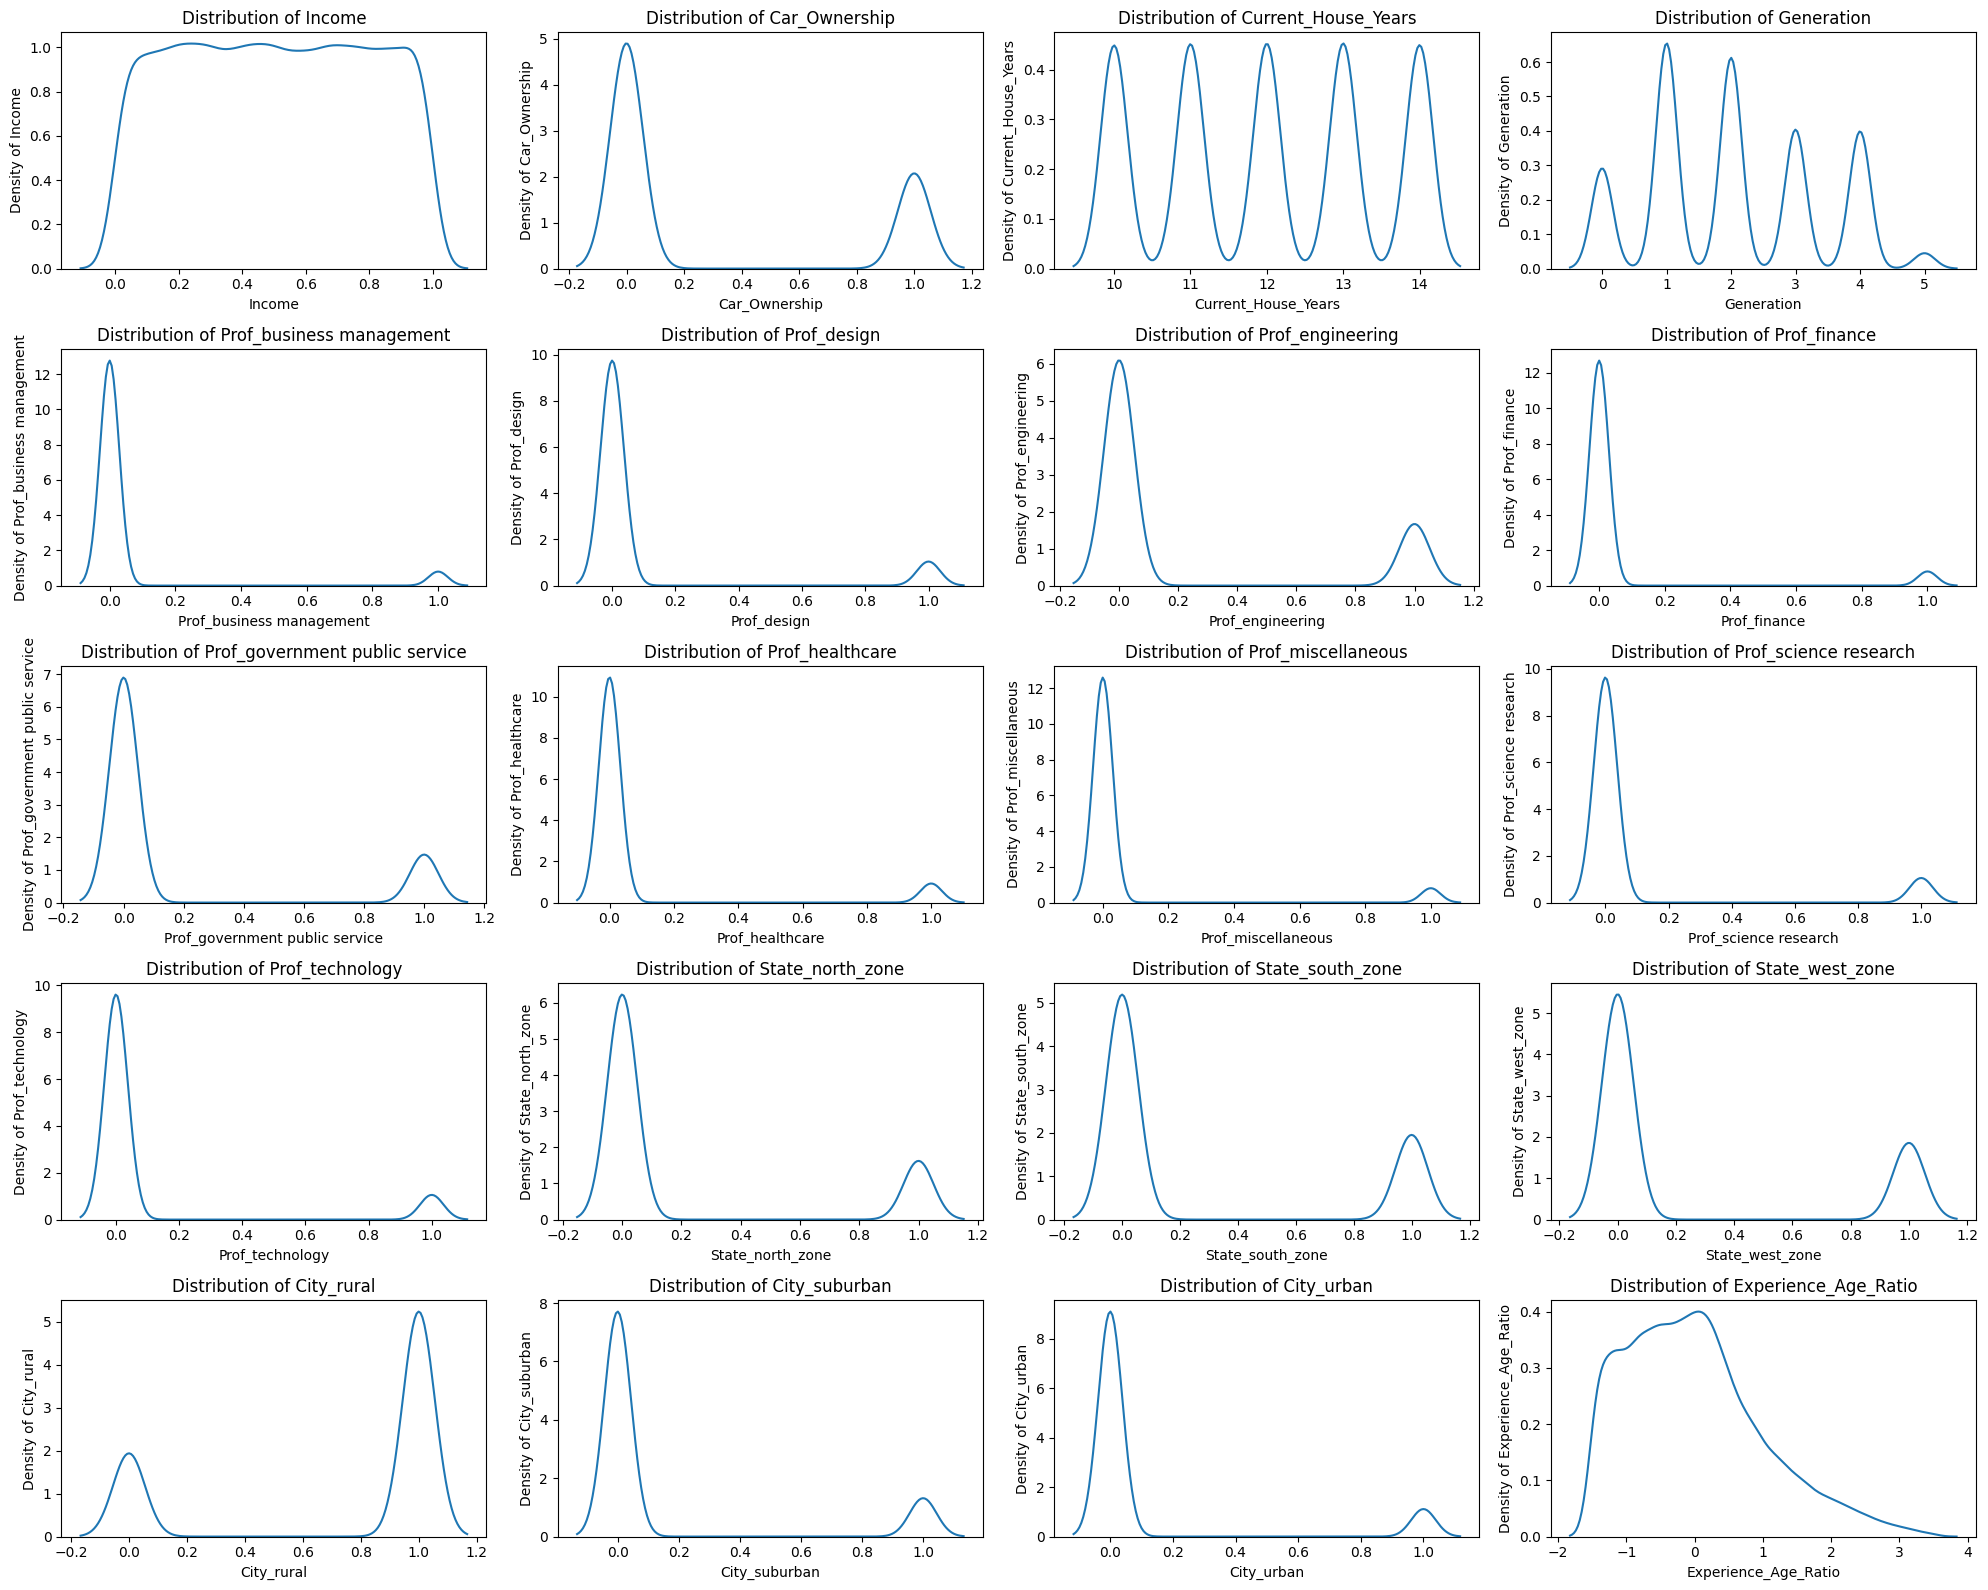

Test Data Distribution After Scaling: 


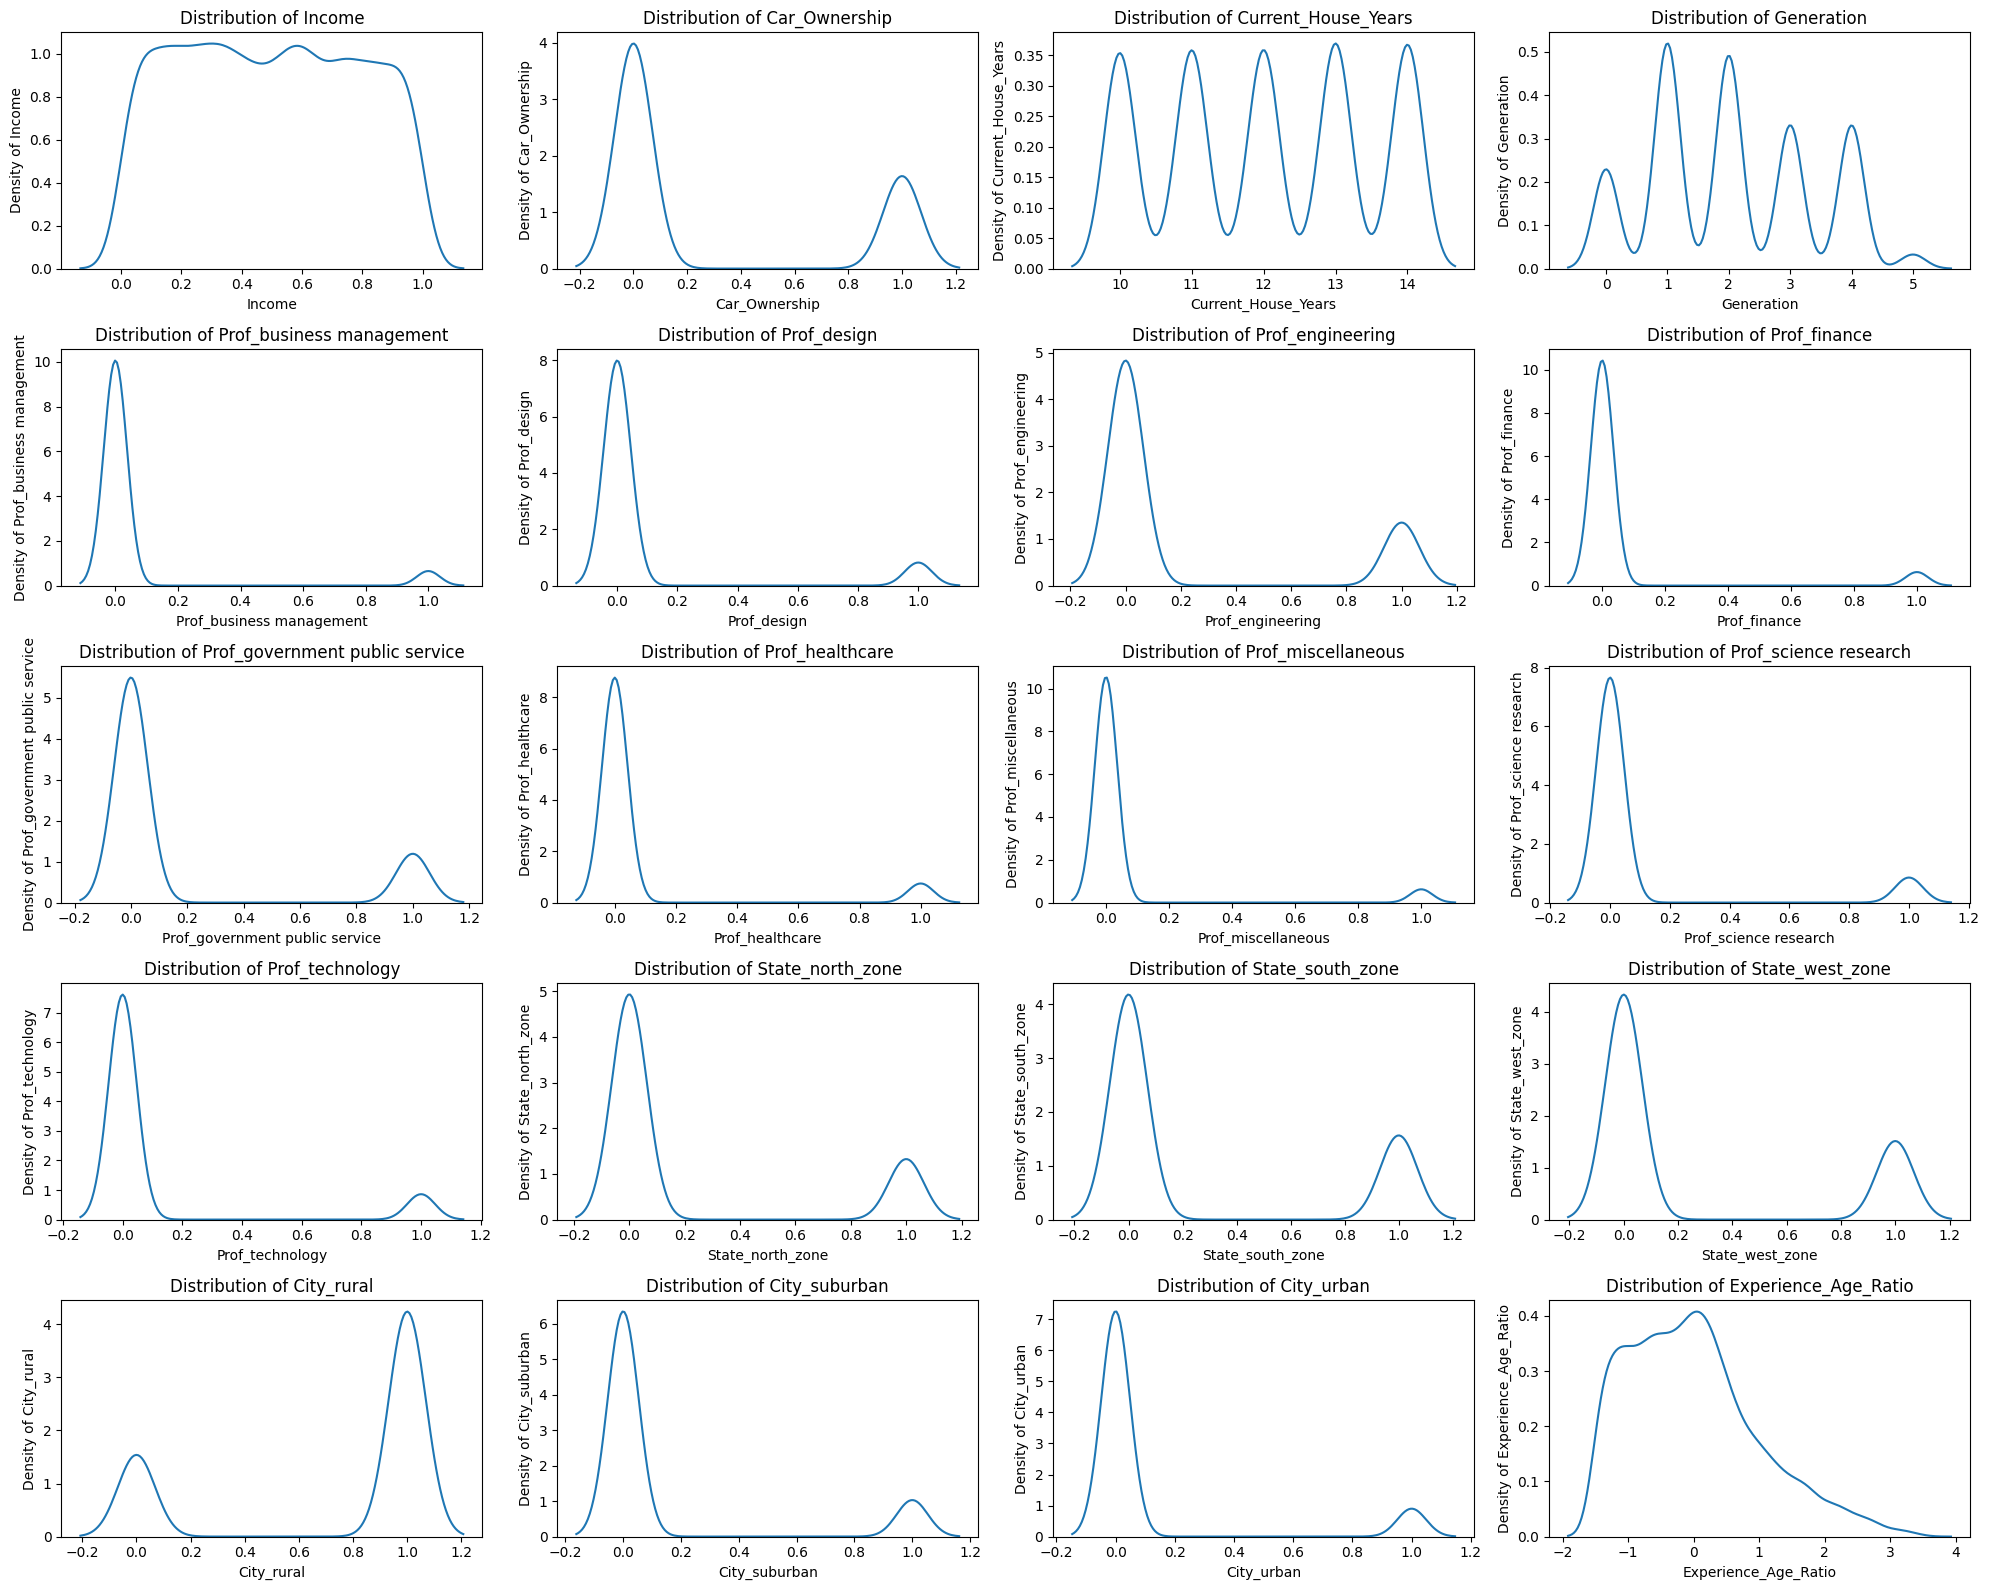

In [68]:
# Checking distribution after scaling
print("Train Data Distribution After Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X_train, col_series=X_train.columns, plot_type='kdeplot', ncols=4, figsize=(20, 16))

print("Test Data Distribution After Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X_test, col_series=X_test.columns, plot_type='kdeplot', ncols=4, figsize=(20, 16))

As seen on the figure above that, we already handled the scaling for `Income` and `Experience_Age_Ratio` feature.

## Handling Class Imbalance

One last thing that we need to do is to handle the class imbalance of the dependent/target variable.

In [69]:
# SMOTE balances the training set only. Validation folds and the test set
# must stay untouched; the leak-free evaluation below respects that.
from imblearn.over_sampling import SMOTE

print('Before SMOTE:')
print(y_train.value_counts().to_dict())

X_train_resampled, y_train_resampled = SMOTE(
    sampling_strategy=1.0, random_state=42, k_neighbors=5
).fit_resample(X_train, y_train)

print('After SMOTE:')
print(pd.Series(np.ravel(y_train_resampled)).value_counts().to_dict())
print(f'Resampled training shape: {X_train_resampled.shape}')

Before SMOTE:
{(0,): 26060, (1,): 6332}
After SMOTE:
{0: 26060, 1: 26060}
Resampled training shape: (52120, 20)


# **STAGE 3 : MODELLING AND EVALUATION**

## Traditional Machine Learning Algorithm

### Helper Function

In [70]:
# Evaluation and tuning helpers come from the shared utils package.
from sklearn.pipeline import Pipeline
from utils.classification_evals_and_tuning import eval_classification, tune_pipelines

Remember that in this dataset, 0 means non-default (non-default payment) and 1 means default.

- False Positive: Actual is non-default but predicted as default.
- False Negative: Actual is default but predicted as non-default.

**In this case, we want to minimize False Negatives as much as possible, so the primary metric to be evaluated is recall (although every metric will still be displayed).**

### Train Vanilla Models

Initial train using default hyperparameters.

In [71]:
# Import model libraries
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
# from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [72]:
# Initiatialize object for each model and store in a iterable
lr = LogisticRegression(random_state=42)
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier(random_state=42)
# svm = SVC(random_state=42, probability=True)
rf = RandomForestClassifier(random_state=42)
ada = AdaBoostClassifier(random_state=42)
gb = GradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42)

models = [lr, knn, dt, rf, ada, gb, xgb]

# Train models
for model in models :
    model.fit(X_train_resampled, y_train_resampled)

> Note: Tried with Support Vector Machine (SVM) algorithm, the result was not good and it takes way too much time to run compared to others so we won't be using it.

### Evaluate Vanilla Models (leaky CV diagnostic)

> **Do not quote the CV numbers below as generalization performance.** These calls use `X_train_resampled`, which was SMOTE-resampled before cross-validation. Synthetic rows leak into validation folds, so the CV metrics are optimistically biased. The single-run **Test** metrics use the real `X_test` and are honest; the corrected summary is in the **Honest Evaluation** section.


#### Logistic Regression

Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  57.96 ± 0.45
  Train: 58.05 ± 0.16

PRECISION:
  Test:  59.71 ± 0.48
  Train: 59.81 ± 0.26

RECALL:
  Test:  48.91 ± 1.10
  Train: 49.07 ± 0.58

F1:
  Test:  53.77 ± 0.77
  Train: 53.91 ± 0.32

ROC_AUC:
  Test:  61.34 ± 0.43
  Train: 61.50 ± 0.12

Single Run Metrics:

ACCURACY:
  Test:  60.52
  Train: 58.11

PRECISION:
  Test:  19.34
  Train: 59.73

RECALL:
  Test:  32.16
  Train: 49.79

F1:
  Test:  24.16
  Train: 54.31

ROC_AUC:
  Test:  49.29
  Train: 61.49


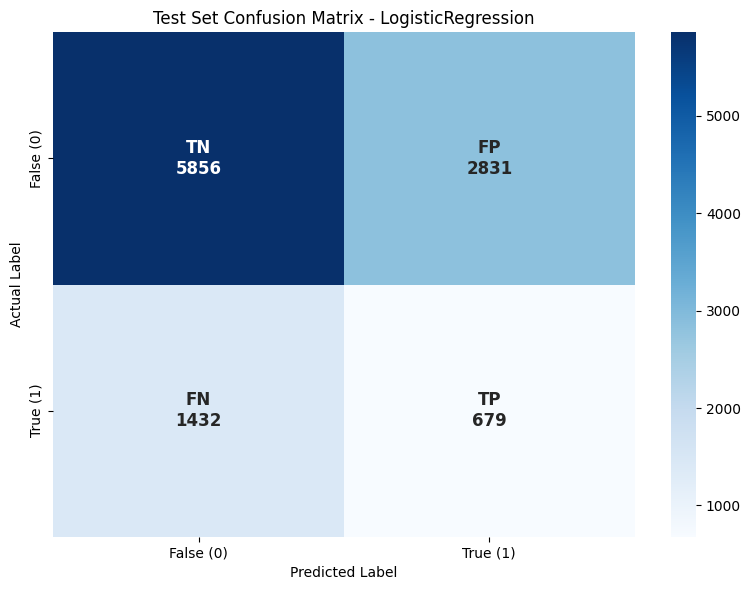

In [73]:
metrics_vanilla_lr = eval_classification(model=lr,
                                         X_train=X_train_resampled,
                                         y_train=y_train_resampled,
                                         X_test=X_test,
                                         y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### K-Nearest Neighbours

Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  70.79 ± 0.35
  Train: 80.79 ± 0.12

PRECISION:
  Test:  66.71 ± 0.32
  Train: 75.71 ± 0.15

RECALL:
  Test:  82.98 ± 0.41
  Train: 90.68 ± 0.13

F1:
  Test:  73.96 ± 0.30
  Train: 82.52 ± 0.10

ROC_AUC:
  Test:  77.39 ± 0.44
  Train: 90.54 ± 0.06

Single Run Metrics:

ACCURACY:
  Test:  55.34
  Train: 81.86

PRECISION:
  Test:  18.80
  Train: 76.59

RECALL:
  Test:  38.70
  Train: 91.79

F1:
  Test:  25.31
  Train: 83.50

ROC_AUC:
  Test:  49.17
  Train: 91.64


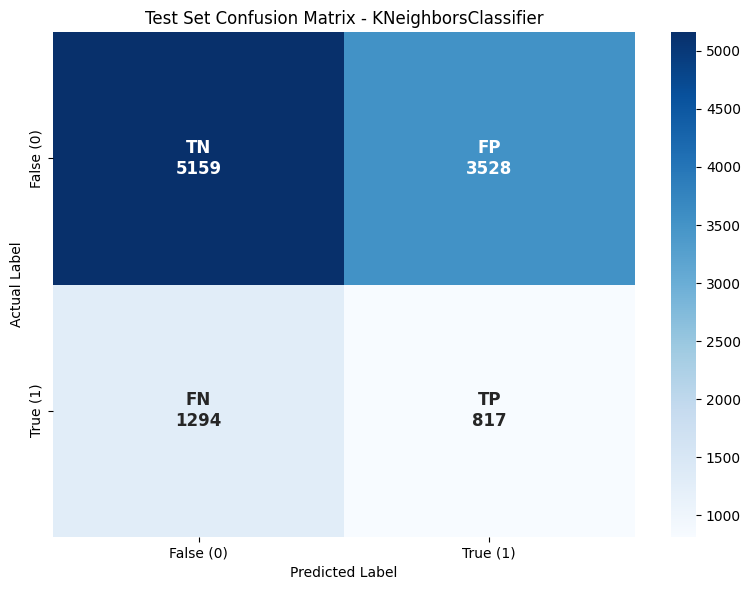

In [74]:
metrics_vanilla_knn = eval_classification(model=knn,
                                          X_train=X_train_resampled,
                                          y_train=y_train_resampled,
                                          X_test=X_test,
                                          y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### Decision Tree

Performance Metrics for DecisionTreeClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  62.61 ± 0.43
  Train: 98.99 ± 0.03

PRECISION:
  Test:  62.20 ± 0.42
  Train: 100.00 ± 0.00

RECALL:
  Test:  64.31 ± 0.63
  Train: 97.97 ± 0.06

F1:
  Test:  63.24 ± 0.46
  Train: 98.98 ± 0.03

ROC_AUC:
  Test:  62.79 ± 0.43
  Train: 99.98 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  56.45
  Train: 98.73

PRECISION:
  Test:  17.92
  Train: 100.00

RECALL:
  Test:  34.30
  Train: 97.47

F1:
  Test:  23.54
  Train: 98.72

ROC_AUC:
  Test:  47.92
  Train: 99.97


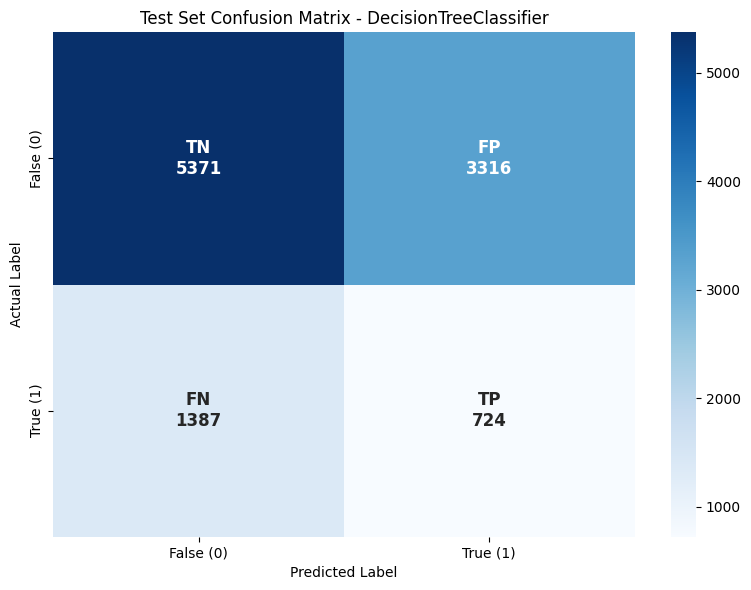

In [75]:
metrics_vanilla_dt = eval_classification(model=dt,
                                         X_train=X_train_resampled,
                                         y_train=y_train_resampled,
                                         X_test=X_test,
                                         y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### Random Forest

Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  75.49 ± 0.26
  Train: 98.99 ± 0.03

PRECISION:
  Test:  74.93 ± 0.34
  Train: 98.82 ± 0.07

RECALL:
  Test:  76.62 ± 0.38
  Train: 99.16 ± 0.04

F1:
  Test:  75.76 ± 0.25
  Train: 98.99 ± 0.03

ROC_AUC:
  Test:  82.10 ± 0.30
  Train: 99.98 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  65.12
  Train: 98.73

PRECISION:
  Test:  16.89
  Train: 98.52

RECALL:
  Test:  19.99
  Train: 98.95

F1:
  Test:  18.31
  Train: 98.73

ROC_AUC:
  Test:  45.15
  Train: 99.97


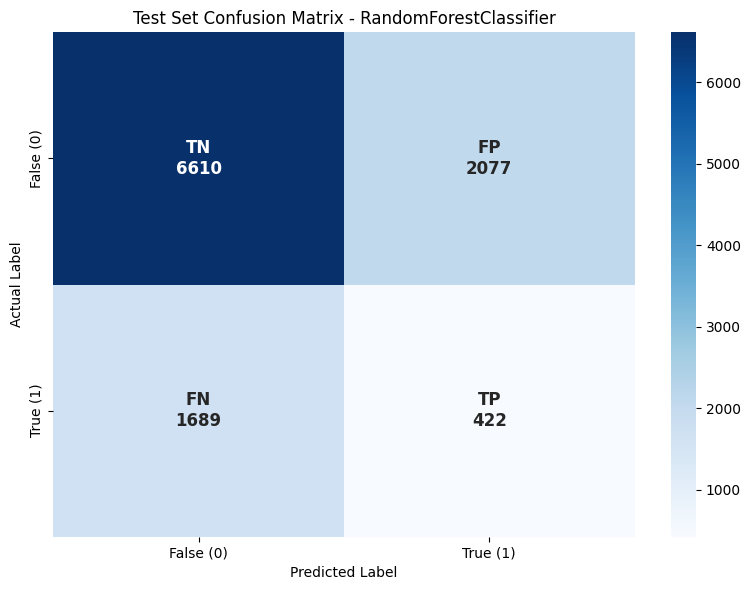

In [76]:
metrics_vanilla_rf = eval_classification(model=rf,
                                         X_train=X_train_resampled,
                                         y_train=y_train_resampled,
                                         X_test=X_test,
                                         y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### AdaBoost

Performance Metrics for AdaBoostClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  56.36 ± 0.54
  Train: 56.58 ± 0.15

PRECISION:
  Test:  55.11 ± 0.68
  Train: 55.26 ± 0.40

RECALL:
  Test:  69.15 ± 4.47
  Train: 69.43 ± 4.04

F1:
  Test:  61.25 ± 1.50
  Train: 61.48 ± 1.37

ROC_AUC:
  Test:  58.73 ± 0.58
  Train: 59.01 ± 0.25

Single Run Metrics:

ACCURACY:
  Test:  48.96
  Train: 56.72

PRECISION:
  Test:  19.27
  Train: 55.83

RECALL:
  Test:  50.50
  Train: 64.37

F1:
  Test:  27.89
  Train: 59.79

ROC_AUC:
  Test:  49.39
  Train: 59.11


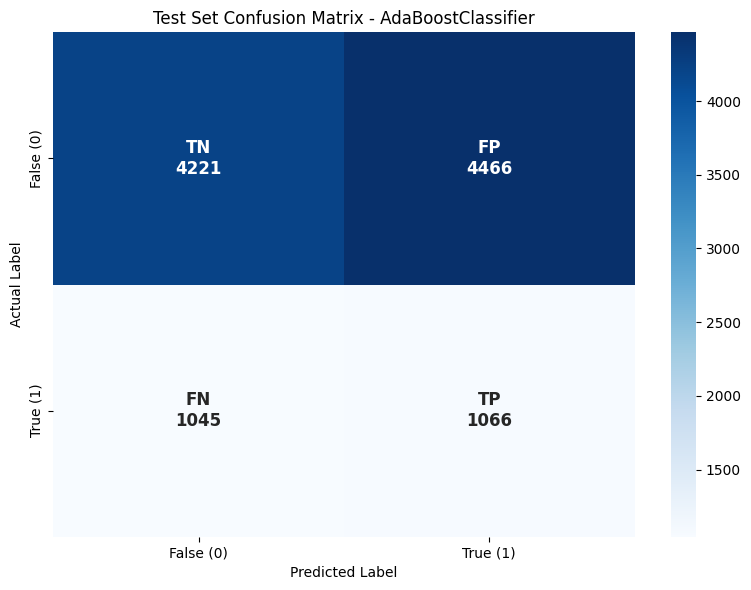

In [77]:
metrics_vanilla_ada = eval_classification(model=ada,
                                          X_train=X_train_resampled,
                                          y_train=y_train_resampled,
                                          X_test=X_test,
                                          y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### GradientBoost

Performance Metrics for GradientBoostingClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  60.12 ± 0.50
  Train: 61.31 ± 0.13

PRECISION:
  Test:  58.50 ± 0.40
  Train: 59.48 ± 0.14

RECALL:
  Test:  69.71 ± 1.15
  Train: 70.96 ± 0.60

F1:
  Test:  63.61 ± 0.62
  Train: 64.71 ± 0.23

ROC_AUC:
  Test:  64.62 ± 0.54
  Train: 66.20 ± 0.16

Single Run Metrics:

ACCURACY:
  Test:  50.36
  Train: 61.29

PRECISION:
  Test:  19.12
  Train: 59.50

RECALL:
  Test:  47.66
  Train: 70.70

F1:
  Test:  27.29
  Train: 64.62

ROC_AUC:
  Test:  49.07
  Train: 66.19


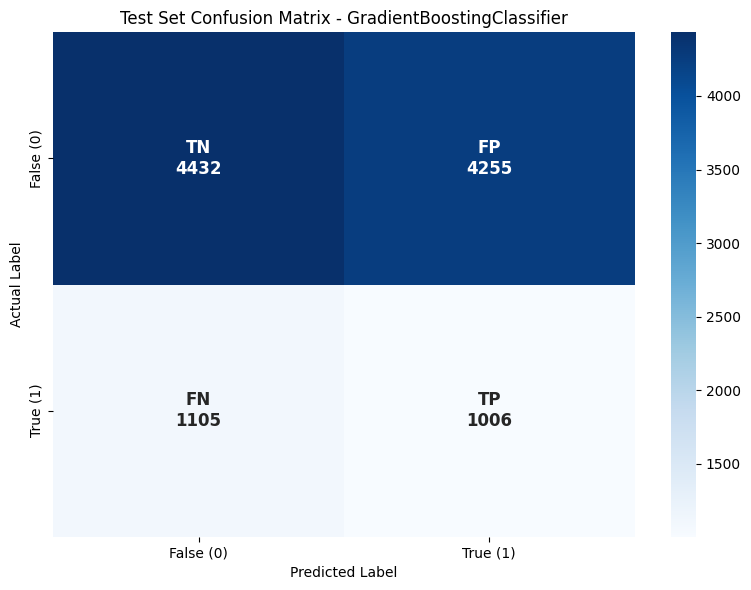

In [78]:
metrics_vanilla_gb = eval_classification(model=gb,
                                          X_train=X_train_resampled,
                                          y_train=y_train_resampled,
                                          X_test=X_test,
                                          y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### XGBoost

Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  65.88 ± 0.52
  Train: 75.29 ± 0.20

PRECISION:
  Test:  64.73 ± 0.47
  Train: 73.36 ± 0.13

RECALL:
  Test:  69.76 ± 0.86
  Train: 79.40 ± 0.42

F1:
  Test:  67.15 ± 0.57
  Train: 76.26 ± 0.24

ROC_AUC:
  Test:  72.20 ± 0.51
  Train: 83.84 ± 0.18

Single Run Metrics:

ACCURACY:
  Test:  57.17
  Train: 74.43

PRECISION:
  Test:  18.50
  Train: 72.51

RECALL:
  Test:  34.96
  Train: 78.70

F1:
  Test:  24.19
  Train: 75.48

ROC_AUC:
  Test:  48.47
  Train: 82.97


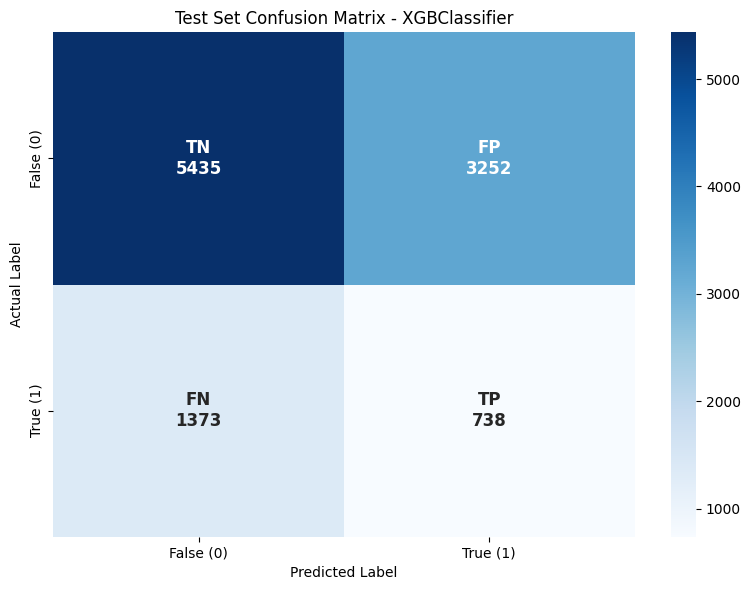

In [79]:
metrics_vanilla_xgb = eval_classification(model=xgb,
                                          X_train=X_train_resampled,
                                          y_train=y_train_resampled,
                                          X_test=X_test,
                                          y_test=y_test, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

### Vanilla Models Result Summary

In [80]:
# Vanilla-model comparison. CV columns are leaky; holdout columns are honest.
vanilla_models = {
    'Logistic Regression': metrics_vanilla_lr,
    'K-Nearest Neighbours': metrics_vanilla_knn,
    'Decision Tree': metrics_vanilla_dt,
    'Random Forest': metrics_vanilla_rf,
    'AdaBoost': metrics_vanilla_ada,
    'GradientBoost': metrics_vanilla_gb,
    'XGBoost': metrics_vanilla_xgb,
}

vanilla_summary = pd.DataFrame([
    {
        'Model': name,
        'CV Recall (leaky)': m['cv']['recall']['test_mean'],
        'Holdout Recall': m['recall']['test'],
        'Holdout ROC-AUC': m['roc_auc']['test'],
        'Holdout Accuracy': m['accuracy']['test'],
    }
    for name, m in vanilla_models.items()
]).sort_values('Holdout ROC-AUC', ascending=False, ignore_index=True)

display(vanilla_summary)

,Model,CV Recall (leaky),Holdout Recall,Holdout ROC-AUC,Holdout Accuracy
0,AdaBoost,0.691494,0.504974,0.493937,0.489628
1,Logistic Regression,0.489102,0.321649,0.492927,0.605205
2,K-Nearest Neighbours,0.829816,0.387020,0.491704,0.553436
3,GradientBoost,0.697058,0.476551,0.490671,0.503612
4,XGBoost,0.697634,0.349597,0.484736,0.571680
5,Decision Tree,0.643106,0.342965,0.479198,0.564456
6,Random Forest,0.766219,0.199905,0.451535,0.651232


### Hyperparameter Tuning

> Note: As for the parameter grid we make it into the format of dictionary for each model where each of them has another dictionary of parameters. This way when we want to do experimentation with other models we can just call the keys.

In [82]:
# Define hyperparameters for the three tuned models
def get_default_param_grid(model_type: str) -> dict:
    """
    Get the pipeline-prefixed hyperparameter grid for a tuned model.

    Parameters
    ----------
    model_type : str
        One of 'knn', 'rf', or 'xgb'.

    Returns
    -------
    dict
        Grid whose keys match the pipeline step names used below.
    """
    param_grids = {
        'knn': {
            'n_neighbors': [int(x) for x in range(7, 22) if x % 2 != 0],
            'weights': ['uniform', 'distance'],
            'p': [1, 2],
            'algorithm': ['auto', 'ball_tree', 'kd_tree'],
            'leaf_size': [15, 25, 35]
        },
        'rf': {
            'n_estimators': [10, 25, 50, 75, 100, 150, 200, 300],
            'criterion': ['gini', 'entropy'],
            'max_depth': [int(x) for x in np.linspace(3, 60, num=30)],
            'min_samples_split': [2, 5, 7, 10],
            'min_samples_leaf': [1, 2, 4, 6],
            'max_features': ['sqrt', 'log2'],
            'bootstrap': [True],
            'oob_score': [False],
            'class_weight': ['balanced', 'balanced_subsample'],
            'max_samples': [0.5, 0.6, 0.7, 0.95]
        },
        'xgb': {
            'eta': [float(x) for x in np.linspace(0.1, 1, 20)],
            'n_estimators': [10, 25, 50, 75, 150, 200, 300],
            'max_depth': [int(x) for x in np.linspace(3, 60, num=30)],
            'learning_rate': [0.0005, 0.01, 0.05, 0.1],
            'subsample': [0.5, 0.7, 0.9, 1.0],
            'colsample_bytree': [0.7, 0.9, 1.0],
            'min_child_weight': [1, 3, 5],
            'gamma': [0.1, 0.3, 0.5, 0.9, 1],
            'reg_alpha': [0, 0.1, 2],
            'reg_lambda': [0, 0.1, 2],
            'tree_method': ['auto', 'exact', 'hist'],
            'booster': ['gbtree', 'gblinear']
        }
    }

    # tune_pipelines expects pipeline-prefixed keys (e.g. knn__n_neighbors).
    return {
        f'{model_type}__{key}': value
        for key, value in param_grids[model_type].items()
    }

> **Note:** the grids below are already narrowed from the wider search space because a full `GridSearch` was too expensive. `tune_pipelines` uses `RandomizedSearchCV`.


#### Tuning K-Nearest Neighbours

In [ ]:
# Get default parameters for k-nearest neighbours
knn_param_grid = get_default_param_grid('knn')

# Tune a pipeline so the estimator configuration can be reused in deployment
knn_tuning_pipeline = Pipeline([('knn', KNeighborsClassifier())])

knn_tuned_models, knn_tuned_times = tune_pipelines(
    pipedict={'knn': knn_tuning_pipeline},
    param_grid={'knn': knn_param_grid},
    X_train=X_train_resampled,
    y_train=y_train_resampled,
    X_test=X_test,
    y_test=y_test,
    scoring='recall',
    search_method='random',
    n_iter=20,
    plot_learning_curves=True,
    progress_bar=True,
)

knn_tuned_search = knn_tuned_models['knn']
knn_tuned_time = knn_tuned_times[0]

#### Tuning Random Forest

In [ ]:
# Get default parameters for random forest
rf_param_grid = get_default_param_grid('rf')

rf_tuning_pipeline = Pipeline([('rf', RandomForestClassifier(random_state=42))])

rf_tuned_models, rf_tuned_times = tune_pipelines(
    pipedict={'rf': rf_tuning_pipeline},
    param_grid={'rf': rf_param_grid},
    X_train=X_train_resampled,
    y_train=y_train_resampled,
    X_test=X_test,
    y_test=y_test,
    scoring='recall',
    search_method='random',
    n_iter=20,
    plot_learning_curves=True,
    progress_bar=True,
)

rf_tuned_search = rf_tuned_models['rf']
rf_tuned_time = rf_tuned_times[0]

#### Tuning XGBoost

In [ ]:
# Get default parameters for XGBoost
xgb_param_grid = get_default_param_grid('xgb')

xgb_tuning_pipeline = Pipeline([('xgb', XGBClassifier(random_state=42))])

xgb_tuned_models, xgb_tuned_times = tune_pipelines(
    pipedict={'xgb': xgb_tuning_pipeline},
    param_grid={'xgb': xgb_param_grid},
    X_train=X_train_resampled,
    y_train=y_train_resampled,
    X_test=X_test,
    y_test=y_test,
    scoring='recall',
    search_method='random',
    n_iter=20,
    plot_learning_curves=True,
    progress_bar=True,
)

xgb_tuned_search = xgb_tuned_models['xgb']
xgb_tuned_time = xgb_tuned_times[0]

### Train Tuned Models

In [126]:
# Initiatialize object for each model and store in a iterable (if already default hyperparameter then not specified)
knn_tuned = KNeighborsClassifier(p=1, n_neighbors=19, weights='distance', leaf_size=25, algorithm='kd_tree')

rf_tuned = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_split=2, min_samples_leaf=1,
                                  max_features='log2', class_weight='balanced_subsample', max_samples=0.5, random_state=42)

xgb_tuned = XGBClassifier(eta=0.8578947368421053, n_estimators=200, max_depth=10, learning_rate=0.01, subsample=1.0, colsample_bytree=0.9, 
                          min_child_weight=5, gamma=0.1, reg_alpha=2, reg_lambda=0.1, tree_method='hist', booster='gbtree', random_state=42)

models_tuned = [knn_tuned, rf_tuned, xgb_tuned]

# Train models
for model in models_tuned :
    model.fit(X_train_resampled, y_train_resampled)

### Evaluate Tuned Models (leaky CV diagnostic)

> Same caveat as above: CV runs on SMOTE-resampled training data. Read the holdout columns in the summary table and the leak-free CV below, not the CV recall on resampled rows.


#### K-Nearest Neighbours

Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  71.04 ± 0.34
  Train: 98.99 ± 0.03

PRECISION:
  Test:  66.23 ± 0.33
  Train: 100.00 ± 0.00

RECALL:
  Test:  85.88 ± 0.23
  Train: 97.97 ± 0.06

F1:
  Test:  74.78 ± 0.24
  Train: 98.98 ± 0.03

ROC_AUC:
  Test:  80.11 ± 0.29
  Train: 99.98 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  53.70
  Train: 98.73

PRECISION:
  Test:  17.47
  Train: 100.00

RECALL:
  Test:  36.76
  Train: 97.47

F1:
  Test:  23.69
  Train: 98.72

ROC_AUC:
  Test:  43.99
  Train: 99.97


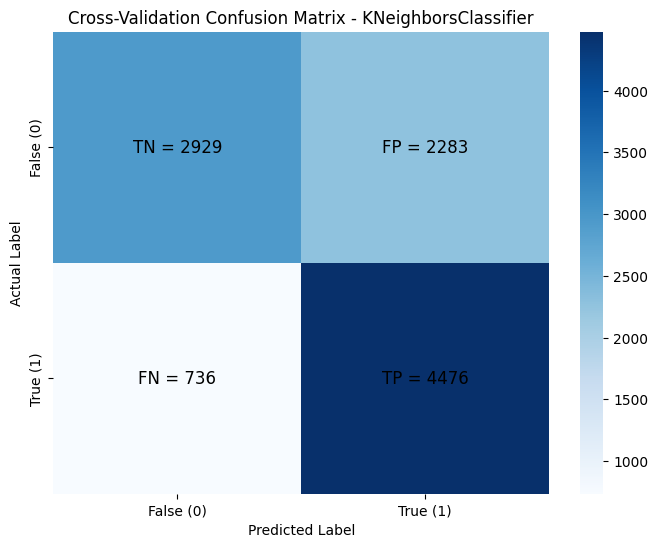

In [129]:
# Confusion matrix with cross validation
metrics_tuned_knn = eval_classification(model=knn_tuned,
                                        X_train=X_train_resampled,
                                        y_train=y_train_resampled,
                                        X_test=X_test,
                                        y_test=y_test,
                                        validate_confusion_matrix=True, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### Random Forest

Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  64.43 ± 0.51
  Train: 71.45 ± 0.33

PRECISION:
  Test:  61.53 ± 0.45
  Train: 66.85 ± 0.32

RECALL:
  Test:  77.05 ± 1.08
  Train: 85.09 ± 0.51

F1:
  Test:  68.41 ± 0.52
  Train: 74.88 ± 0.27

ROC_AUC:
  Test:  70.26 ± 0.61
  Train: 79.69 ± 0.32

Single Run Metrics:

ACCURACY:
  Test:  50.43
  Train: 70.27

PRECISION:
  Test:  18.79
  Train: 65.90

RECALL:
  Test:  46.23
  Train: 84.03

F1:
  Test:  26.72
  Train: 73.87

ROC_AUC:
  Test:  48.86
  Train: 78.28


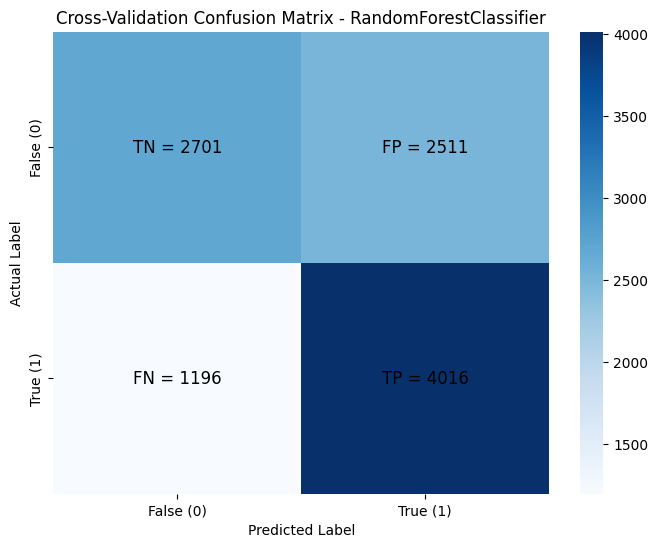

In [131]:
# Confusion matrix with cross validation
metrics_tuned_rf = eval_classification(model=rf_tuned,
                                       X_train=X_train_resampled,
                                       y_train=y_train_resampled,
                                       X_test=X_test,
                                       y_test=y_test,
                                       validate_confusion_matrix=True, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

#### XGBoost

Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  62.44 ± 0.39
  Train: 67.70 ± 0.33

PRECISION:
  Test:  60.16 ± 0.32
  Train: 64.39 ± 0.41

RECALL:
  Test:  73.68 ± 1.01
  Train: 79.22 ± 0.51

F1:
  Test:  66.23 ± 0.48
  Train: 71.04 ± 0.21

ROC_AUC:
  Test:  67.27 ± 0.65
  Train: 74.21 ± 0.42

Single Run Metrics:

ACCURACY:
  Test:  50.58
  Train: 67.40

PRECISION:
  Test:  18.97
  Train: 64.11

RECALL:
  Test:  46.71
  Train: 79.05

F1:
  Test:  26.98
  Train: 70.80

ROC_AUC:
  Test:  49.00
  Train: 73.86


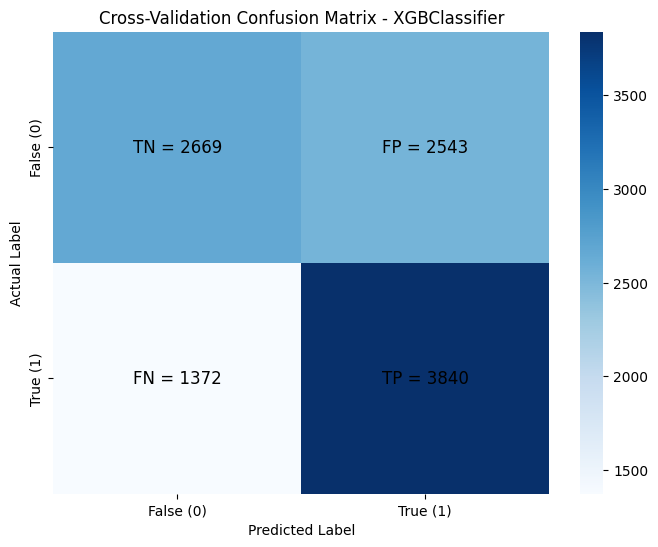

In [133]:
# Confusion matrix with cross validation
metrics_tuned_xgb = eval_classification(model=xgb_tuned,
                                        X_train=X_train_resampled,
                                        y_train=y_train_resampled,
                                        X_test=X_test,
                                        y_test=y_test,
                                        validate_confusion_matrix=True, plot_confusion_matrix=True, plot_roc_curve=False, plot_pr_curve=False, plot_calibration_curve=False, plot_threshold_analysis=False)

### Tuned Models Result Summary

In [ ]:
# Tuned-model comparison. CV columns are leaky; holdout columns are honest.
tuned_models = {
    'K-Nearest Neighbours': metrics_tuned_knn,
    'Random Forest': metrics_tuned_rf,
    'XGBoost': metrics_tuned_xgb,
}

tuned_summary = pd.DataFrame([
    {
        'Model': name,
        'CV Recall (leaky)': m['cv']['recall']['test_mean'],
        'Holdout Recall': m['recall']['test'],
        'Holdout ROC-AUC': m['roc_auc']['test'],
        'Holdout Accuracy': m['accuracy']['test'],
    }
    for name, m in tuned_models.items()
]).sort_values('Holdout ROC-AUC', ascending=False, ignore_index=True)

display(tuned_summary)

## Honest Evaluation (leak-free)

The CV numbers above were computed on `X_train_resampled`, so SMOTE had already created synthetic rows before the folds were drawn. That is leakage.

This section evaluates the deployed KNN two honest ways:

1. **Holdout** — the untouched 25% `X_test`.
2. **Leak-free CV** — SMOTE is fitted *inside* each training fold, never on the whole training set first.

Re-run the cells below to refresh every number used in the comparison table and the business simulation.


Performance Metrics for Pipeline:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  59.79 ± 0.29
  Train: 98.37 ± 0.05

PRECISION:
  Test:  17.63 ± 0.49
  Train: 100.00 ± 0.00

RECALL:
  Test:  28.80 ± 0.97
  Train: 91.64 ± 0.25

F1:
  Test:  21.87 ± 0.65
  Train: 95.64 ± 0.14

ROC_AUC:
  Test:  45.06 ± 0.49
  Train: 99.92 ± 0.01

Single Run Metrics:

ACCURACY:
  Test:  53.70
  Train: 97.96

PRECISION:
  Test:  17.47
  Train: 100.00

RECALL:
  Test:  36.76
  Train: 89.58

F1:
  Test:  23.69
  Train: 94.50

ROC_AUC:
  Test:  43.99
  Train: 99.87


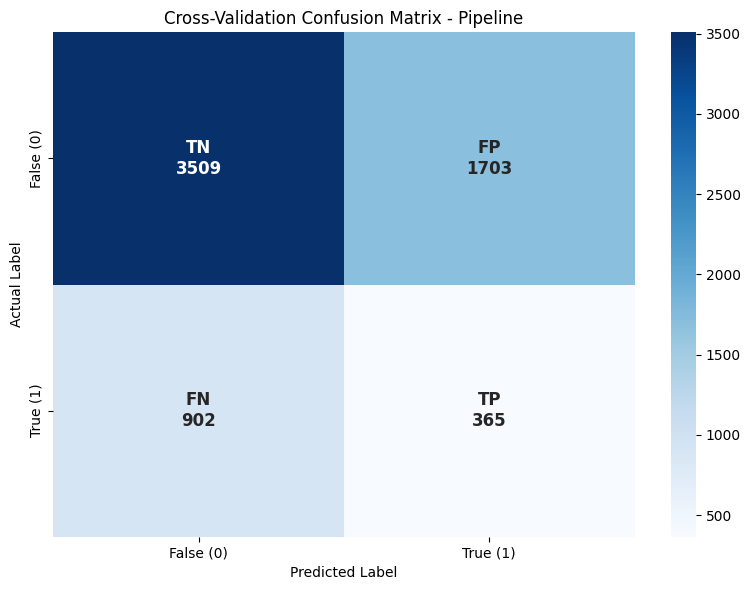

In [81]:
# Leak-free evaluation: SMOTE is fitted inside each CV fold, never before it.
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

knn_honest_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier(
        algorithm='kd_tree',
        leaf_size=25,
        n_neighbors=19,
        p=1,
        weights='distance',
    )),
])

# Fit once for the honest single-run holdout metrics.
knn_honest_pipeline.fit(X_train, y_train)

metrics_honest_knn = eval_classification(
    model=knn_honest_pipeline,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    plot_confusion_matrix=True,
    plot_roc_curve=False,
    plot_pr_curve=False,
    plot_calibration_curve=False,
    plot_threshold_analysis=False,
    validate_confusion_matrix=True,
)

In [ ]:
# Side-by-side: the old leaky number, the deployed artifact's holdout,
# and the leak-free CV.
honest_summary = pd.DataFrame([
    {
        'Evaluation': 'Leaky CV (SMOTE before folds)',
        'Recall': metrics_tuned_knn['cv']['recall']['test_mean'],
        'ROC-AUC': metrics_tuned_knn['cv']['roc_auc']['test_mean'],
        'Accuracy': metrics_tuned_knn['cv']['accuracy']['test_mean'],
    },
    {
        'Evaluation': 'Honest holdout (deployed KNN)',
        'Recall': metrics_tuned_knn['recall']['test'],
        'ROC-AUC': metrics_tuned_knn['roc_auc']['test'],
        'Accuracy': metrics_tuned_knn['accuracy']['test'],
    },
    {
        'Evaluation': 'Honest CV (SMOTE inside folds)',
        'Recall': metrics_honest_knn['cv']['recall']['test_mean'],
        'ROC-AUC': metrics_honest_knn['cv']['roc_auc']['test_mean'],
        'Accuracy': metrics_honest_knn['cv']['accuracy']['test_mean'],
    },
])

display(honest_summary)

**Read this table before quoting any percentage.** The first row is the old, inflated number. The second row is the deployed artifact on real holdout rows. The third row is the leak-free CV of the same hyperparameters.

If the honest ROC-AUC is near 0.5, report that the available features carry little signal for this target. That is a data finding, not a tuning failure.


## Feature Importances from Classification Models

In [ ]:
from sklearn.inspection import permutation_importance

def feature_importance(model, method='gini_importance'):
    """Display and plot feature importance for a fitted tree-based model."""
    if method == 'gini_importance':
        scores = pd.Series(
            model.feature_importances_, index=X_train_resampled.columns
        ).nlargest(20)
        label = 'Gini Importance'
    elif method == 'permutation_importance':
        result = permutation_importance(
            model, X_test, y_test, n_repeats=10, random_state=42
        )
        scores = pd.Series(
            result.importances_mean, index=X_train_resampled.columns
        ).nlargest(20)
        label = 'Permutation Importance'
    else:
        raise ValueError("method must be 'gini_importance' or 'permutation_importance'")

    display(scores)
    plt.figure(figsize=(10, 8))
    plt.barh(scores.index[::-1], scores.values[::-1], color='skyblue')
    plt.xlabel(label)
    plt.title(f'Feature Importance - {label}')
    plt.tight_layout()
    plt.show()

Gini importance measures how much a split reduces impurity across the forest; it is fast but biased toward high-cardinality features. Permutation importance measures the drop in score when a feature is shuffled, which is slower but model-agnostic. Both are descriptive, not causal.


In [ ]:
# Feature importance in random forest
feature_importance(rf_tuned, method='gini_importance')

In the model generated using the random forest algorithm, the top 4 features contributing the most to the prediction results are Income, Car_Ownership, Current_House_Years, and Generation.

In [ ]:
# Feature importance in xgboost
feature_importance(xgb_tuned, method='gini_importance')

In the model generated using the xgboost algorithm, the top 4 features contributing the most to the prediction results are Income, Car_Ownership, Current_House_Years, and Generation. The order is the same as random forest, but it is different in the distribution/variance of the values. 

# **STAGE 4 : Business Impact Simulation**

In [84]:
# Use the leak-free CV confusion matrix, not the leaky one.
cm = metrics_honest_knn['cv_confusion_matrix']
tn, fp, fn, tp = cm.ravel()
total = cm.sum()
default_rate = fn / total * 100

print(f"Confusion matrix (CV average):\n{cm}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Default rate after model = FN / total = {fn}/{total} = {default_rate:.2f}%")

Confusion matrix (CV average):
[[3509 1703]
 [ 902  365]]
TN=3509, FP=1703, FN=902, TP=365
Default rate after model = FN / total = 902/6479 = 13.92%


## A. Improve the assessment of credit risk by implementing machine learning model

The code cell above computes the post-model default rate from the **leak-free** CV confusion matrix. Only False Negatives (approved applicants who actually default) count as post-model defaults; True Positives are already rejected by the system.

**Default Rate = FN / (TN + FP + FN + TP)**

The original 7.06% figure came from the leaky CV matrix (SMOTE before folds) and should not be reported as a model benefit. Re-run the cell to refresh the honest number.

The assumptions and explanation for the calculation process in the loan context are as follows:

- TN (Predicted non-default and actually non-default -> Correctly identified non-defaulters)
    - The system approves the loan, and the company gains profit.

- TP (Predicted default and actually default -> Correctly identified defaulters)
    - The system denies the loan, and the company avoids losses.

- FP (Predicted default but actually non-default -> Incorrectly predicted as defaulters)
    - The system denies the loan, and the company loses potential profit.

- FN (Predicted non-default but actually default -> Incorrectly predicted as non-defaulters )
    - The system approves the loan, and the company incurs losses.

Thus, only customers classified as FN will be counted as defaulters. TP is not included because they have already been rejected by the system.

> Note 1 : Our approach focuses on minimizing False Negatives (FN), which represent loans approved to customers who will actually default. This is a conservative and risk-averse strategy, prioritizing avoiding potential financial losses.

> Note 2 : Unlike traditional or manual lending system that often adhere to rigid lending criteria, automated lending platforms use advanced algorithms to assess creditworthiness. This results in lower the default rate, particularly for individuals who may have been overlooked by traditional lenders. The key to minimizing default rates while maintaining reasonable approval rates lies in the careful calibration of machine learning algorithms. By continuously refining and optimizing the algorithms based on historical data and real-time feedback, lenders can strike a balance between default rates and approval rates, ultimately mitigating risk and maximizing profitability.

## B. Streamline the credit risk assessment process for greater effectiveness and reduced processing time

- The amount of time taken for manual loan approval processes can vary significantly depending on the complexity of the loan application, the efficiency of the lending institution's procedures, and other factors such as regulatory requirements. However, manual loan approval processes in internal team typically take several hours or even days to complete. For this illustrative calculation, assume 6 hours.

- By implementing a machine learning algorithm, the system analyzes borrower data from various sources and eliminates some manual data entry. For this illustrative calculation, assume 2 minutes.

- This produces an assumed efficiency improvement of:

    **Efficiency = (1 - Process time with model / Process time without model) * 100% = (1 - 2/360) * 100% = 99.444%**

> This efficiency figure is an assumption about process time, not a measured result of this model.

References used for this efficiency analysis :
- https://www.bankbazaar.com/personal-loan-verification-process.html (A lending company in India, same country of this dataset)

- https://fastercapital.com/content/How-automated-lending-is-revolutionizing-the-loan-approval-process.html

- https://www.docsumo.com/blog/artificial-intelligence-based-loan-management


# Model Deployment

## Save Model

In [ ]:
# Save the model where the Streamlit app expects it
os.makedirs('models', exist_ok=True)
joblib.dump(knn_tuned, 'models/tuned_knn_model.joblib')
print('Saved models/tuned_knn_model.joblib')

The Streamlit app in `main.py` and `loan_prediction/` applies the same cleaning, grouping, encoding, and scaling before calling this artifact. `loan_prediction/schema.py` is the single source of truth for the category mappings.


## Testing Single Prediction with Saved Model

In [ ]:
# Use one real held-out applicant as a stand-in for a new application.
sample_input = X_test.iloc[[0]].copy()

print("Sample input for prediction (already scaled):")
display(sample_input)

In [ ]:
# Load the saved model from the project's models/ directory
loaded_model = joblib.load('models/tuned_knn_model.joblib')

prediction = loaded_model.predict(sample_input)
prediction_proba = loaded_model.predict_proba(sample_input)

print(f"Prediction: {'Not Default' if prediction[0] == 0 else 'Default'}")
print(f"Probabilities [Not Default, Default]: {prediction_proba[0]}")
print(f"Default vote share: {prediction_proba[0][1]:.2%}")

In [ ]:
# Check the prediction for all tuned models
for tuned_model in [knn_tuned, rf_tuned, xgb_tuned]:
    prediction = tuned_model.predict(sample_input)
    prediction_proba = tuned_model.predict_proba(sample_input)

    print(f"Model: {tuned_model.__class__.__name__}")
    print(f"Prediction: {'Not Default' if prediction[0] == 0 else 'Default'}")
    print(f"Probabilities [Not Default, Default]: {prediction_proba[0]}")
    print(f"Default vote share: {prediction_proba[0][1]:.2%}")
    print()